# ENGG 680 — ENGG 680 Threshold Optimization

**Purpose:** Organized submission/review copy of the original experimental notebook.

**Preservation:** All nonempty original code and narrative cells are retained in their original order. Successful saved outputs and model results are retained. Only empty cells and previously saved exception outputs were removed; execution notes mark affected cells. Section headings were added for navigation.

**Reproducibility:** Requires the original HAM10000 files, Colab/Google Drive paths, dependencies, and checkpoints. This copy has **not** been re-executed; running training cells can overwrite checkpoints or results. Review paths and save targets before running. Exploratory thresholds and experiments are not necessarily the selected final configuration.

---


## Project setup and data preparation


# ENGG 680 — Skin Lesion Classification with ResNet-18

**Project notebook | Data preparation, model development, calibration, and independent test evaluation**

This notebook documents the completed HAM10000 workflow. It retains meaningful experimental decisions (duplicate-image checks, lesion-level splitting, the initial model, fine-tuning, augmentation, and threshold comparisons) while removing repeated session-recovery checks. Some training stages were performed across separate Colab sessions and depend on checkpoints saved in Google Drive. **Existing outputs are retained as a record; the notebook has been syntax-checked but not re-executed end to end. Running from a fresh session requires the original image folders, metadata, and saved model checkpoints in the specified Google Drive paths.**

**Label convention:** benign = 0; malignant = 1. The 80% threshold is a *referral decision threshold*, not the 95% statistical confidence interval.


In [ ]:
# Import Python libraries
import pandas as pd
  # organizes and analyses the metadata
import numpy as np
  # performs numerical operations
import matplotlib.pyplot as plt
  # creates graphs to visualize the dataset
import os
  # accesses folders and files

In [ ]:
# Connect Google Drive
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
# Locate your files
# Path to the dataset folder
folder_path = "/content/drive/MyDrive/ENGG680"

# List all files in the folder
os.listdir(folder_path)

['ENGG 680 Threshold Optimization.ipynb',
 'HAM10000_metadata.csv',
 'HAM10000_images_part_1',
 'HAM10000_images_part_2',
 'HAM10000_images',
 'HAM10000_Splits',
 'resnet18_best_initial.pt',
 'resnet18_best_finetuned.pt',
 'resnet18_finetune_recovery.pt',
 'resnet18_calibration_settings.json',
 'resnet18_best_augmented.pt',
 'resnet18_augmented_recovery.pt',
 'resnet18_augmented_calibration_settings.json',
 'resnet18_augmented_referral_analysis.csv',
 'Final_Test_Results',
 'ENGG 680 Original Data Processing.ipynb',
 'ENGG 680 Final Model.ipynb',
 'Model_Optimization',
 'ENGG 680 Model Optimization.ipynb']

In [ ]:
# Load the metadata
metadata_path = os.path.join(folder_path, "HAM10000_metadata.csv")

metadata = pd.read_csv(metadata_path)

# Display the first 5 rows
metadata.head()

,lesion_id,image_id,dx,dx_type,age,sex,localization,dataset
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,vidir_modern
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,vidir_modern
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,vidir_modern
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,vidir_modern
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,vidir_modern


In [ ]:
# Identify the seven skin lesion categories
# Count the number of images for each diagnosis
metadata["dx"].value_counts()

# mel - melanoma
# bcc - basal cell carcinoma
# akiec - actinic keratoses and intraepithelial carcinoma
# bkl - benign keratosis-like lesions
# nv - melanocytic nevi
# df - dermatofibroma
# vasc - vascular lesions

,count
dx,
nv,6705
mel,1113
bkl,1099
bcc,514
akiec,327
vasc,142
df,115


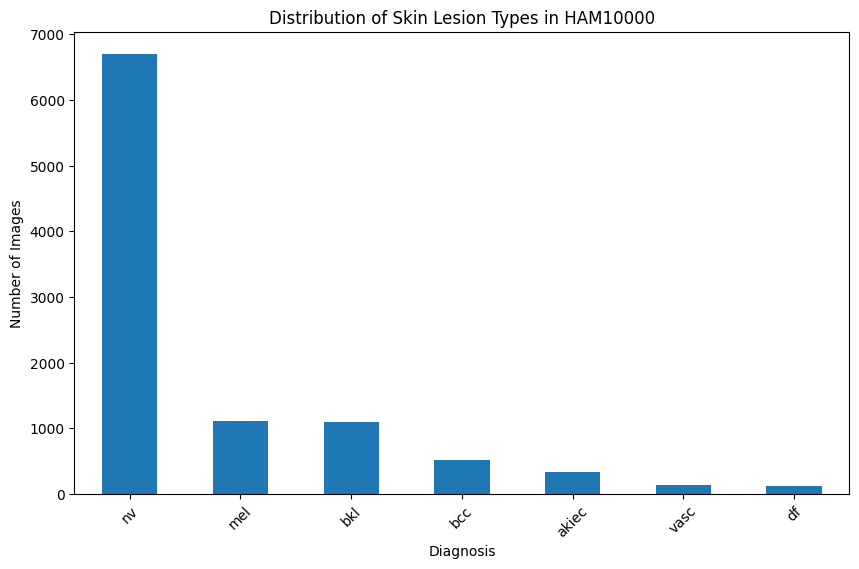

In [ ]:
# Visualize the distribution of lesion types

# Count images in each diagnosis category
diagnosis_counts = metadata["dx"].value_counts()

# Create a bar graph
plt.figure(figsize=(10,6))

diagnosis_counts.plot(kind="bar")

plt.title("Distribution of Skin Lesion Types in HAM10000")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)

plt.show()

In [ ]:
# Create the table using Pandas
# Count the number of images for each diagnosis
diagnosis_counts = metadata["dx"].value_counts()

# Create a table
diagnosis_table = pd.DataFrame({
    "Diagnosis": diagnosis_counts.index,
    "Number of Images": diagnosis_counts.values
})

# Calculate percentage of total images
diagnosis_table["Percentage (%)"] = (
    diagnosis_table["Number of Images"] / len(metadata) * 100
).round(2)

# Define the full diagnosis names
diagnosis_names = {
    "nv": "Melanocytic Nevi",
    "mel": "Melanoma",
    "bkl": "Benign Keratosis",
    "bcc": "Basal Cell Carcinoma",
    "akiec": "Actinic Keratoses / Intraepithelial Carcinoma",
    "vasc": "Vascular Lesions",
    "df": "Dermatofibroma"
}

# Replace abbreviations with full names
diagnosis_table["Diagnosis"] = (
    diagnosis_table["Diagnosis"].map(diagnosis_names)
)

# Display the table
diagnosis_table

,Diagnosis,Number of Images,Percentage (%)
0,Melanocytic Nevi,6705,66.95
1,Melanoma,1113,11.11
2,Benign Keratosis,1099,10.97
3,Basal Cell Carcinoma,514,5.13
4,Actinic Keratoses / Intraepithelial Carcinoma,327,3.27
5,Vascular Lesions,142,1.42
6,Dermatofibroma,115,1.15


In [ ]:
# Checking for missing data and duplicates
# Check the size of the dataset
print("Dataset shape:", metadata.shape)
      # returns the number of rows and columns

# Check for missing values in each column
print("\nMissing values:")
print(metadata.isnull().sum())
      # counts missing valyes in each column

# Check for duplicate image IDs
print("\nDuplicate image IDs:")
print(metadata["image_id"].duplicated().sum())
      # checks whether an image ID appears more than once

# Check how many unique lesions exist
print("\nUnique lesions:")
print(metadata["lesion_id"].nunique())
      # counts the number of unique lesions
      # ** VERY IMPORTANT!!!

Dataset shape: (10015, 8)

Missing values:
lesion_id        0
image_id         0
dx               0
dx_type          0
age             57
sex              0
localization     0
dataset          0
dtype: int64

Duplicate image IDs:
0

Unique lesions:
7470


In [ ]:
# Create a summary table of missing values
missing_table = pd.DataFrame({
    "Variable": metadata.columns,
    "Missing Values": metadata.isnull().sum().values,
    "Percentage Missing (%)": (
        metadata.isnull().sum().values / len(metadata) * 100
    ).round(2)
})

# Display the formatted table
missing_table.style.format({
    "Percentage Missing (%)": "{:.2f}%"
}).set_caption(
    "Table 2. Missing Values in HAM10000 Metadata"
)

,Variable,Missing Values,Percentage Missing (%)
0,lesion_id,0,0.00%
1,image_id,0,0.00%
2,dx,0,0.00%
3,dx_type,0,0.00%
4,age,57,0.57%
5,sex,0,0.00%
6,localization,0,0.00%
7,dataset,0,0.00%


In [ ]:
# Define benign and malignant categories

# Melanoma (mel) -> malignant
# Basal cell carcinoma (bcc) -> malignant
# Melanocytic nevi (nv) -> benign
# Benign keratosis (bkl) -> benign
# Dermatofibroma (df) -> benign
# Vascular lesions (vasc) -> benign
# Actinic keratoses / intraepithelial carcinoma (akiec) -> exclude, initially.
    # this contains both premalignant and in-situ lesions


# this would leave:
  # 8,061 Benign images (83.21%)
  # 1,627 Malignant images (16.79%)

In [ ]:
# This code creates a separate DataFrame called metadata_binary, preserving the original metadata DataFrame
# Then, it assigns the classifications


# Create a dictionary for binary classification
classification_map = {
    "mel": "Malignant",
    "bcc": "Malignant",
    "nv": "Benign",
    "bkl": "Benign",
    "df": "Benign",
    "vasc": "Benign"
}
        # assigns each diagnosis to either benign or malignant

# Creates a copy of the original metadata
metadata_binary = metadata.copy()
        # preserves your original metadata

# Assign benign or malignant labels
metadata_binary["classification"] = (
    metadata_binary["dx"].map(classification_map)
)
        # creates a new classification column

# Exclude categories without a binary label
metadata_binary = metadata_binary.dropna(
    subset=["classification"]
).copy()
        # removes rows without an assigned classification, which should only be the akiec category

In [ ]:
# Count images in each binary classification
binary_counts = metadata_binary["classification"].value_counts()

# Create a summary table
binary_table = pd.DataFrame({
    "Classification": binary_counts.index,
    "Number of Images": binary_counts.values
})

# Calculate percentages
binary_table["Percentage (%)"] = (
    binary_table["Number of Images"]
    / len(metadata_binary) * 100
).round(2)

# Display formatted table
binary_table.style.format({
    "Number of Images": "{:,}",
    "Percentage (%)": "{:.2f}%"
}).set_caption(
    "Table 3. Distribution of Benign and Malignant Skin Lesions"
)

,Classification,Number of Images,Percentage (%)
0,Benign,"8,061",83.21%
1,Malignant,"1,627",16.79%


## 2. Image integrity and metadata matching

The downloaded folders contained eight extra files with a ` (1)` filename suffix. We checked that each corresponded to an image already listed in the metadata and excluded the extra copies from matching.


# 2. Load and sort the JPEG Images

In [ ]:
# Check the image ZIP files
# List the files stored in the ENGG680 folder
import os

folder_path = "/content/drive/MyDrive/ENGG680"

# Display the exact filenames
for file in os.listdir(folder_path):
  print(repr(file))

'ENGG 680 Threshold Optimization.ipynb'
'HAM10000_metadata.csv'
'HAM10000_images_part_1'
'HAM10000_images_part_2'
'HAM10000_images'
'HAM10000_Splits'
'resnet18_best_initial.pt'
'resnet18_best_finetuned.pt'
'resnet18_finetune_recovery.pt'
'resnet18_calibration_settings.json'
'resnet18_best_augmented.pt'
'resnet18_augmented_recovery.pt'
'resnet18_augmented_calibration_settings.json'
'resnet18_augmented_referral_analysis.csv'
'Final_Test_Results'
'ENGG 680 Original Data Processing.ipynb'
'ENGG 680 Final Model.ipynb'
'Model_Optimization'
'ENGG 680 Model Optimization.ipynb'


In [ ]:
# Check whether Part 1 and Part 2 are folders
for part in [1, 2]:

  path = os.path.join(
      folder_path,
      f"HAM10000_images_part_{part}"
  )

  print(f"Part {part}:")
  print("Is a folder:", os.path.isdir(path))
  print("Is a file:", os.path.isfile(path))
  print()

Part 1:
Is a folder: True
Is a file: False

Part 2:
Is a folder: True
Is a file: False



In [ ]:
# Count the images in both folders

# Define the two image folders
image_folders = [
    os.path.join(folder_path, "HAM10000_images_part_1"),
    os.path.join(folder_path, "HAM10000_images_part_2")
]

# Create an empty list to store image paths
image_paths = []

# Search both folders for JPEG images
for folder in image_folders:
  for root, dirs, files in os.walk(folder):
    for file in files:
      if file.lower().endswith((".jpg", ".jpeg")):
        image_paths.append(os.path.join(root, file))

# Dislay the total number of images
print("Total images found:", len(image_paths))

Total images found: 10023


**Image integrity finding:** Eight extra filenames were detected; investigate whether these are duplicated downloads.


In [ ]:
# Check for duplicate image filenames

# Extract image IDs from the filenames
image_ids = [
    os.path.splitext(os.path.basename(path))[0]
    for path in image_paths
]

# Count duplicate image IDs
image_counts = pd.Series(image_ids).value_counts()

# Display duplicate image IDs
duplicate_images = image_counts[image_counts > 1]

print("Duplicate image IDs:", len(duplicate_images))
print("Extra file copies:", (duplicate_images - 1).sum())

# Display duplicated images
print(duplicate_images)

Duplicate image IDs: 0
Extra file copies: 0
Series([], Name: count, dtype: int64)


In [ ]:
# Identify the eight additional images

# Get image IDs from the original metadata
metadata_ids = set(metadata["image_id"])

# Get image IDs from the image folders
folder_ids = set(image_ids)

# Identify images not included in the metadata
extra_images = folder_ids - metadata_ids

# Identify metadata records without matching images
missing_images = metadata_ids - folder_ids

# Display the results
print("Unique image IDs found:", len(folder_ids))
print("Images not in metadata:", len(extra_images))
print("Metadata images not found:", len(missing_images))

print("\nExtra image IDs:")
print(sorted(extra_images))

print("\nMissing image IDs:")
print(sorted(missing_images))

Unique image IDs found: 10023
Images not in metadata: 8
Metadata images not found: 0

Extra image IDs:
['ISIC_0024583 (1)', 'ISIC_0024597 (1)', 'ISIC_0025689 (1)', 'ISIC_0025845 (1)', 'ISIC_0026394 (1)', 'ISIC_0027049 (1)', 'ISIC_0028385 (1)', 'ISIC_0029064 (1)']

Missing image IDs:
[]


The eight extra files had a ` (1)` suffix, suggesting duplicate downloads rather than additional metadata records. The next check verifies the corresponding original IDs.


In [ ]:
# Verify that the original image IDs exist in your metadata

# Remove the " (1)" suffix from extra image IDs
original_ids = [
    image_id.replace(" (1)", "")
    for image_id in extra_images
]

# Check whether the original IDs exist in the metadata
for image_id in original_ids:
    print(image_id, image_id in metadata_ids)

ISIC_0024583 True
ISIC_0025845 True
ISIC_0029064 True
ISIC_0025689 True
ISIC_0024597 True
ISIC_0026394 True
ISIC_0028385 True
ISIC_0027049 True


All eight original image IDs were present in the metadata, so the duplicate copies were excluded from the image-to-metadata mapping.


# Matching the images to the benign and malignant classifications

In [ ]:
# Back to matching the images to the benign and malignant classifications

# Create a dictionary matching image IDs to file paths
image_path_map = {
    os.path.splitext(os.path.basename(path))[0]: path
    for path in image_paths
    if os.path.splitext(os.path.basename(path))[0] in metadata_ids
}

# Match image paths to the binary classification dataset
metadata_binary["image_path"] = (
    metadata_binary["image_id"].map(image_path_map)
)

# Check for missing image paths
print("Images without matching files:",
      metadata_binary["image_path"].isnull().sum())

# Display the first five rows
metadata_binary[
    ["image_id", "dx", "classification", "image_path"]
].head()

Images without matching files: 0


,image_id,dx,classification,image_path
0,ISIC_0027419,bkl,Benign,/content/drive/MyDrive/ENGG680/HAM10000_images...
1,ISIC_0025030,bkl,Benign,/content/drive/MyDrive/ENGG680/HAM10000_images...
2,ISIC_0026769,bkl,Benign,/content/drive/MyDrive/ENGG680/HAM10000_images...
3,ISIC_0025661,bkl,Benign,/content/drive/MyDrive/ENGG680/HAM10000_images...
4,ISIC_0031633,bkl,Benign,/content/drive/MyDrive/ENGG680/HAM10000_images...


## 3. Lesion-level training, validation, and test split

The split is performed by **lesion ID**, not individual image, to avoid placing images of the same lesion in different datasets. This was a key data-leakage safeguard.


**Split plan:** approximately 70% training, 15% validation, and 15% test, assigned at the lesion level to prevent leakage.
1. Training set (70%) - used to train the CNN
2. Validation set (15%) - used to tune the model and monitor its performance
3. Testing set (15%) - used to evaluate your final model on unseen data


In [ ]:
# Spliting the images into training, validaiton, and testing sets

from sklearn.model_selection import train_test_split

# Check that all images have matching file paths
assert metadata_binary["image_path"].notna().all()

#Verify each lesion has only one classification
assert(
    metadata_binary.groupby("lesion_id")["classification"]
    .nunique().max() == 1
)

# Create a table containing each unique lesions and its classification
unique_lesions = metadata_binary[
    ["lesion_id", "classification"]
  ].drop_duplicates()

# Split lesions into 70% training and 30% remaining
train_lesions, remaining_lesions = train_test_split(
    unique_lesions,
    test_size=0.30,
    random_state=42,
    stratify=unique_lesions["classification"]
)

#Split remaining lesions into 15% validation and 15% testing
val_lesions, test_lesions = train_test_split(
    remaining_lesions,
    test_size=0.50,
    random_state=42,
    stratify=remaining_lesions["classification"]
)

# Match all images to their assigned lesion groups
train_df = metadata_binary[
    metadata_binary["lesion_id"].isin(train_lesions["lesion_id"])
].copy()

val_df = metadata_binary[
    metadata_binary["lesion_id"].isin(val_lesions["lesion_id"])
].copy()

test_df = metadata_binary[
    metadata_binary["lesion_id"].isin(test_lesions["lesion_id"])
].copy()

# Display the number of images in each dataset
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("Total images:",
      len(train_df) + len(val_df) + len(test_df))

Training images: 6813
Validation images: 1460
Testing images: 1415
Total images: 9688


In [ ]:
# Count benign and malignant distribution

# Count the number of benign and malignant images in each dataset
distribution = pd.DataFrame({
    "Training": train_df["classification"].value_counts(),
    "Validation": val_df["classification"].value_counts(),
    "Testing": test_df["classification"].value_counts()
}).fillna(0).astype(int)

# Display the results
print("Number of images in each classification:")
display(distribution)

Number of images in each classification:


,Training,Validation,Testing
classification,,,
Benign,5673,1209,1179
Malignant,1140,251,236


In [ ]:
# Calculate the percentage of benign and malignant image in each dataset
distribution_percent = distribution.div(
    distribution.sum(axis=0), axis=1
) * 100

# Display percentages rounded to two decimal places
print("Percentage distribution of each classification:")
display(distribution_percent.round(2))

Percentage distribution of each classification:


,Training,Validation,Testing
classification,,,
Benign,83.27,82.81,83.32
Malignant,16.73,17.19,16.68


In [ ]:
# Check for data leakage
# Verify no lesion overlap between datasets
# Identify unique lesion IDs in each dataset
train_ids = set(train_df["lesion_id"])
val_ids = set(val_df["lesion_id"])
test_ids = set(test_df["lesion_id"])

# Check for overlapping lesion IDs
train_val_overlap = train_ids.intersection(val_ids)
train_test_overlap = train_ids.intersection(test_ids)
val_test_overlap = val_ids.intersection(test_ids)

# Display results
print("Training and Validation overlap:", len(train_val_overlap))
print("Training and Testing overlap:", len(train_test_overlap))
print("Validation and Testing overlap:", len(val_test_overlap))

# Confirm that no lesion appears in more than one dataset
assert len(train_val_overlap) == 0
assert len(train_test_overlap) == 0
assert len(val_test_overlap) == 0

# Confirm that all images were assigned exactly once
assert len(train_df) + len(val_df) + len(test_df) == len(metadata_binary)

print("All checks passed! No lesion-level data leakage detected.")


Training and Validation overlap: 0
Training and Testing overlap: 0
Validation and Testing overlap: 0
All checks passed! No lesion-level data leakage detected.


In [ ]:
# Identify unique lesion IDs
train_ids = set(train_df["lesion_id"])
val_ids = set(val_df["lesion_id"])
test_ids = set(test_df["lesion_id"])

# Check for overlapping lesions
print("Training and Validation overlap:",
      len(train_ids & val_ids))

print("Training and Testing overlap:",
      len(train_ids & test_ids))

print("Validation and Testing overlap:",
      len(val_ids & test_ids))

# Confirm no overlap
assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

# Confirm all images are accounted for
assert len(train_df) + len(val_df) + len(test_df) == len(metadata_binary)

print("All checks passed! No lesion-level data leakage detected.")

Training and Validation overlap: 0
Training and Testing overlap: 0
Validation and Testing overlap: 0
All checks passed! No lesion-level data leakage detected.


# Save the training, validation, and testing datasets to Google Drive

In [ ]:
# Create a folder for your datasets
# Save the training, validation, and testing datasets
import os

# Define the folder where the datasets will be saved
output_folder = "/content/drive/MyDrive/ENGG680/HAM10000_Splits"

# Create the folder where the datasets will be saved
os.makedirs(output_folder, exist_ok=True)

print("Folder created successfully!")

Folder created successfully!


In [ ]:
# Save the three datasets
# Save the training dataset
train_df.to_csv(
    os.path.join(output_folder, "train.csv"),
    index=False
)

# Save the validation dataset
val_df.to_csv(
    os.path.join(output_folder, "validation.csv"),
    index=False
)

# Save testing dataset
test_df.to_csv(
    os.path.join(output_folder, "test.csv"),
    index=False
)

print("All three datasets saved successfully!")

All three datasets saved successfully!


In [ ]:
# Verifying the files were saved
# Check that all three CSV files exist
print(os.listdir(output_folder))

# Reload the training dataset to verify
train_check = pd.read_csv(
    os.path.join(output_folder, "train.csv")
)

print("Training images saved:", len(train_check))
display(train_check.head())

['validation.csv', 'test.csv', 'train.csv']
Training images saved: 6813


,lesion_id,image_id,dx,dx_type,age,sex,localization,dataset,classification,image_path
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,vidir_modern,Benign,/content/drive/MyDrive/ENGG680/HAM10000_images...
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,vidir_modern,Benign,/content/drive/MyDrive/ENGG680/HAM10000_images...
2,HAM_0004234,ISIC_0029396,bkl,histo,85.0,female,chest,vidir_modern,Benign,/content/drive/MyDrive/ENGG680/HAM10000_images...
3,HAM_0004234,ISIC_0025984,bkl,histo,85.0,female,chest,vidir_modern,Benign,/content/drive/MyDrive/ENGG680/HAM10000_images...
4,HAM_0001949,ISIC_0025767,bkl,histo,70.0,male,trunk,vidir_modern,Benign,/content/drive/MyDrive/ENGG680/HAM10000_images...


## 4. Image preprocessing and PyTorch data loaders


# Image Preprocessing
Preparing the JPEG images for CNN using PyTorch and Torchvision

In [ ]:
# Import the required libraries for preprocessing
import torch
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt

In [ ]:
# Define image preprocessing transformations

# Define preprocessing for all images
image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image preprocessing transformations created successfully!")

Image preprocessing transformations created successfully!


In [ ]:
# Test preprocessing on one image

# Select the first image from the training dataset
image_path = train_df.iloc[0]["image_path"]

# Open the original JPEG image
original_image = Image.open(image_path).convert("RGB")

# Apply preprocessing transformations
processed_image = image_transform(original_image)

# Check the image dimensions
print("Original image dimensions:", original_image.size)
print("Processed image tensor shape:", processed_image.shape)


Original image dimensions: (600, 450)
Processed image tensor shape: torch.Size([3, 224, 224])


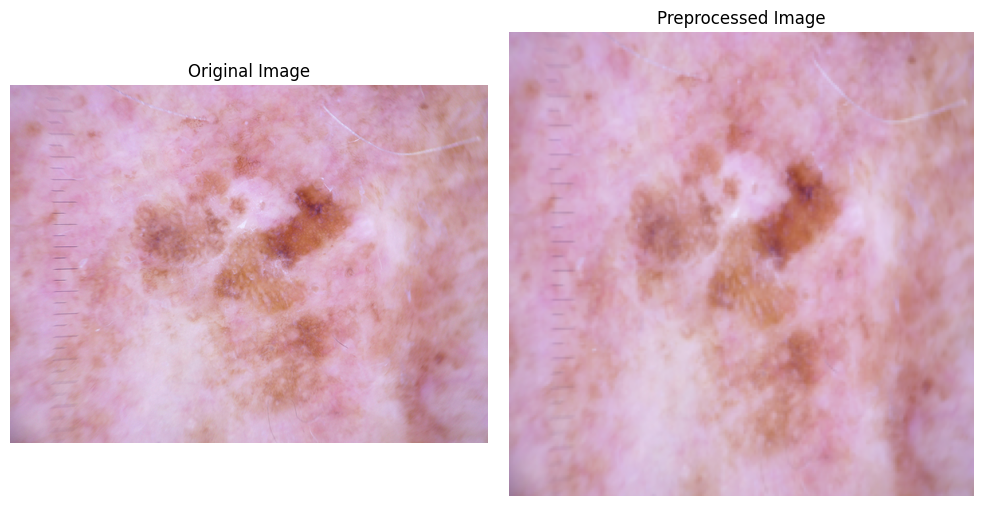

In [ ]:
# Compare the original and preprocessed images

# Reverse normalization for visualization
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

display_image = processed_image * std + mean

# Convert tensor to image format for Matplotlib
display_image = display_image.permute(1, 2, 0).numpy()

# Display images side by side
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(display_image.clip(0, 1))
plt.title("Preprocessed Image")
plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
# Verify the preprocessing was successful

# Check tensor dimensions
assert processed_image.shape == (3, 224, 224)

# Check that all pixel values are finite
assert torch.isfinite(processed_image).all()

# Display tensor information
print("Tensor shape:", processed_image.shape)
print("Tensor data type:", processed_image.dtype)
print("Minimum normalized value:", processed_image.min().item())
print("Maximum normalized value:", processed_image.max().item())

print("Image preprocessing verified successfully!")

Tensor shape: torch.Size([3, 224, 224])
Tensor data type: torch.float32
Minimum normalized value: -1.160364031791687
Maximum normalized value: 2.5877127647399902
Image preprocessing verified successfully!


In [ ]:
# Create a PyTorch Dataset

from torch.utils.data import Dataset, DataLoader
from PIL import Image

In [ ]:
# Create custom HAM10000 Dataset

class HAM10000Dataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        # Get image file path
        image_path = self.dataframe.iloc[idx]["image_path"]

        # Open image
        image = Image.open(image_path).convert("RGB")

        # Apply preprocessing
        if self.transform:
            image = self.transform(image)

        # Convert classification into numerical label
        classification = self.dataframe.iloc[idx]["classification"]

        label = 0 if classification == "Benign" else 1

        return image, label

In [ ]:
# Define preprocessing with augmentation for training images
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),

    # Each flip has a 50% chance of happening
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),

    transforms.ToTensor(),

    # Use the same normalization as before
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [ ]:
# Create training, validation and testing datasets

# Training images: include random flips
train_dataset = HAM10000Dataset(
    train_df, transform=train_transform
)

# Validation images: use the original preprocessing without random flips
val_dataset = HAM10000Dataset(
    val_df, transform=image_transform
)

# Testing images: use the original preprocessing without random flips
test_dataset = HAM10000Dataset(
    test_df, transform=image_transform
)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Testing dataset:", len(test_dataset))

Training dataset: 6813
Validation dataset: 1460
Testing dataset: 1415


# Create PyTorch DataLoaders
organize the images into smaller batches and feed them to our CNN during training, validation, and testing.

In [ ]:
# Create Dataloaders

from torch.utils.data import DataLoader

# Define batch size
batch_size = 32

# Training DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

# Validation DataLoader
val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

# Testing DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

print("DataLoaders created successfully!")

DataLoaders created successfully!


## 5. Initial ResNet-18 transfer-learning model

First, train the new classification head with the pretrained feature extractor frozen. The saved checkpoint is used in the next phase. Training is computationally expensive; retain the outputs and checkpoint when preparing the submission.


# Setting up ResNet-18


Next we will load ResNet-18 and adapt its final layer for our two categories (benign and malignant)

In [ ]:
# Load pretrained ResNet-18
import torch
import torch.nn as nn
from torchvision import models

# Set a seed to make the new layer's initialization reproducible
torch.manual_seed(42)

# Load weights learned from ImageNet
model = models.resnet18(
    weights=models.ResNet18_Weights.IMAGENET1K_V1
)

# Freeze all existing weights
for parameter in model.parameters():
    parameter.requires_grad = False

# Replace the original classification layer
# The new layer is trainable by default
model.fc = nn.Linear(model.fc.in_features, 2)

# Use a GPU if available; otherwise use the CPU
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
model = model.to(device)

# Check which paramters can learn
print("Device:", device)
print("Trainable parameters:")

for name, parameter in model.named_parameters():
  if parameter.requires_grad:
    print(name)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 170MB/s]


Device: cuda
Trainable parameters:
fc.weight
fc.bias


The below cell prepares training but does not start it yet

In [ ]:
# Account for class imbalance using TRAINING data only

# Count images in label order: benign = 0, malignant = 1
class_counts = train_df["classification"].value_counts()

counts = torch.tensor(
    [class_counts["Benign"], class_counts["Malignant"]],
    dtype=torch.float32
)

# Less common classes receive larger weights
class_weights = counts.sum() / (2 * counts)
class_weights = class_weights.to(device)

# Define how prediction errors will be measured
  # criterion measures prediction errors. For the same prediction error,
  # a malignant example recieves about five times the weight of a benign example
criterion = nn.CrossEntropyLoss(weight=class_weights)

# Define how the new classification layer will learn
  # optimizer -> adjusts the new final layer's weights to reduce those errors
  # lr=0.001 -> learning rate, which controls the size of those adjustments
optimizer = torch.optim.Adam(
    model.fc.parameters(),
    lr=0.001
)

print("Benign weight:", round(class_weights[0].item(), 3))
print("Malignant weight:", round(class_weights[1].item(), 3))
print("Loss function and optimizer are ready.")

Benign weight: 0.6
Malignant weight: 2.988
Loss function and optimizer are ready.


Training the new classification layer

***Note: I commented the below cell as it has already ran and takes substantial time.

In [ ]:
# import copy
# import torch
# from sklearn.metrics import balanced_accuracy_score, recall_score
# from tqdm.auto import tqdm

# num_epochs = 3
# best_val_score = -1
# history = []

# # Save the best model to Google Drive
# checkpoint_path = (
#     "/content/drive/MyDrive/ENGG680/"
#     "resnet18_best_initial.pt"
# )

# for epoch in range(num_epochs):

#     # Keep the frozen feature extractor fixed,
#     # including its batch-normalization statistics
#     model.eval()
#     model.fc.train()

#     training_loss_sum = 0.0
#     training_weight_sum = 0.0

#     # Train the new classification layer
#     for images, labels in tqdm(
#         train_loader,
#         desc=f"Epoch {epoch + 1}/{num_epochs} - Training"
#     ):
#         images = images.to(device)
#         labels = labels.to(device)

#         optimizer.zero_grad()

#         # Make predictions and calculate the error
#         outputs = model(images)
#         loss = criterion(outputs, labels)

#         # Update only the new classification layer
#         loss.backward()
#         optimizer.step()

#         # Accumulate the weighted loss
#         batch_weight = class_weights[labels].sum().item()
#         training_loss_sum += loss.item() * batch_weight
#         training_weight_sum += batch_weight

#     # Evaluate without updating the model
#     model.eval()

#     validation_predictions = []
#     validation_labels = []

#     with torch.no_grad():
#         for images, labels in tqdm(
#             val_loader,
#             desc=f"Epoch {epoch + 1}/{num_epochs} - Validation"
#         ):
#             images = images.to(device)

#             outputs = model(images)
#             predictions = outputs.argmax(dim=1)

#             validation_predictions.extend(
#                 predictions.cpu().tolist()
#             )
#             validation_labels.extend(labels.tolist())

#     # Calculate validation metrics
#     balanced_accuracy = balanced_accuracy_score(
#         validation_labels,
#         validation_predictions
#     )

#     malignant_recall = recall_score(
#         validation_labels,
#         validation_predictions,
#         pos_label=1,
#         zero_division=0
#     )

#     training_loss = training_loss_sum / training_weight_sum

#     # Record results for this epoch
#     history.append({
#         "epoch": epoch + 1,
#         "training_loss": training_loss,
#         "validation_balanced_accuracy": balanced_accuracy,
#         "validation_malignant_recall": malignant_recall
#     })

#     print(
#         f"Epoch {epoch + 1}/{num_epochs} | "
#         f"Training loss: {training_loss:.4f} | "
#         f"Validation balanced accuracy: {balanced_accuracy:.3f} | "
#         f"Malignant recall: {malignant_recall:.3f}",
#         flush=True
#     )

#     # Save the model with the best validation balanced accuracy
#     if balanced_accuracy > best_val_score:
#         best_val_score = balanced_accuracy
#         best_model_weights = copy.deepcopy(model.state_dict())
#         torch.save(best_model_weights, checkpoint_path)

# # Restore the best model from these three epochs
# model.load_state_dict(best_model_weights)

# print("Training complete. Best model restored and saved.")

# What are the layers?
Layers are the processing stages inside the neural network. Each stage receives numbers from the previous stage, processes them, and passes the result onward.

The image starts as numbers representing its pixels. As it passes through ResNet-18, those numbers become descriptions of visual patterns.




Part of the model   ->    What it does

Early layers -> Detect simple patterns, such as edges and colour changes

Middle layers -> Combine simple patterns into textures and shapes

Latter layers -> Combine those patterns into more complex image features

Final classification layer -> Uses those features to produce benign and malignant scores





These patterns are learned from examples - you don't manually program each layer to recognize a particular feature

In the current training, only the final classification layer is learning. All pretrained layers still process the images, but their weights stay frozen

Think of this as keeping an existing image-analysis system and teaching it a new final decision: "Based on these image features, should this be classified as benign or malignant?"

Later, during the fine-tuning stage, we will allow the last group of pretrained layers to learn too, so their feature detection can adapt more closely to the skin lesion images

## 6. Fine-tuning and initial validation experiments

Fine-tune the final ResNet-18 feature block (`layer4`) and classification head. Early experiments with a 95% acceptance threshold led to high referral rates and motivated calibration and further augmentation. These validation experiments are exploratory, not independent test results.


# Next step is fine-tuning: allowing ResNet-18's last feature-extraction block to learn, then checking whether that improves validation performance

In [ ]:
# Check whether GPU is available
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cuda


In [ ]:
# # Step 15.2: Load the saved initial ResNet18 model

# import torch
# import torch.nn as nn
# from torchvision import models

# # Select GPU if available
# device = torch.device(
#     "cuda" if torch.cuda.is_available() else "cpu"
# )

# # Define the saved model location
# checkpoint_path = (
#     "/content/drive/MyDrive/ENGG680/"
#     "resnet18_best_initial.pt"
# )

# # Load the saved model weights
# checkpoint = torch.load(
#     checkpoint_path,
#     map_location="cpu",
#     weights_only=True
# )

# # Recreate the ResNet18 architecture
# model = models.resnet18(weights=None)

# # Replace the final classification layer
# model.fc = nn.Linear(
#     model.fc.in_features,
#     2
# )

# # Load the previously trained weights
# model.load_state_dict(checkpoint)

# # Move the model to GPU if available
# model = model.to(device)

# print("Device:", device)
# print("Initial ResNet18 weights loaded successfully!")

In [ ]:
# # Step 15.3 - Unfreeze the final feature-extraction block
# # Unfreeze layer4 and the classification layer

# # Freeze all model paramters
# for param in model.parameters():
#   param.requires_grad = False

# # Unfreeze the final feature-extraction block
# for param in model.layer4.parameters():
#   param.requires_grad = True

# # Unfreeze the final classification layer
# for param in model.fc.parameters():
#   param.requires_grad = True

# # Verify which parameters are trainable
# trainable = [
#     name for name, param in model.named_parameters()
#     if param.requires_grad
# ]

# print("Number of ttrainable parameter tensors:", len(trainable))
# print("Trainable layers:")
# for name in trainable:
#   print(name)

In [ ]:
# # Step 15.4 - Configure the optimizer
# import torch.optim as optim

# optimizer = optim.Adam([
#     {"params": model.layer4.parameters(), "lr": 1e-5},
#     {"params": model.fc.parameters(), "lr": 1e-4}
# ])

# print("Fine-tuning optimizer created succesfully!")
# print("Layer4 learning rate:", optimizer.param_groups[0]["lr"])
# print("FC learning rate:", optimizer.param_groups[1]["lr"])

In [ ]:
# # Step 15.6 - Configure weighted cross-entropy loss

# # Because our dataset contains more benign than malignant images, we need
# # the model to account for this class imbalance

# # We will be using weighted cross-entropy loss which will assign more
# # importance to mistakes involving the less represented class to account for the imbalance

# import torch
# import torch.nn as nn

# # Count training images in each class
# class_counts = train_df["classification"].value_counts()

# n_benign = class_counts["Benign"]
# n_malignant = class_counts["Malignant"]
# n_total = n_benign + n_malignant

# # Calculate balanced class weights
# weight_benign = n_total / (2 * n_benign)
# weight_malignant = n_total / (2 * n_malignant)

# # Create weight tensor in correct class order
# class_weights = torch.tensor(
#     [weight_benign, weight_malignant],
#     dtype=torch.float32
# ).to(device)

# # Define weighted cross-entropy loss
# criterion = nn.CrossEntropyLoss(
#     weight=class_weights
# )

# print("Benign weight:", round(weight_benign, 4))
# print("Malignant weight:", round(weight_malignant, 4))
# print("Weighted corss-entropy loss configured!")

In [ ]:
# # Check image-loading speed
# # Step 2: Measure image loading speed

# import time

# start_time = time.time()

# images, labels = next(iter(train_loader))

# elapsed_time = time.time() - start_time

# print(f"Time to load one batch: {elapsed_time:.2f} seconds")
# print("Image batch shape:", images.shape)
# print("Label batch shape:", labels.shape)

### Training efficiency adjustment

Loading images directly from Drive was slow, so the images were copied to Colab's temporary local storage for training. The local copy must be recreated after a runtime reset.


So this means it is taking an incredible long time to load the images so we're going to move the images to Colab's local storgae to hopefully speed up the process

# Moving images to local storage

In [ ]:
# # Step 1 - Copy the HAM10000 image folders to local storage

# import os
# import shutil
# import time

# # Original Google Drive folder
# drive_folder = "/content/drive/MyDrive/ENGG680"

# # Temporary local storage folder
# local_folder = "/content/HAM10000"

# os.makedirs(local_folder, exist_ok=True)

# # Image folders
# image_folders = [
#     "HAM10000_images_part_1",
#     "HAM10000_images_part_2"
# ]

# start_time = time.time()

# for folder in image_folders:

#     source = os.path.join(drive_folder, folder)
#     destination = os.path.join(local_folder, folder)

#     if not os.path.isdir(source):
#         raise FileNotFoundError(
#             f"Source folder not found: {source}"
#         )

#     print(f"Copying {folder}...", flush=True)

#     # Copy images to local storage
#     shutil.copytree(
#         source,
#         destination,
#         dirs_exist_ok=True
#     )

#     print(f"Finished copying {folder}!")

# elapsed_time = time.time() - start_time

# print("\nBoth image folders copied!")
# print(f"Total copying time: {elapsed_time / 60:.2f} minutes")

# # Verify local image counts
# for folder in image_folders:

#     folder_path = os.path.join(local_folder, folder)

#     image_count = sum(
#         filename.lower().endswith((".jpg", ".jpeg", ".png"))
#         for filename in os.listdir(folder_path)
#     )

#     print(f"{folder}: {image_count} images")

In [ ]:
# # Step 2 - Updating image paths to local storage
# import os

# # Original and new image locations
# old_path = "/content/drive/MyDrive/ENGG680/"
# new_path = "/content/HAM10000/"

# # Update paths while preserving dataset assignments
# train_df = train_df.copy()
# val_df = val_df.copy()
# test_df = test_df.copy()

# for df in [train_df, val_df, test_df]:
#     df["image_path"] = df["image_path"].str.replace(
#         old_path,
#         new_path,
#         regex=False
#     )

# # Verify every image exists locally
# for name, df in [
#     ("Training", train_df),
#     ("Validation", val_df),
#     ("Testing", test_df)
# ]:
#     missing = sum(
#         not os.path.isfile(path)
#         for path in df["image_path"]
#     )

#     print(f"{name}: {len(df)} images")
#     print(f"Missing local images: {missing}")
#     print()

# print("Example updated training path:")
# print(train_df["image_path"].iloc[0])

In [ ]:
# # Step 3 - Recreate the datasets and DataLoaders
# # using images stored locally in Colab

# from torch.utils.data import DataLoader

# # Recreate datasets using updated local paths
# train_dataset = HAM10000Dataset(
#     train_df,
#     transform=image_transform
# )

# val_dataset = HAM10000Dataset(
#     val_df,
#     transform=image_transform
# )

# test_dataset = HAM10000Dataset(
#     test_df,
#     transform=image_transform
# )

# # Recreate DataLoaders
# batch_size = 32

# train_loader = DataLoader(
#     train_dataset,
#     batch_size=batch_size,
#     shuffle=True,
#     num_workers=2,
#     pin_memory=True
# )

# val_loader = DataLoader(
#     val_dataset,
#     batch_size=batch_size,
#     shuffle=False,
#     num_workers=2,
#     pin_memory=True
# )

# test_loader = DataLoader(
#     test_dataset,
#     batch_size=batch_size,
#     shuffle=False,
#     num_workers=2,
#     pin_memory=True
# )

# print("Local DataLoaders created successfully!")
# print("Training batches:", len(train_loader))
# print("Validation batches:", len(val_loader))
# print("Testing batches:", len(test_loader))

In [ ]:
# # Step 4: Measure local image-loading speed

# import time

# # Measure two batches to account for initial worker startup
# loader_iterator = iter(train_loader)

# start_time = time.time()
# images, labels = next(loader_iterator)
# first_batch_time = time.time() - start_time

# start_time = time.time()
# images, labels = next(loader_iterator)
# second_batch_time = time.time() - start_time

# print(f"First batch: {first_batch_time:.2f} seconds")
# print(f"Second batch: {second_batch_time:.2f} seconds")
# print("Image batch shape:", images.shape)
# print("Label batch shape:", labels.shape)

***Note: I commented the below cell as it has already ran and we have saved necessary data.

In [ ]:
# # Step 15.7B - Fine-tune ResNet18 with checkpoint recovery

# import os
# import torch
# import pandas as pd
# from sklearn.metrics import balanced_accuracy_score, recall_score
# from tqdm.auto import tqdm

# num_epochs = 3

# # Paths for saved models
# save_folder = "/content/drive/MyDrive/ENGG680"

# best_model_path = os.path.join(
#     save_folder, "resnet18_best_finetuned.pt"
# )

# recovery_path = os.path.join(
#     save_folder, "resnet18_finetune_recovery.pt"
# )

# best_val_score = -1.0
# start_epoch = 0
# finetune_history = []

# # Resume if a recovery checkpoint exists
# if os.path.isfile(recovery_path):

#     recovery = torch.load(
#         recovery_path,
#         map_location=device,
#         weights_only=True
#     )

#     model.load_state_dict(recovery["model_state_dict"])
#     optimizer.load_state_dict(recovery["optimizer_state_dict"])

#     start_epoch = recovery["epoch"]
#     best_val_score = recovery["best_val_score"]
#     finetune_history = recovery["history"]

#     print(f"Resuming from epoch {start_epoch + 1}")

# else:
#     print("Starting fine-tuning from initial model.")

# # Fine-tuning loop
# for epoch in range(start_epoch, num_epochs):

#     # Keep frozen layers in evaluation mode
#     model.eval()

#     # Train only layer4 and fc
#     model.layer4.train()
#     model.fc.train()

#     train_loss_sum = 0.0
#     train_weight_sum = 0

#     # Training phase
#     for images, labels in tqdm(
#         train_loader,
#         desc=f"Epoch {epoch + 1}/{num_epochs} - Training"
#     ):

#         images = images.to(device, non_blocking=True)
#         labels = labels.to(device, non_blocking=True)

#         optimizer.zero_grad()

#         outputs = model(images)
#         loss = criterion(outputs, labels)

#         loss.backward()
#         optimizer.step()

#         train_loss_sum += loss.item() * labels.size(0)
#         train_weight_sum += labels.size(0)

#     train_loss = train_loss_sum / train_weight_sum

#     # Validation phase
#     model.eval()

#     val_loss_sum = 0.0
#     val_weight_sum = 0

#     all_labels = []
#     all_predictions = []

#     with torch.no_grad():

#         for images, labels in tqdm(
#             val_loader,
#             desc=f"Epoch {epoch + 1}/{num_epochs} - Validation"
#         ):

#             images = images.to(device, non_blocking=True)
#             labels = labels.to(device, non_blocking=True)

#             outputs = model(images)
#             loss = criterion(outputs, labels)

#             predictions = torch.argmax(outputs, dim=1)

#             val_loss_sum += loss.item() * labels.size(0)
#             val_weight_sum += labels.size(0)

#             all_labels.extend(labels.cpu().tolist())
#             all_predictions.extend(predictions.cpu().tolist())

#     val_loss = val_loss_sum / val_weight_sum

#     val_balanced_accuracy = balanced_accuracy_score(
#         all_labels,
#         all_predictions
#     )

#     val_malignant_recall = recall_score(
#         all_labels,
#         all_predictions,
#         pos_label=1
#     )

#     # Store results
#     finetune_history.append({
#         "epoch": epoch + 1,
#         "train_loss": train_loss,
#         "val_loss": val_loss,
#         "val_balanced_accuracy": val_balanced_accuracy,
#         "val_malignant_recall": val_malignant_recall
#     })

#     print(f"\nEpoch {epoch + 1}/{num_epochs}")
#     print(f"Training Loss: {train_loss:.4f}")
#     print(f"Validation Loss: {val_loss:.4f}")
#     print(f"Validation Balanced Accuracy: {val_balanced_accuracy:.4f}")
#     print(f"Validation Malignant Recall: {val_malignant_recall:.4f}")

#     # Save best-performing model
#     if val_balanced_accuracy > best_val_score:

#         best_val_score = val_balanced_accuracy

#         torch.save(
#             model.state_dict(),
#             best_model_path
#         )

#         print("Best fine-tuned model saved!")

#     # Save recovery checkpoint after every epoch
#     torch.save({
#         "epoch": epoch + 1,
#         "model_state_dict": model.state_dict(),
#         "optimizer_state_dict": optimizer.state_dict(),
#         "best_val_score": best_val_score,
#         "history": finetune_history
#     }, recovery_path)

#     print("Recovery checkpoint saved!")

# print("\nFine-tuning complete!")
# print(f"Best validation balanced accuracy: {best_val_score:.4f}")

# # Display results table
# results_df = pd.DataFrame(finetune_history)
# display(results_df)


In [ ]:
# Step 15.8 - Verify both trained models are saved

import os

initial_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_best_initial.pt"
)

finetuned_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_best_finetuned.pt"
)

print("Initial model exists:", os.path.isfile(initial_path))
print("Fine-tuned model exists:", os.path.isfile(finetuned_path))

if os.path.isfile(initial_path):
    print(
        "Initial model size (MB):",
        round(os.path.getsize(initial_path) / 1e6, 2)
    )

if os.path.isfile(finetuned_path):
    print(
        "Fine-tuned model size (MB):",
        round(os.path.getsize(finetuned_path) / 1e6, 2)
    )

Initial model exists: True
Fine-tuned model exists: True
Initial model size (MB): 44.79
Fine-tuned model size (MB): 44.79


In [ ]:
# # Step 15.9 - Load initial and fine-tuned ResNet18 models

# import torch
# import torch.nn as nn
# from torchvision import models

# # Function to load a saved ResNet18 model
# def load_resnet18(checkpoint_path):

#     # Recreate ResNet18 architecture
#     loaded_model = models.resnet18(weights=None)

#     # Configure binary classification output
#     loaded_model.fc = nn.Linear(
#         loaded_model.fc.in_features,
#         2
#     )

#     # Load trained weights
#     state_dict = torch.load(
#         checkpoint_path,
#         map_location="cpu",
#         weights_only=True
#     )

#     loaded_model.load_state_dict(state_dict)

#     # Move model to GPU
#     loaded_model = loaded_model.to(device)

#     # Set evaluation mode
#     loaded_model.eval()

#     return loaded_model


# # Load initial model
# initial_model = load_resnet18(initial_path)

# # Load best fine-tuned model
# finetuned_model = load_resnet18(finetuned_path)

# print("Initial ResNet18 loaded successfully!")
# print("Fine-tuned ResNet18 loaded successfully!")

# print("\nInitial model device:",
#       next(initial_model.parameters()).device)

# print("Fine-tuned model device:",
#       next(finetuned_model.parameters()).device)

***Note: I commented the below cell as it has already ran and we have saved necessary data.

In [ ]:
# # Step 15.10 - Compare both models on validation data

# import numpy as np
# import pandas as pd
# import torch

# from sklearn.metrics import (
#     accuracy_score,
#     balanced_accuracy_score,
#     precision_score,
#     recall_score,
#     f1_score,
#     roc_auc_score
# )

# from tqdm.auto import tqdm


# def evaluate_model(model, data_loader, model_name):

#     model.eval()

#     all_labels = []
#     all_predictions = []
#     all_probabilities = []

#     total_loss = 0.0
#     total_samples = 0

#     with torch.no_grad():

#         for images, labels in tqdm(
#             data_loader,
#             desc=f"Evaluating {model_name}"
#         ):

#             images = images.to(
#                 device, non_blocking=True
#             )

#             labels = labels.to(
#                 device, non_blocking=True
#             )

#             # Get model outputs
#             outputs = model(images)

#             # Calculate weighted cross-entropy loss
#             loss = criterion(outputs, labels)

#             # Convert outputs to probabilities
#             probabilities = torch.softmax(
#                 outputs, dim=1
#             )[:, 1]

#             # Classify using the default 0.50 threshold
#             predictions = (
#                 probabilities >= 0.50
#             ).long()

#             total_loss += (
#                 loss.item() * labels.size(0)
#             )

#             total_samples += labels.size(0)

#             all_labels.extend(
#                 labels.cpu().numpy()
#             )

#             all_predictions.extend(
#                 predictions.cpu().numpy()
#             )

#             all_probabilities.extend(
#                 probabilities.cpu().numpy()
#             )

#     # Convert results to NumPy arrays
#     all_labels = np.array(all_labels)
#     all_predictions = np.array(all_predictions)
#     all_probabilities = np.array(all_probabilities)

#     # Calculate performance metrics
#     results = {
#         "Model": model_name,

#         "Accuracy": accuracy_score(
#             all_labels, all_predictions
#         ),

#         "Balanced Accuracy": balanced_accuracy_score(
#             all_labels, all_predictions
#         ),

#         "Malignant Recall": recall_score(
#             all_labels,
#             all_predictions,
#             pos_label=1
#         ),

#         "Precision": precision_score(
#             all_labels,
#             all_predictions,
#             pos_label=1,
#             zero_division=0
#         ),

#         "F1 Score": f1_score(
#             all_labels,
#             all_predictions,
#             pos_label=1,
#             zero_division=0
#         ),

#         "ROC-AUC": roc_auc_score(
#             all_labels,
#             all_probabilities
#         ),

#         "Validation Loss": (
#             total_loss / total_samples
#         )
#     }

#     return results, all_labels, all_probabilities


# # Evaluate original ResNet18
# initial_results, initial_labels, initial_probs = (
#     evaluate_model(
#         initial_model,
#         val_loader,
#         "Initial ResNet18"
#     )
# )

# # Evaluate fine-tuned ResNet18
# finetuned_results, finetuned_labels, finetuned_probs = (
#     evaluate_model(
#         finetuned_model,
#         val_loader,
#         "Fine-tuned ResNet18"
#     )
# )

# # Confirm both models evaluated the same labels
# assert np.array_equal(
#     initial_labels,
#     finetuned_labels
# ), "Validation labels do not match!"

# # Create comparison table
# comparison_df = pd.DataFrame([
#     initial_results,
#     finetuned_results
# ])

# display(comparison_df.round(4))

# print("\nBoth models evaluated successfully!")


This above step will help us learn and figure out:

- Balanced accuracy
- Malignant recall
- Precision
- F1 score
- ROC-AUC
- Validation loss

**Validation finding:** Fine-tuning increased malignant recall from approximately 80.48% to 83.67%. This motivated testing calibration and referral rules before finalizing the model.


In [ ]:
# # Step 15.11 - Evaluate the 95% prediction-confidence threshold

# import numpy as np
# import pandas as pd
# from sklearn.metrics import accuracy_score

# # True validation labels
# y_true = np.asarray(finetuned_labels)

# # Predicted probability of malignancy
# p_malignant = np.asarray(finetuned_probs)

# # Predicted probability of benign
# p_benign = 1 - p_malignant

# # Default binary predictions
# predictions = (p_malignant >= 0.50).astype(int)

# # Highest predicted probability for each image
# confidence = np.maximum(p_benign, p_malignant)

# # Require at least 95% confidence
# confidence_threshold = 0.95

# accepted = confidence >= confidence_threshold
# referred = ~accepted

# # Overall counts
# total_images = len(y_true)
# accepted_count = accepted.sum()
# referred_count = referred.sum()

# # Accuracy on accepted predictions
# accepted_accuracy = (
#     accuracy_score(
#         y_true[accepted],
#         predictions[accepted]
#     )
#     if accepted_count > 0
#     else np.nan
# )

# # Malignant lesion counts
# malignant = y_true == 1

# malignant_accepted = (malignant & accepted).sum()
# malignant_referred = (malignant & referred).sum()

# # Malignant lesions incorrectly classified as benign
# malignant_missed = (
#     malignant & accepted & (predictions == 0)
# ).sum()

# results_95 = pd.DataFrame({
#     "Metric": [
#         "Total validation images",
#         "Images classified (>=95% confidence)",
#         "Images referred (<95% confidence)",
#         "Classification coverage (%)",
#         "Accuracy on classified images (%)",
#         "Malignant images classified",
#         "Malignant images referred",
#         "Malignant images incorrectly classified as benign"
#     ],
#     "Value": [
#         total_images,
#         accepted_count,
#         referred_count,
#         round(100 * accepted_count / total_images, 2),
#         round(100 * accepted_accuracy, 2),
#         malignant_accepted,
#         malignant_referred,
#         malignant_missed
#     ]
# })

# display(results_95)

**Early threshold experiment:** A 95% confidence requirement referred many images. This was an exploratory validation result, not the final policy.


In [ ]:
# # Step 15.12 - Calculate calibration metrics
# # We wil use:
#   # Brier score:
#     # measures how closely predicted malignant probabilities match actual outcomes. Lower is better.
#   # Expected Calibration Error (ECE):
#     # Measures the difference between predicted confidence and observed accuracy across probability groups. Lower is better.

# # Step 15.12 - Evaluate probability calibration

# import numpy as np
# import matplotlib.pyplot as plt

# from sklearn.metrics import brier_score_loss
# from sklearn.calibration import calibration_curve

# # Use predictions from our fine-tuned ResNet18
# y_true = np.asarray(finetuned_labels)
# p_malignant = np.asarray(finetuned_probs)

# # Calculate Brier score
# brier = brier_score_loss(y_true, p_malignant)

# # Calculate Expected Calibration Error (ECE)
# def calculate_ece(y_true, probabilities, n_bins=10):

#     bin_edges = np.linspace(0, 1, n_bins + 1)

#     predicted_classes = (
#         probabilities >= 0.5
#     ).astype(int)

#     confidence = np.maximum(
#         probabilities, 1 - probabilities
#     )

#     correct = (predicted_classes == y_true)

#     ece = 0.0

#     for i in range(n_bins):

#         if i == n_bins - 1:
#             mask = (
#                 (confidence >= bin_edges[i]) &
#                 (confidence <= bin_edges[i + 1])
#             )
#         else:
#             mask = (
#                 (confidence >= bin_edges[i]) &
#                 (confidence < bin_edges[i + 1])
#             )

#         if mask.sum() == 0:
#             continue

#         bin_accuracy = correct[mask].mean()
#         bin_confidence = confidence[mask].mean()

#         ece += (
#             mask.mean() *
#             abs(bin_accuracy - bin_confidence)
#         )

#     return ece


# ece = calculate_ece(
#     y_true,
#     p_malignant,
#     n_bins=10
# )

# print(f"Brier Score: {brier:.4f}")
# print(f"Expected Calibration Error: {ece:.4f}")

# # Generate reliability diagram
# fraction_positive, mean_predicted = (
#     calibration_curve(
#         y_true,
#         p_malignant,
#         n_bins=10,
#         strategy="uniform"
#     )
# )

# plt.figure(figsize=(7, 6))

# plt.plot(
#     [0, 1],
#     [0, 1],
#     linestyle="--",
#     label="Perfect calibration"
# )

# plt.plot(
#     mean_predicted,
#     fraction_positive,
#     marker="o",
#     label="Fine-tuned ResNet18"
# )

# plt.xlabel("Mean Predicted Probability of Malignancy")
# plt.ylabel("Observed Fraction of Malignant Lesions")

# plt.title(
#     "ResNet18 Probability Calibration "
#     "(Validation Set)"
# )

# plt.legend()
# plt.grid(alpha=0.3)
# plt.tight_layout()
# plt.show()

This tells us that the model can distinguish malignant from benign lesions reasonably well, but its predicted probabilities are not yet well calibrated



For example, looking at your graph:
- When the model predicts approximately 65% malignancy probability, only around 25% of lesions in that probability bin are malignant.
- When it predicts approximately 85%, only around 34% are malignant.
- Even around 95% predicted malignancy, the observed malignant fraction is approximately 72%.


This pattern is consistent with the fact that we trained your model using weighted cross-entropy, which gives malignant lesions greater importance during training.

Weighted cross-entropy can improve malignant recall, but it can also distort the probabilities produced by softmax.


An ECE of 0.09 means that, across the confidence bins, the weighted average difference between predicted confidence and observed classification accuracy is approximately 9 percentage points.

That isn't necessarily terrible, but it does indicate room for improvement.

Importantly, your ECE measures confidence in the predicted class, while the reliability diagram measures predicted probability of malignancy. They describe different aspects of calibration.

In [ ]:
# # Step 15.13 - Calibrate the model's probabilities
# # we will use temperature scaling to adjust the model's prediction confidence
# # without retraining ResNet-18 or changing the ordering of its prediction

# # We are going to divide the validation data into two groups:
#   # 1. Calibration subset (729 images) - learn the temperature parameter
#   # 2. Evaluation subset (731 images) - evaluate calibrated probabilities and compare confidence threshold


# # Step 15.13A: Split validation data for calibration

# import numpy as np
# import pandas as pd

# from sklearn.model_selection import GroupShuffleSplit

# # Use our existing validation dataframe
# val_calibration_df = val_df.reset_index(drop=True).copy()

# # Confirm necessary columns exist
# required_columns = [
#     "lesion_id",
#     "classification",
#     "image_path"
# ]

# assert all(
#     col in val_calibration_df.columns
#     for col in required_columns
# ), "One or more required columns are missing!"

# # Split by lesion_id to prevent leakage
# splitter = GroupShuffleSplit(
#     n_splits=1,
#     test_size=0.50,
#     random_state=42
# )

# calibration_idx, evaluation_idx = next(
#     splitter.split(
#         val_calibration_df,
#         groups=val_calibration_df["lesion_id"]
#     )
# )

# # Create separate dataframes
# calibration_df = (
#     val_calibration_df.iloc[calibration_idx]
#     .reset_index(drop=True)
# )

# evaluation_df = (
#     val_calibration_df.iloc[evaluation_idx]
#     .reset_index(drop=True)
# )

# # Confirm no lesion overlap
# overlap = set(
#     calibration_df["lesion_id"]
# ) & set(
#     evaluation_df["lesion_id"]
# )

# assert len(overlap) == 0, (
#     "Lesion overlap detected!"
# )

# # Check split sizes
# print("Calibration images:", len(calibration_df))
# print("Evaluation images:", len(evaluation_df))

# print(
#     "Total images:",
#     len(calibration_df) + len(evaluation_df)
# )

# print("Overlapping lesion IDs:", len(overlap))

# # Check class distributions
# print("\nCalibration class distribution:")
# print(calibration_df["classification"].value_counts())

# print("\nEvaluation class distribution:")
# print(evaluation_df["classification"].value_counts())

***Note: I commented the below cell because it has already run and the neccessary data has been saved!

In [ ]:
# # Step 15.13B - Generate logits for calibration and evaluation subsets

# import numpy as np
# import torch
# from torch.utils.data import DataLoader
# from tqdm.auto import tqdm

# # Create datasets using our existing dataset class
# calibration_dataset = HAM10000Dataset(
#     calibration_df,
#     transform=image_transform
# )

# evaluation_dataset = HAM10000Dataset(
#     evaluation_df,
#     transform=image_transform
# )

# # Create DataLoaders
# # num_workers=0 avoids previous multiprocessing warnings
# calibration_loader = DataLoader(
#     calibration_dataset,
#     batch_size=32,
#     shuffle=False,
#     num_workers=0,
#     pin_memory=True
# )

# evaluation_loader = DataLoader(
#     evaluation_dataset,
#     batch_size=32,
#     shuffle=False,
#     num_workers=0,
#     pin_memory=True
# )

# # Function to extract raw model logits
# def extract_logits(model, data_loader, name):

#     model.eval()

#     all_logits = []
#     all_labels = []

#     with torch.no_grad():

#         for images, labels in tqdm(
#             data_loader,
#             desc=f"Processing {name}"
#         ):

#             images = images.to(
#                 device,
#                 non_blocking=True
#             )

#             # Raw model outputs before softmax
#             logits = model(images)

#             all_logits.append(
#                 logits.cpu().numpy()
#             )

#             all_labels.append(
#                 labels.numpy()
#             )

#     all_logits = np.concatenate(all_logits)
#     all_labels = np.concatenate(all_labels)

#     return all_logits, all_labels


# # Extract logits from calibration subset
# calibration_logits, calibration_labels = (
#     extract_logits(
#         finetuned_model,
#         calibration_loader,
#         "Calibration"
#     )
# )

# # Extract logits from evaluation subset
# evaluation_logits, evaluation_labels = (
#     extract_logits(
#         finetuned_model,
#         evaluation_loader,
#         "Evaluation"
#     )
# )

# # Verify output shapes
# print("\nCalibration logits shape:",
#       calibration_logits.shape)

# print("Calibration labels shape:",
#       calibration_labels.shape)

# print("\nEvaluation logits shape:",
#       evaluation_logits.shape)

# print("Evaluation labels shape:",
#       evaluation_labels.shape)

# print("\nCalibration malignant images:",
#       np.sum(calibration_labels == 1))

# print("Evaluation malignant images:",
#       np.sum(evaluation_labels == 1))


In [ ]:
# # Step 15.13C - Fit the temperature parameter
#   # T = 1: no change to the original predictions
#   # T > 1: predictions become less confident
#   # T < 1: predictions become more confident

# import numpy as np
# import torch
# import torch.nn.functional as F

# from scipy.optimize import minimize_scalar

# # Convert calibration logits and labels to tensors
# cal_logits = torch.tensor(
#     calibration_logits,
#     dtype=torch.float64
# )

# cal_labels = torch.tensor(
#     calibration_labels,
#     dtype=torch.long
# )

# # Calculate negative log-likelihood for a temperature
# def temperature_nll(log_temperature):

#     temperature = np.exp(log_temperature)

#     scaled_logits = cal_logits / temperature

#     loss = F.cross_entropy(
#         scaled_logits,
#         cal_labels
#     )

#     return loss.item()


# # Optimize log-temperature to guarantee T > 0
# result = minimize_scalar(
#     temperature_nll,
#     bounds=(np.log(0.05), np.log(20.0)),
#     method="bounded"
# )

# assert result.success, "Temperature optimization failed!"

# # Save optimal temperature
# optimal_temperature = float(np.exp(result.x))

# # Compare NLL before and after calibration
# nll_before = temperature_nll(0.0)
# nll_after = temperature_nll(result.x)

# print(f"Optimal Temperature: {optimal_temperature:.4f}")

# print(f"NLL Before Calibration: {nll_before:.4f}")
# print(f"NLL After Calibration:  {nll_after:.4f}")

# print("\nTemperature scaling complete!")

What does this mean?
Because your optimal temperature is greater than 1, temperature scaling makes your model's predictions less extreme.

This is consistent with our earlier finding that the model was overestimating some probabilities.

Importantly, we haven't changed ResNet-18's learned weights or retrained the model. We've only adjusted how its output scores are converted into probabilities.

However, the improvement is currently demonstrated on the calibration subset. We need to check whether it also improves performance on the separate evaluation subset.

In [ ]:
# # Step 15.13D - Evaluate calibrated probabilities
#   # now we will use the 731 evaluation images to compare the original and calibrated predictions

# # We will measure:
#   # Brier score
#   # Expected calibration error (ECE)
#   # Negative log-likelihood (NLL)
#   # Performance under the 95% prediction-confidence threshold

# import numpy as np
# import pandas as pd
# import torch
# import torch.nn.functional as F

# from sklearn.metrics import (
#     brier_score_loss,
#     log_loss,
#     accuracy_score
# )

# # Convert evaluation logits to a tensor
# eval_logits = torch.tensor(
#     evaluation_logits,
#     dtype=torch.float64
# )

# y_true = np.asarray(evaluation_labels)

# # Probabilities before calibration
# probs_before = F.softmax(
#     eval_logits,
#     dim=1
# ).numpy()

# # Probabilities after calibration
# probs_after = F.softmax(
#     eval_logits / optimal_temperature,
#     dim=1
# ).numpy()

# # Malignant probabilities
# p_before = probs_before[:, 1]
# p_after = probs_after[:, 1]

# # Calculate calibration metrics
# metrics = pd.DataFrame({
#     "Metric": [
#         "Brier Score",
#         "Expected Calibration Error",
#         "Negative Log-Likelihood"
#     ],
#     "Before Calibration": [
#         brier_score_loss(y_true, p_before),
#         calculate_ece(y_true, p_before),
#         log_loss(y_true, probs_before, labels=[0, 1])
#     ],
#     "After Calibration": [
#         brier_score_loss(y_true, p_after),
#         calculate_ece(y_true, p_after),
#         log_loss(y_true, probs_after, labels=[0, 1])
#     ]
# })

# print("Calibration comparison:")
# display(metrics.round(4))


# # Evaluate the 95% confidence threshold
# def evaluate_confidence_threshold(
#     probabilities,
#     labels,
#     threshold=0.95
# ):

#     predictions = np.argmax(
#         probabilities,
#         axis=1
#     )

#     confidence = np.max(
#         probabilities,
#         axis=1
#     )

#     accepted = confidence >= threshold
#     referred = ~accepted

#     malignant = labels == 1

#     accepted_accuracy = (
#         accuracy_score(
#             labels[accepted],
#             predictions[accepted]
#         )
#         if accepted.sum() > 0
#         else np.nan
#     )

#     malignant_missed = np.sum(
#         malignant &
#         accepted &
#         (predictions == 0)
#     )

#     return {
#         "Images Classified": int(accepted.sum()),
#         "Images Referred": int(referred.sum()),
#         "Coverage (%)": round(
#             100 * accepted.mean(), 2
#         ),
#         "Accepted Accuracy (%)": round(
#             100 * accepted_accuracy, 2
#         ),
#         "Malignant Images Referred": int(
#             np.sum(malignant & referred)
#         ),
#         "Malignant Images Misclassified as Benign": int(
#             malignant_missed
#         )
#     }


# # Compare the threshold before and after calibration
# threshold_results = pd.DataFrame([
#     {
#         "Model": "Before Calibration",
#         **evaluate_confidence_threshold(
#             probs_before, y_true
#         )
#     },
#     {
#         "Model": "After Calibration",
#         **evaluate_confidence_threshold(
#             probs_after, y_true
#         )
#     }
# ])

# print("\n95% confidence-threshold comparison:")
# display(threshold_results)

**Initial calibration finding:** Temperature scaling made the fine-tuned model less overconfident. The 95% threshold accepted very few images, motivating a referral-workload comparison.


#Should we abandon our 95% threshold?

Not yet but we should not finalize it yet.

The results suggest that 95% may be too restrictive after calibration.

Let's compare several confidence thresholds to determine whether we can classify more images while maintaining a low number of confidently incorrect benign predictions.

We should pay particular attention to malignant lesions because your project prioritizes identifying suspicious cases.

In [ ]:
# # Step 15.14 - Compare different confidence thresholds
#   # We will test 80%, 85%, 90%, and 95% using the calibrated probabilities

# import numpy as np
# import pandas as pd

# thresholds = [0.80, 0.85, 0.90, 0.95]

# threshold_comparison = []

# for threshold in thresholds:

#     results = evaluate_confidence_threshold(
#         probs_after,
#         y_true,
#         threshold=threshold
#     )

#     threshold_comparison.append({
#         "Confidence Threshold": f"{threshold:.0%}",
#         **results
#     })

# threshold_comparison_df = pd.DataFrame(
#     threshold_comparison
# )

# display(threshold_comparison_df)

**Intermediate decision:** A 90% threshold appeared preferable to 95% for the *earlier fine-tuned model* because it accepted more images, but the referral rate remained high. This was superseded by later augmented-model validation.


At 95%, accuracy increases to 100%, but only 32 images recieve classifications. This is a very small proportion of the dataset.


The 90% threshold gives us nearly four times as many accepted predictions while maintaining high observed accuracy.

- However, it still refers 83.86% of images for expert review, so we dont have an efficient clinical screening system yet...

In [ ]:
# # Step 15.15 - Examine the three decision categories
#   # This will help us evaluate whether the system is appropriately prioritizing
#   # malignant lesions, rather than relying on overall accuracy alone

# import numpy as np
# import pandas as pd

# threshold = 0.90

# # Calibrated malignant probabilities
# p_malignant = probs_after[:, 1]

# # Three possible decisions
# decisions = np.where(
#     p_malignant >= threshold,
#     "High-confidence malignant",
#     np.where(
#         p_malignant <= (1 - threshold),
#         "High-confidence benign",
#         "Uncertain - expert review"
#     )
# )

# # Create results dataframe
# decision_df = pd.DataFrame({
#     "True Label": np.where(
#         y_true == 1,
#         "Malignant",
#         "Benign"
#     ),
#     "Decision": decisions,
#     "Malignant Probability": p_malignant
# })

# # Cross-tabulation
# decision_table = pd.crosstab(
#     decision_df["True Label"],
#     decision_df["Decision"]
# )

# # Keep a consistent column order
# decision_table = decision_table.reindex(
#     columns=[
#         "High-confidence benign",
#         "Uncertain - expert review",
#         "High-confidence malignant"
#     ],
#     fill_value=0
# )

# display(decision_table)

# # Count malignant lesions not flagged for assessment
# missed_malignant = (
#     (decision_df["True Label"] == "Malignant") &
#     (decision_df["Decision"] == "High-confidence benign")
# ).sum()

# print(
#     "\nMalignant images incorrectly accepted as benign:",
#     missed_malignant
# )

# print(
#     "Total evaluation images:",
#     len(decision_df)
# )

**Early referral analysis:** No malignant images in this validation subset were automatically accepted as benign, but the referral workload remained high.


# The biggest need for improvement
The referral rate is 83.86% (613 out of the 731 images)

Why?
- 1. confidence threshold is quite strict. At 90%, ResNet-18 must be very confident before accepting a classification

- 2. Temperature scaling made out probabilities less extreme. Our optimal temperature of 1.5818 improved calibration, but it also reduced the number of predictions exceeding 90% confidence

# How do we fix this?
Currently, we require 90% confidence for both classes.

However, incorrectly accepting a malignant lesion as benign is more concerning than incorrectly flagging a benign lesion as suspicious.

Instead of using one threshold, we can investigate two...

This might be able to reduce the number of uncertain predictions because more lesions would enter the suspicious category.

But, suspicious lesions would still require expert assessment. This may improve triage and prioritization without necessarily reducing the total clinical workload.

In order to reduce the number of cases requiring review, we would need to safely accept more benign predictions.

In [ ]:
# # Step 15.16 - Examine benign and malignant thresholds separately

# import numpy as np
# import pandas as pd

# p_malignant = probs_after[:, 1]
# labels = np.asarray(y_true)

# # Probability cutoffs for accepting benign predictions
# benign_cutoffs = [0.10, 0.15, 0.20, 0.25, 0.30]

# # Fixed cutoff for high-confidence malignant predictions
# malignant_cutoff = 0.90

# results = []

# for benign_cutoff in benign_cutoffs:

#     accepted_benign = p_malignant <= benign_cutoff
#     suspicious = p_malignant >= malignant_cutoff

#     uncertain = ~(accepted_benign | suspicious)

#     # Malignant images incorrectly accepted as benign
#     missed_malignant = np.sum(
#         (labels == 1) & accepted_benign
#     )

#     # Benign images accepted as benign
#     correctly_accepted_benign = np.sum(
#         (labels == 0) & accepted_benign
#     )

#     results.append({
#         "Benign Probability Cutoff": benign_cutoff,
#         "Accepted Benign Images": int(
#             accepted_benign.sum()
#         ),
#         "Correctly Accepted Benign": int(
#             correctly_accepted_benign
#         ),
#         "Missed Malignant": int(
#             missed_malignant
#         ),
#         "Suspicious Images": int(
#             suspicious.sum()
#         ),
#         "Uncertain Images": int(
#             uncertain.sum()
#         ),
#         "Uncertain Rate (%)": round(
#             100 * uncertain.mean(), 2
#         )
#     })

# results_df = pd.DataFrame(results)

# display(results_df)

**Threshold trade-off:** Relaxing the benign acceptance cutoff reduced referrals but could introduce missed malignancies; this motivated the augmented model and later 80% validation-selected rule.


## 7. Augmented fine-tuning and training checkpoints

We next introduced image augmentation to improve generalization. This section retains the actual CPU-training epochs and relevant checkpoint recovery steps. A damaged-image check/repair and runtime recovery are documented because they affected the training workflow. These are **historical training steps**, not a single uninterrupted training script.


# Next test - ResNet-18 with data augmentation
Goal: to reduce unnecessary referrals without increasing missed malignant lesions

In [ ]:
# # Step 16.1 - Create training data augmentation
# # Define data augmentation for training

# from torchvision import transforms

# # Training transformations with augmentation
# train_transform_augmented = transforms.Compose([

#     # Resize image
#     transforms.Resize((224, 224)),

#     # Random horizontal flip
#     transforms.RandomHorizontalFlip(p=0.5),

#     # Random vertical flip
#     transforms.RandomVerticalFlip(p=0.5),

#     # Random rotation
#     transforms.RandomRotation(degrees=20),

#     # Small brightness and contrast changes
#     transforms.ColorJitter(
#         brightness=0.10,
#         contrast=0.10,
#         saturation=0.05,
#         hue=0.02
#     ),

#     # Convert image to tensor
#     transforms.ToTensor(),

#     # ImageNet normalization
#     transforms.Normalize(
#         mean=[0.485, 0.456, 0.406],
#         std=[0.229, 0.224, 0.225]
#     )
# ])

# print("Training augmentation pipeline created!")

# # Validation and test images will continue using
# # the original image_transform without augmentation.

In [ ]:
# # Step 16.2 - Create the augmented training DataLoader

# import os
# from torch.utils.data import DataLoader

# # Confirm images are still available locally
# assert os.path.isdir(
#     "/content/HAM10000"
# ), "Local images are missing. Copy them from Drive again."

# # Create training dataset with augmentation
# train_dataset_augmented = HAM10000Dataset(
#     train_df,
#     transform=train_transform_augmented
# )

# # Create augmented training DataLoader
# train_loader_augmented = DataLoader(
#     train_dataset_augmented,
#     batch_size=32,
#     shuffle=True,
#     num_workers=0,
#     pin_memory=True
# )

# # Keep validation data unchanged
# val_dataset_original = HAM10000Dataset(
#     val_df,
#     transform=image_transform
# )

# val_loader_original = DataLoader(
#     val_dataset_original,
#     batch_size=32,
#     shuffle=False,
#     num_workers=0,
#     pin_memory=True
# )

# # Verify dataset sizes
# print(
#     "Augmented training images:",
#     len(train_dataset_augmented)
# )

# print(
#     "Validation images:",
#     len(val_dataset_original)
# )

# print(
#     "Training batches:",
#     len(train_loader_augmented)
# )

# print(
#     "Validation batches:",
#     len(val_loader_original)
# )

# # Check a single augmented batch
# images, labels = next(iter(train_loader_augmented))

# print("\nImage batch shape:", images.shape)
# print("Label batch shape:", labels.shape)

# print("\nAugmented DataLoader created successfully!")

In [ ]:
# # Step 16.4 - Load the best fit-tuned ResNet-18 checkpoint
#   # This step will:
#     # 1. Load the best fine-tuned checkpoint
#     # 2. Freeze the earlier ResNet-18 layers
#     # 3. Allow layer4 and the final classification layer (fc) to be trained
#     # 4. Create a new optimizer for augmented fine-tuning
#     # 5. Preserve the original checkpoint

# import os
# import torch
# import torch.nn as nn
# from torchvision import models

# # Select available device
# device = torch.device(
#     "cuda" if torch.cuda.is_available() else "cpu"
# )

# print("Current device:", device)

# # Path to our best fine-tuned model
# checkpoint_path = (
#     "/content/drive/MyDrive/ENGG680/"
#     "resnet18_best_finetuned.pt"
# )

# assert os.path.isfile(checkpoint_path), (
#     "Fine-tuned model checkpoint not found!"
# )

# # Recreate ResNet18
# augmented_model = models.resnet18(weights=None)

# # Configure the binary classification layer
# augmented_model.fc = nn.Linear(
#     augmented_model.fc.in_features,
#     2
# )

# # Load previously trained weights
# checkpoint = torch.load(
#     checkpoint_path,
#     map_location="cpu",
#     weights_only=True
# )

# augmented_model.load_state_dict(checkpoint)

# # Freeze all parameters initially
# for parameter in augmented_model.parameters():
#     parameter.requires_grad = False

# # Unfreeze layer4
# for parameter in augmented_model.layer4.parameters():
#     parameter.requires_grad = True

# # Unfreeze final classification layer
# for parameter in augmented_model.fc.parameters():
#     parameter.requires_grad = True

# # Move model to available device
# augmented_model = augmented_model.to(device)

# # Create optimizer with separate learning rates
# augmented_optimizer = torch.optim.Adam([
#     {
#         "params": augmented_model.layer4.parameters(),
#         "lr": 1e-5
#     },
#     {
#         "params": augmented_model.fc.parameters(),
#         "lr": 1e-4
#     }
# ])

# # Count trainable parameter tensors
# trainable_tensors = sum(
#     p.requires_grad
#     for p in augmented_model.parameters()
# )

# print("\nBest fine-tuned checkpoint loaded!")
# print("Trainable parameter tensors:", trainable_tensors)
# print("Optimizer created successfully!")

# # New checkpoint path
# augmented_checkpoint_path = (
#     "/content/drive/MyDrive/ENGG680/"
#     "resnet18_best_augmented.pt"
# )

# print("\nNew augmented model will be saved to:")
# print(augmented_checkpoint_path)

In [ ]:
# # Step 16.5A - Prepare the weighted cross- entropy loss function

# import torch
# import torch.nn as nn

# # Count training images in each class
# class_counts = train_df["classification"].value_counts()

# n_benign = class_counts["Benign"]
# n_malignant = class_counts["Malignant"]
# n_total = n_benign + n_malignant

# # Calculate class weights
# weight_benign = n_total / (2 * n_benign)
# weight_malignant = n_total / (2 * n_malignant)

# # Create weight tensor
# augmented_class_weights = torch.tensor(
#     [weight_benign, weight_malignant],
#     dtype=torch.float32,
#     device=device
# )

# # Define weighted loss
# augmented_criterion = nn.CrossEntropyLoss(
#     weight=augmented_class_weights
# )

# print("Benign images:", n_benign)
# print("Malignant images:", n_malignant)

# print("\nBenign weight:", round(weight_benign, 4))
# print("Malignant weight:", round(weight_malignant, 4))

# print("\nWeighted loss function ready!")

In [ ]:
# # Step 16.5B - Prepare the augmented training loop

# import os
# import torch
# import pandas as pd

# from sklearn.metrics import (
#     balanced_accuracy_score,
#     recall_score
# )
# from tqdm.auto import tqdm

# # Do not begin training without a GPU
# if not torch.cuda.is_available():
#     print("GPU unavailable. Training has NOT started.")
#     print("Run this cell again when CUDA is available.")

# else:
#     device = torch.device("cuda")

#     augmented_model = augmented_model.to(device)
#     augmented_class_weights = augmented_class_weights.to(device)

#     augmented_criterion = torch.nn.CrossEntropyLoss(
#         weight=augmented_class_weights
#     )

#     num_epochs = 3

#     save_folder = "/content/drive/MyDrive/ENGG680"

#     best_model_path = os.path.join(
#         save_folder,
#         "resnet18_best_augmented.pt"
#     )

#     recovery_path = os.path.join(
#         save_folder,
#         "resnet18_augmented_recovery.pt"
#     )

#     best_val_score = -1.0
#     start_epoch = 0
#     augmented_history = []

#     # Resume from recovery checkpoint if available
#     if os.path.isfile(recovery_path):

#         recovery = torch.load(
#             recovery_path,
#             map_location=device,
#             weights_only=True
#         )

#         augmented_model.load_state_dict(
#             recovery["model_state_dict"]
#         )

#         augmented_optimizer.load_state_dict(
#             recovery["optimizer_state_dict"]
#         )

#         start_epoch = recovery["epoch"]
#         best_val_score = recovery["best_val_score"]
#         augmented_history = recovery["history"]

#         print(
#             f"Resuming augmented training from epoch "
#             f"{start_epoch + 1}"
#         )

#     else:
#         print("Starting augmented fine-tuning!")

#     for epoch in range(start_epoch, num_epochs):

#         # Keep frozen layers in evaluation mode
#         augmented_model.eval()

#         # Train only layer4 and classifier
#         augmented_model.layer4.train()
#         augmented_model.fc.train()

#         train_loss_sum = 0.0
#         train_samples = 0

#         for images, labels in tqdm(
#             train_loader_augmented,
#             desc=f"Epoch {epoch + 1}/{num_epochs} - Training"
#         ):

#             images = images.to(device)
#             labels = labels.to(device)

#             augmented_optimizer.zero_grad()

#             outputs = augmented_model(images)

#             loss = augmented_criterion(
#                 outputs,
#                 labels
#             )

#             loss.backward()
#             augmented_optimizer.step()

#             train_loss_sum += (
#                 loss.item() * labels.size(0)
#             )

#             train_samples += labels.size(0)

#         train_loss = train_loss_sum / train_samples

#         # Validation
#         augmented_model.eval()

#         val_loss_sum = 0.0
#         val_samples = 0

#         all_labels = []
#         all_predictions = []

#         with torch.no_grad():

#             for images, labels in tqdm(
#                 val_loader_original,
#                 desc=f"Epoch {epoch + 1}/{num_epochs} - Validation"
#             ):

#                 images = images.to(device)
#                 labels = labels.to(device)

#                 outputs = augmented_model(images)

#                 loss = augmented_criterion(
#                     outputs,
#                     labels
#                 )

#                 predictions = torch.argmax(
#                     outputs,
#                     dim=1
#                 )

#                 val_loss_sum += (
#                     loss.item() * labels.size(0)
#                 )

#                 val_samples += labels.size(0)

#                 all_labels.extend(
#                     labels.cpu().tolist()
#                 )

#                 all_predictions.extend(
#                     predictions.cpu().tolist()
#                 )

#         val_loss = val_loss_sum / val_samples

#         val_balanced_accuracy = balanced_accuracy_score(
#             all_labels,
#             all_predictions
#         )

#         val_malignant_recall = recall_score(
#             all_labels,
#             all_predictions,
#             pos_label=1
#         )

#         augmented_history.append({
#             "epoch": epoch + 1,
#             "train_loss": train_loss,
#             "val_loss": val_loss,
#             "val_balanced_accuracy": val_balanced_accuracy,
#             "val_malignant_recall": val_malignant_recall
#         })

#         print(f"\nEpoch {epoch + 1}/{num_epochs}")
#         print(f"Training Loss: {train_loss:.4f}")
#         print(f"Validation Loss: {val_loss:.4f}")
#         print(
#             "Validation Balanced Accuracy:",
#             f"{val_balanced_accuracy:.4f}"
#         )
#         print(
#             "Validation Malignant Recall:",
#             f"{val_malignant_recall:.4f}"
#         )

#         # Save best augmented model
#         if val_balanced_accuracy > best_val_score:

#             best_val_score = val_balanced_accuracy

#             torch.save(
#                 augmented_model.state_dict(),
#                 best_model_path
#             )

#             print("Best augmented model saved!")

#         # Save recovery checkpoint
#         torch.save({
#             "epoch": epoch + 1,
#             "model_state_dict": augmented_model.state_dict(),
#             "optimizer_state_dict": augmented_optimizer.state_dict(),
#             "best_val_score": best_val_score,
#             "history": augmented_history
#         }, recovery_path)

#         print("Recovery checkpoint saved!")

#     print("\nAugmented fine-tuning complete!")

#     results_df = pd.DataFrame(augmented_history)
#     display(results_df)

In [ ]:
# # Restore ResNet18 model for CPU training

# import os
# import torch
# import torch.nn as nn
# from torchvision import models

# device = torch.device("cpu")

# # Location of our best fine-tuned model
# checkpoint_path = (
#     "/content/drive/MyDrive/ENGG680/"
#     "resnet18_best_finetuned.pt"
# )

# # Verify the checkpoint exists
# assert os.path.isfile(checkpoint_path), (
#     "Checkpoint not found. Make sure Google Drive is mounted."
# )

# # Recreate ResNet18
# augmented_model = models.resnet18(weights=None)

# # Binary classification: benign (0), malignant (1)
# augmented_model.fc = nn.Linear(
#     augmented_model.fc.in_features,
#     2
# )

# # Load previously trained weights
# state_dict = torch.load(
#     checkpoint_path,
#     map_location="cpu",
#     weights_only=True
# )

# augmented_model.load_state_dict(state_dict)

# # Freeze all layers
# for parameter in augmented_model.parameters():
#     parameter.requires_grad = False

# # Unfreeze layer4 and final classification layer
# for parameter in augmented_model.layer4.parameters():
#     parameter.requires_grad = True

# for parameter in augmented_model.fc.parameters():
#     parameter.requires_grad = True

# augmented_model = augmented_model.to(device)

# # Create optimizer
# augmented_optimizer = torch.optim.Adam([
#     {
#         "params": augmented_model.layer4.parameters(),
#         "lr": 1e-5
#     },
#     {
#         "params": augmented_model.fc.parameters(),
#         "lr": 1e-4
#     }
# ])

# print("Model restored successfully!")
# print("Device:", device)
# print("Trainable parameter tensors:", sum(
#     p.requires_grad for p in augmented_model.parameters()
# ))

In [ ]:
# # Step 16.9: Restore missing training components

# import torch
# import torch.nn as nn

# from torchvision import transforms
# from torch.utils.data import DataLoader

# # 1. Restore data augmentation
# train_transform_augmented = transforms.Compose([
#     transforms.Resize((224, 224)),
#     transforms.RandomHorizontalFlip(p=0.5),
#     transforms.RandomVerticalFlip(p=0.5),
#     transforms.RandomRotation(degrees=20),
#     transforms.ColorJitter(
#         brightness=0.10,
#         contrast=0.10,
#         saturation=0.05,
#         hue=0.02
#     ),
#     transforms.ToTensor(),
#     transforms.Normalize(
#         mean=[0.485, 0.456, 0.406],
#         std=[0.229, 0.224, 0.225]
#     )
# ])

# # 2. Restore augmented training dataset and loader
# train_dataset_augmented = HAM10000Dataset(
#     train_df,
#     transform=train_transform_augmented
# )

# train_loader_augmented = DataLoader(
#     train_dataset_augmented,
#     batch_size=32,
#     shuffle=True,
#     num_workers=0,
#     pin_memory=False
# )

# # 3. Restore validation dataset and loader
# val_dataset_original = HAM10000Dataset(
#     val_df,
#     transform=image_transform
# )

# val_loader_original = DataLoader(
#     val_dataset_original,
#     batch_size=32,
#     shuffle=False,
#     num_workers=0,
#     pin_memory=False
# )

# # 4. Restore weighted loss function
# class_counts = train_df["classification"].value_counts()

# n_benign = class_counts["Benign"]
# n_malignant = class_counts["Malignant"]
# n_total = n_benign + n_malignant

# class_weights = torch.tensor([
#     n_total / (2 * n_benign),
#     n_total / (2 * n_malignant)
# ], dtype=torch.float32)

# augmented_criterion = nn.CrossEntropyLoss(
#     weight=class_weights
# )

# # Confirm everything is ready
# print("Training images:", len(train_dataset_augmented))
# print("Validation images:", len(val_dataset_original))
# print("Training batches:", len(train_loader_augmented))
# print("Validation batches:", len(val_loader_original))
# print("Class weights:", class_weights.tolist())
# print("\nAll missing components restored!")

In [ ]:
# # Historical recovery step: only needed if local files were missing after a runtime reset.
# # Step 16.12: Restore missing HAM10000 images

# import os
# import shutil
# import time

# drive_root = "/content/drive/MyDrive/ENGG680"
# local_root = "/content/HAM10000"

# folders = [
#     "HAM10000_images_part_1",
#     "HAM10000_images_part_2"
# ]

# start_time = time.time()

# for folder in folders:

#     source_folder = os.path.join(drive_root, folder)
#     destination_folder = os.path.join(local_root, folder)

#     os.makedirs(destination_folder, exist_ok=True)

#     copied = 0
#     skipped = 0

#     for filename in os.listdir(source_folder):

#         if not filename.lower().endswith(
#             (".jpg", ".jpeg", ".png")
#         ):
#             continue

#         source_file = os.path.join(source_folder, filename)
#         destination_file = os.path.join(
#             destination_folder,
#             filename
#         )

#         # Copy only missing or empty files
#         if (
#             not os.path.isfile(destination_file)
#             or os.path.getsize(destination_file) == 0
#         ):
#             shutil.copy2(source_file, destination_file)
#             copied += 1
#         else:
#             skipped += 1

#         if copied > 0 and copied % 500 == 0:
#             print(
#                 f"{folder}: {copied} images copied",
#                 flush=True
#             )

#     print(f"\n{folder} complete!")
#     print("New images copied:", copied)
#     print("Existing images skipped:", skipped)

# elapsed = (time.time() - start_time) / 60

# print(f"\nCopy operation completed in {elapsed:.1f} minutes")

# # Verify all image paths referenced by our datasets
# missing_paths = []

# for df in [train_df, val_df]:

#     for path in df["image_path"]:
#         if not os.path.isfile(path):
#             missing_paths.append(path)

# print("\nMissing training/validation images:", len(missing_paths))

# if len(missing_paths) == 0:
#     print("All training and validation images are ready!")
# else:
#     print("Example missing paths:", missing_paths[:5])

In [ ]:
# # Step 16.15: Reset augmented model to the best fine-tuned checkpoint

# import torch
# import torch.nn as nn
# from torchvision import models

# device = torch.device("cpu")

# checkpoint_path = (
#     "/content/drive/MyDrive/ENGG680/"
#     "resnet18_best_finetuned.pt"
# )

# # Restore the saved model weights
# state_dict = torch.load(
#     checkpoint_path,
#     map_location="cpu",
#     weights_only=True
# )

# augmented_model.load_state_dict(state_dict)
# augmented_model = augmented_model.to(device)

# # Create a fresh optimizer
# augmented_optimizer = torch.optim.Adam([
#     {
#         "params": augmented_model.layer4.parameters(),
#         "lr": 1e-5
#     },
#     {
#         "params": augmented_model.fc.parameters(),
#         "lr": 1e-4
#     }
# ])

# # Ensure loss function is on CPU
# augmented_criterion = augmented_criterion.to(device)

# print("Best fine-tuned checkpoint restored!")
# print("Fresh optimizer created!")
# print("Device:", device)
# print("Training and validation images:",
#       len(train_dataset_augmented),
#       len(val_dataset_original))

In [ ]:
# # Historical augmented-training epoch; requires the preceding checkpoint/state.
# # Step 16.16: One epoch of augmented CPU training
# # Train ResNet-18 for one augmented epoch on CPU

# import os
# import time
# import torch
# from sklearn.metrics import (
#     balanced_accuracy_score,
#     recall_score,
#     accuracy_score,
#     precision_score,
#     f1_score
# )
# from tqdm.auto import tqdm

# device = torch.device("cpu")

# # Check that all required images are available
# for df in [train_df, val_df]:
#     missing = [
#         path for path in df["image_path"]
#         if not os.path.isfile(path)
#     ]
#     assert len(missing) == 0, (
#         f"{len(missing)} images are missing!"
#     )

# save_folder = "/content/drive/MyDrive/ENGG680"

# best_model_path = os.path.join(
#     save_folder,
#     "resnet18_best_augmented.pt"
# )

# recovery_path = os.path.join(
#     save_folder,
#     "resnet18_augmented_recovery.pt"
# )

# # Train one epoch
# augmented_model.eval()
# augmented_model.layer4.train()
# augmented_model.fc.train()

# training_loss_sum = 0.0
# training_samples = 0

# start_time = time.time()

# print("Starting augmented CPU training...\n")

# for images, labels in tqdm(
#     train_loader_augmented,
#     desc="Epoch 1 - Training"
# ):

#     images = images.to(device)
#     labels = labels.to(device)

#     augmented_optimizer.zero_grad()

#     outputs = augmented_model(images)

#     loss = augmented_criterion(outputs, labels)

#     loss.backward()
#     augmented_optimizer.step()

#     training_loss_sum += loss.item() * labels.size(0)
#     training_samples += labels.size(0)

# train_loss = training_loss_sum / training_samples

# training_minutes = (time.time() - start_time) / 60

# print("\nTraining completed!")
# print(f"Training loss: {train_loss:.4f}")
# print(f"Training time: {training_minutes:.1f} minutes")

# # Validation
# augmented_model.eval()

# validation_loss_sum = 0.0
# validation_samples = 0

# all_labels = []
# all_predictions = []

# with torch.no_grad():

#     for images, labels in tqdm(
#         val_loader_original,
#         desc="Epoch 1 - Validation"
#     ):

#         images = images.to(device)
#         labels = labels.to(device)

#         outputs = augmented_model(images)

#         loss = augmented_criterion(outputs, labels)

#         predictions = torch.argmax(outputs, dim=1)

#         validation_loss_sum += (
#             loss.item() * labels.size(0)
#         )
#         validation_samples += labels.size(0)

#         all_labels.extend(labels.cpu().tolist())
#         all_predictions.extend(
#             predictions.cpu().tolist()
#         )

# val_loss = validation_loss_sum / validation_samples

# val_accuracy = accuracy_score(
#     all_labels, all_predictions
# )

# val_balanced_accuracy = balanced_accuracy_score(
#     all_labels, all_predictions
# )

# val_malignant_recall = recall_score(
#     all_labels, all_predictions,
#     pos_label=1
# )

# val_precision = precision_score(
#     all_labels, all_predictions,
#     pos_label=1,
#     zero_division=0
# )

# val_f1 = f1_score(
#     all_labels, all_predictions,
#     pos_label=1,
#     zero_division=0
# )

# print("\n--- Epoch 1 Validation Results ---")
# print(f"Training Loss: {train_loss:.4f}")
# print(f"Validation Loss: {val_loss:.4f}")
# print(f"Accuracy: {val_accuracy:.4f}")
# print(f"Balanced Accuracy: {val_balanced_accuracy:.4f}")
# print(f"Malignant Recall: {val_malignant_recall:.4f}")
# print(f"Malignant Precision: {val_precision:.4f}")
# print(f"F1 Score: {val_f1:.4f}")

# # Save the trained model
# torch.save(
#     augmented_model.state_dict(),
#     best_model_path
# )

# # Save recovery checkpoint
# torch.save({
#     "epoch": 1,
#     "model_state_dict": augmented_model.state_dict(),
#     "optimizer_state_dict": augmented_optimizer.state_dict(),
#     "best_val_score": val_balanced_accuracy,
#     "history": [{
#         "epoch": 1,
#         "train_loss": train_loss,
#         "val_loss": val_loss,
#         "val_balanced_accuracy": val_balanced_accuracy,
#         "val_malignant_recall": val_malignant_recall
#     }]
# }, recovery_path)

# print("\nAugmented model saved to:")
# print(best_model_path)

# print("\nRecovery checkpoint saved to:")
# print(recovery_path)

# print("\nEpoch 1 successfully completed!")

In [ ]:
# # Step 16.17: Identify unreadable or truncated images

# import os
# from PIL import Image
# from tqdm.auto import tqdm

# # Collect unique training and validation image paths
# image_paths = list(set(
#     train_df["image_path"].tolist()
#     + val_df["image_path"].tolist()
# ))

# damaged_images = []

# for path in tqdm(image_paths, desc="Checking images"):

#     try:
#         # Verify image structure
#         with Image.open(path) as img:
#             img.verify()

#         # Fully decode image pixels
#         with Image.open(path) as img:
#             img.load()

#     except Exception as e:
#         damaged_images.append({
#             "path": path,
#             "error": str(e)
#         })

# print("\nImage integrity check complete!")
# print("Images checked:", len(image_paths))
# print("Damaged/unreadable images:", len(damaged_images))

# for item in damaged_images[:10]:
#     print("\nFile:", item["path"])
#     print("Error:", item["error"])


In [ ]:
# # Step 16.18: Repair the damaged image

# import os
# import shutil
# from PIL import Image

# filename = "ISIC_0028289.jpg"

# drive_path = os.path.join(
#     "/content/drive/MyDrive/ENGG680",
#     "HAM10000_images_part_1",
#     filename
# )

# local_path = os.path.join(
#     "/content/HAM10000",
#     "HAM10000_images_part_1",
#     filename
# )

# # Check the original image in Google Drive
# try:
#     with Image.open(drive_path) as img:
#         img.verify()

#     with Image.open(drive_path) as img:
#         img.load()

#     print("Google Drive original is readable!")

#     # Replace damaged local copy
#     shutil.copy2(drive_path, local_path)

#     # Verify repaired local image
#     with Image.open(local_path) as img:
#         img.load()

#     print("Local image successfully repaired!")
#     print("Image:", filename)

# except Exception as e:
#     print("Image repair could not be completed.")
#     print("Error:", str(e))

In [ ]:
# # Step 16.19: Reset model and optimizer

# import torch
# import torch.nn as nn

# device = torch.device("cpu")

# checkpoint_path = (
#     "/content/drive/MyDrive/ENGG680/"
#     "resnet18_best_finetuned.pt"
# )

# # Reload the original best fine-tuned weights
# state_dict = torch.load(
#     checkpoint_path,
#     map_location="cpu",
#     weights_only=True
# )

# augmented_model.load_state_dict(state_dict)
# augmented_model = augmented_model.to(device)

# # Freeze all layers
# for parameter in augmented_model.parameters():
#     parameter.requires_grad = False

# # Unfreeze layer4 and classifier
# for parameter in augmented_model.layer4.parameters():
#     parameter.requires_grad = True

# for parameter in augmented_model.fc.parameters():
#     parameter.requires_grad = True

# # Reset optimizer
# augmented_optimizer = torch.optim.Adam([
#     {
#         "params": augmented_model.layer4.parameters(),
#         "lr": 1e-5
#     },
#     {
#         "params": augmented_model.fc.parameters(),
#         "lr": 1e-4
#     }
# ])

# # Ensure loss function is on CPU
# augmented_criterion = augmented_criterion.to(device)

# # Verify repaired image
# from PIL import Image

# repaired_image = (
#     "/content/HAM10000/"
#     "HAM10000_images_part_1/"
#     "ISIC_0028289.jpg"
# )

# with Image.open(repaired_image) as img:
#     img.load()

# print("Damaged image repair verified!")
# print("Best fine-tuned model restored!")
# print("Optimizer reset successfully!")
# print("Device:", device)
# print("Ready to restart augmented CPU training!")

In [ ]:
# # Historical augmented-training epoch; requires the preceding checkpoint/state.

# # Step 16.24: Resume augmented CPU training for Epoch 2

# import os
# import time
# import torch
# import numpy as np
# from tqdm.auto import tqdm
# from sklearn.metrics import (
#     accuracy_score,
#     balanced_accuracy_score,
#     recall_score,
#     precision_score,
#     f1_score
# )

# device = torch.device("cpu")

# save_folder = "/content/drive/MyDrive/ENGG680"

# recovery_path = os.path.join(
#     save_folder, "resnet18_augmented_recovery.pt"
# )

# best_model_path = os.path.join(
#     save_folder, "resnet18_best_augmented.pt"
# )

# # Load our trusted recovery checkpoint
# checkpoint = torch.load(
#     recovery_path,
#     map_location="cpu",
#     weights_only=False
# )

# # Restore model and optimizer
# augmented_model.load_state_dict(
#     checkpoint["model_state_dict"]
# )
# augmented_model = augmented_model.to(device)

# augmented_optimizer.load_state_dict(
#     checkpoint["optimizer_state_dict"]
# )

# augmented_criterion = augmented_criterion.to(device)

# last_epoch = int(checkpoint["epoch"])
# best_val_score = float(checkpoint["best_val_score"])
# augmented_history = checkpoint["history"]

# assert last_epoch == 1, (
#     f"Expected Epoch 1 checkpoint, found Epoch {last_epoch}"
# )

# # Confirm images are still available
# for df in [train_df, val_df]:
#     missing = [
#         path for path in df["image_path"]
#         if not os.path.isfile(path)
#     ]
#     assert not missing, f"{len(missing)} images missing!"

# print("Checkpoint restored successfully!")
# print("Continuing from Epoch:", last_epoch)
# print("Training next epoch:", last_epoch + 1)

# # ---------------- TRAINING ----------------

# augmented_model.eval()
# augmented_model.layer4.train()
# augmented_model.fc.train()

# train_loss_sum = 0.0
# train_samples = 0
# start_time = time.time()

# for images, labels in tqdm(
#     train_loader_augmented,
#     desc="Epoch 2 - Training"
# ):
#     images = images.to(device)
#     labels = labels.to(device)

#     augmented_optimizer.zero_grad()

#     outputs = augmented_model(images)
#     loss = augmented_criterion(outputs, labels)

#     loss.backward()
#     augmented_optimizer.step()

#     train_loss_sum += loss.item() * labels.size(0)
#     train_samples += labels.size(0)

# train_loss = train_loss_sum / train_samples

# print(
#     f"\nEpoch 2 training finished in "
#     f"{(time.time() - start_time)/60:.1f} minutes"
# )

# # ---------------- VALIDATION ----------------

# augmented_model.eval()

# val_loss_sum = 0.0
# val_samples = 0
# all_labels = []
# all_predictions = []

# with torch.no_grad():
#     for images, labels in tqdm(
#         val_loader_original,
#         desc="Epoch 2 - Validation"
#     ):
#         images = images.to(device)
#         labels = labels.to(device)

#         outputs = augmented_model(images)
#         loss = augmented_criterion(outputs, labels)

#         predictions = outputs.argmax(dim=1)

#         val_loss_sum += loss.item() * labels.size(0)
#         val_samples += labels.size(0)

#         all_labels.extend(labels.cpu().tolist())
#         all_predictions.extend(predictions.cpu().tolist())

# val_loss = val_loss_sum / val_samples

# val_accuracy = accuracy_score(
#     all_labels, all_predictions
# )
# val_balanced_accuracy = balanced_accuracy_score(
#     all_labels, all_predictions
# )
# val_malignant_recall = recall_score(
#     all_labels, all_predictions, pos_label=1
# )
# val_precision = precision_score(
#     all_labels, all_predictions,
#     pos_label=1, zero_division=0
# )
# val_f1 = f1_score(
#     all_labels, all_predictions,
#     pos_label=1, zero_division=0
# )

# print("\n--- Epoch 2 Validation Results ---")
# print(f"Training Loss: {train_loss:.4f}")
# print(f"Validation Loss: {val_loss:.4f}")
# print(f"Accuracy: {val_accuracy:.4f}")
# print(f"Balanced Accuracy: {val_balanced_accuracy:.4f}")
# print(f"Malignant Recall: {val_malignant_recall:.4f}")
# print(f"Malignant Precision: {val_precision:.4f}")
# print(f"F1 Score: {val_f1:.4f}")

# # ---------------- SAVE RESULTS ----------------

# # Save best model only if balanced accuracy improves
# if val_balanced_accuracy > best_val_score:
#     best_val_score = float(val_balanced_accuracy)

#     torch.save(
#         augmented_model.state_dict(),
#         best_model_path
#     )

#     print("\nNew best augmented model saved!")
# else:
#     print("\nEpoch 1 remains the best augmented model.")

# augmented_history.append({
#     "epoch": 2,
#     "train_loss": float(train_loss),
#     "val_loss": float(val_loss),
#     "val_balanced_accuracy": float(val_balanced_accuracy),
#     "val_malignant_recall": float(val_malignant_recall)
# })

# # Convert earlier NumPy values to Python floats
# clean_history = []
# for result in augmented_history:
#     clean_history.append({
#         "epoch": int(result["epoch"]),
#         "train_loss": float(result["train_loss"]),
#         "val_loss": float(result["val_loss"]),
#         "val_balanced_accuracy": float(
#             result["val_balanced_accuracy"]
#         ),
#         "val_malignant_recall": float(
#             result["val_malignant_recall"]
#         )
#     })

# # Save checkpoint for continuing to Epoch 3
# torch.save({
#     "epoch": 2,
#     "model_state_dict": augmented_model.state_dict(),
#     "optimizer_state_dict": augmented_optimizer.state_dict(),
#     "best_val_score": float(best_val_score),
#     "history": clean_history
# }, recovery_path)

# print("\nEpoch 2 recovery checkpoint saved!")
# print("Best validation balanced accuracy:",
#       round(best_val_score, 4))

In [ ]:
# # Historical augmented-training epoch; requires the preceding checkpoint/state.

# # Step 16.27: Continue augmented training - Epoch 3

# import os
# import time
# import torch
# from tqdm.auto import tqdm
# from sklearn.metrics import (
#     accuracy_score,
#     balanced_accuracy_score,
#     recall_score,
#     precision_score,
#     f1_score,
#     roc_auc_score
# )

# device = torch.device("cpu")

# save_folder = "/content/drive/MyDrive/ENGG680"

# recovery_path = os.path.join(
#     save_folder, "resnet18_augmented_recovery.pt"
# )

# best_model_path = os.path.join(
#     save_folder, "resnet18_best_augmented.pt"
# )

# # Restore Epoch 2 checkpoint
# checkpoint = torch.load(
#     recovery_path,
#     map_location=device,
#     weights_only=True
# )

# assert checkpoint["epoch"] == 2, (
#     "Expected Epoch 2 checkpoint!"
# )

# augmented_model.load_state_dict(
#     checkpoint["model_state_dict"]
# )

# augmented_model = augmented_model.to(device)

# augmented_optimizer.load_state_dict(
#     checkpoint["optimizer_state_dict"]
# )

# augmented_criterion = augmented_criterion.to(device)

# best_val_score = float(checkpoint["best_val_score"])
# augmented_history = list(checkpoint["history"])

# # Check local image files
# for df in [train_df, val_df]:
#     missing = [
#         p for p in df["image_path"]
#         if not os.path.isfile(p)
#     ]
#     assert not missing, f"{len(missing)} images missing!"

# print("Epoch 2 checkpoint restored!")
# print("Starting Epoch 3...\n")

# # ---------------- TRAINING ----------------

# # Keep frozen layers and batch normalization
# # in evaluation mode
# augmented_model.eval()
# augmented_model.layer4.train()
# augmented_model.fc.train()

# train_loss_sum = 0.0
# train_samples = 0
# start_time = time.time()

# for images, labels in tqdm(
#     train_loader_augmented,
#     desc="Epoch 3 - Training"
# ):
#     images = images.to(device)
#     labels = labels.to(device)

#     augmented_optimizer.zero_grad()

#     outputs = augmented_model(images)

#     loss = augmented_criterion(outputs, labels)

#     loss.backward()
#     augmented_optimizer.step()

#     train_loss_sum += loss.item() * labels.size(0)
#     train_samples += labels.size(0)

# train_loss = train_loss_sum / train_samples

# print("\nTraining completed!")
# print(f"Training loss: {train_loss:.4f}")
# print(
#     f"Training time: "
#     f"{(time.time() - start_time)/60:.1f} minutes"
# )

# # ---------------- VALIDATION ----------------

# augmented_model.eval()

# val_loss_sum = 0.0
# val_samples = 0

# all_labels = []
# all_predictions = []
# all_probabilities = []

# with torch.no_grad():

#     for images, labels in tqdm(
#         val_loader_original,
#         desc="Epoch 3 - Validation"
#     ):
#         images = images.to(device)
#         labels = labels.to(device)

#         outputs = augmented_model(images)
#         loss = augmented_criterion(outputs, labels)

#         probabilities = torch.softmax(
#             outputs, dim=1
#         )[:, 1]

#         predictions = outputs.argmax(dim=1)

#         val_loss_sum += loss.item() * labels.size(0)
#         val_samples += labels.size(0)

#         all_labels.extend(labels.cpu().tolist())
#         all_predictions.extend(predictions.cpu().tolist())
#         all_probabilities.extend(
#             probabilities.cpu().tolist()
#         )

# val_loss = val_loss_sum / val_samples

# val_accuracy = accuracy_score(
#     all_labels, all_predictions
# )

# val_balanced_accuracy = balanced_accuracy_score(
#     all_labels, all_predictions
# )

# val_malignant_recall = recall_score(
#     all_labels, all_predictions, pos_label=1
# )

# val_precision = precision_score(
#     all_labels, all_predictions,
#     pos_label=1, zero_division=0
# )

# val_f1 = f1_score(
#     all_labels, all_predictions,
#     pos_label=1, zero_division=0
# )

# val_roc_auc = roc_auc_score(
#     all_labels, all_probabilities
# )

# print("\n--- Epoch 3 Validation Results ---")

# print(f"Training Loss: {train_loss:.4f}")
# print(f"Validation Loss: {val_loss:.4f}")
# print(f"Accuracy: {val_accuracy:.4f}")
# print(f"Balanced Accuracy: {val_balanced_accuracy:.4f}")
# print(f"Malignant Recall: {val_malignant_recall:.4f}")
# print(f"Malignant Precision: {val_precision:.4f}")
# print(f"F1 Score: {val_f1:.4f}")
# print(f"ROC-AUC: {val_roc_auc:.4f}")

# # ---------------- SAVE CHECKPOINTS ----------------

# if val_balanced_accuracy > best_val_score:

#     best_val_score = float(val_balanced_accuracy)

#     torch.save(
#         augmented_model.state_dict(),
#         best_model_path
#     )

#     print("\nNew best augmented model saved!")

# else:
#     print(
#         "\nPrevious best augmented model retained."
#     )

# augmented_history.append({
#     "epoch": 3,
#     "train_loss": float(train_loss),
#     "val_loss": float(val_loss),
#     "val_balanced_accuracy": float(
#         val_balanced_accuracy
#     ),
#     "val_malignant_recall": float(
#         val_malignant_recall
#     ),
#     "val_roc_auc": float(val_roc_auc)
# })

# torch.save({
#     "epoch": 3,
#     "model_state_dict": augmented_model.state_dict(),
#     "optimizer_state_dict": augmented_optimizer.state_dict(),
#     "best_val_score": float(best_val_score),
#     "history": augmented_history
# }, recovery_path)

# print("\nEpoch 3 recovery checkpoint saved!")
# print(
#     "Best balanced accuracy:",
#     round(best_val_score, 4)
# )

# print("\nEpoch 3 successfully completed!")

## 8. Best augmented model: validation and calibration

Restore the best augmented checkpoint, collect validation logits, split validation lesions into calibration/evaluation subsets, fit temperature scaling, and select a referral threshold **without using the test set**.


In [ ]:
import os
import pandas as pd

split_folder = "/content/drive/MyDrive/ENGG680/HAM10000_Splits"
val_df = pd.read_csv(
    os.path.join(split_folder, "validation.csv")
)
print("Validation images:", len(val_df))

Validation images: 1460


In [ ]:
# Step 16.33D: Restore validation DataLoader

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

# Validation transformations
# Must match the transformations used previously
image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Recreate validation dataset
class HAM10000Dataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        image = Image.open(
            row["image_path"]
        ).convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = (
            1 if row["classification"] == "Malignant"
            else 0
        )

        return image, label

# Create validation dataset
val_dataset_original = HAM10000Dataset(
    val_df,
    transform=image_transform
)

# Create validation DataLoader
val_loader_original = DataLoader(
    val_dataset_original,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Validation DataLoader restored!")

print("Validation images:", len(val_dataset_original))
print("Validation batches:", len(val_loader_original))

# Test one batch
images, labels = next(iter(val_loader_original))

print("\nFirst batch image shape:", images.shape)
print("First batch label shape:", labels.shape)

print("\nGPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("Using CPU")

Validation DataLoader restored!
Validation images: 1460
Validation batches: 46

First batch image shape: torch.Size([32, 3, 224, 224])
First batch label shape: torch.Size([32])

GPU available: False
Using CPU


In [ ]:
# Step 16.33E: Restore best augmented ResNet-18 on GPU

import torch
import torch.nn as nn
from torchvision import models
import os

# Select GPU if available
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Create ResNet-18 architecture
# No pretrained download needed because we have saved weights
augmented_model = models.resnet18(weights=None)

# Replace final classification layer
# 2 classes: Benign (0), Malignant (1)
augmented_model.fc = nn.Linear(
    augmented_model.fc.in_features,
    2
)

# Locate saved best augmented model
best_model_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_best_augmented.pt"
)

assert os.path.isfile(best_model_path), (
    "Best augmented checkpoint not found!"
)

# Load trained weights
state_dict = torch.load(
    best_model_path,
    map_location="cpu",
    weights_only=True
)

augmented_model.load_state_dict(state_dict)

# Move model to GPU
augmented_model = augmented_model.to(device)

# Set evaluation mode
augmented_model.eval()

print("Best augmented model restored successfully!")
print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

print("Model output classes:",
      augmented_model.fc.out_features)

print("Ready for GPU evaluation!")

Best augmented model restored successfully!
Device: cpu
Model output classes: 2
Ready for GPU evaluation!


In [ ]:
# Step 16.33F: Collect validation logits using GPU

import torch
from tqdm.auto import tqdm

# Confirm GPU is selected
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

augmented_model = augmented_model.to(device)
augmented_model.eval()

validation_logits_list = []
validation_labels_list = []

print("Collecting validation predictions...")
print("Device:", device)

# Disable gradient calculations for evaluation
with torch.no_grad():

    for images, labels in tqdm(
        val_loader_original,
        desc="GPU Validation Predictions"
    ):

        # Move images to GPU
        images = images.to(device)

        # Forward pass
        outputs = augmented_model(images)

        # Store logits and labels on CPU
        validation_logits_list.append(
            outputs.cpu()
        )

        validation_labels_list.append(
            labels.cpu()
        )

# Combine batches into tensors
validation_logits = torch.cat(
    validation_logits_list,
    dim=0
)

validation_labels = torch.cat(
    validation_labels_list,
    dim=0
)

# Calculate uncalibrated malignant probabilities
validation_probabilities = torch.softmax(
    validation_logits,
    dim=1
)[:, 1].numpy()

print("\n--- Validation Results ---")

print(
    "Validation logits shape:",
    validation_logits.shape
)

print(
    "Validation labels shape:",
    validation_labels.shape
)

print(
    "Benign samples:",
    int((validation_labels == 0).sum())
)

print(
    "Malignant samples:",
    int((validation_labels == 1).sum())
)

print(
    "\nProbability range:",
    round(float(validation_probabilities.min()), 4),
    "to",
    round(float(validation_probabilities.max()), 4)
)

print("\nGPU validation predictions collected successfully!")

Device: cuda


GPU Validation Predictions:   0%|          | 0/46 [00:00<?, ?it/s]


--- Validation Results ---
Validation logits shape: torch.Size([1460, 2])
Validation labels shape: torch.Size([1460])
Benign samples: 1209
Malignant samples: 251

Probability range: 0.0003 to 0.9984

GPU validation predictions collected successfully!


> **Execution note:** This cell had a saved exception from an earlier run. The code is preserved for review; its stale error output was removed. Verify this cell before rerunning the notebook.


In [ ]:
# Step 16.33: Split validation data for temperature scaling

import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import GroupShuffleSplit

# Verify predictions match the validation dataset
assert len(val_df) == len(validation_labels), (
    "Validation dataframe and predictions do not match!"
)

# Confirm our DataLoader does not shuffle images
assert not isinstance(
    val_loader_original.sampler,
    torch.utils.data.RandomSampler
), "Validation DataLoader must use shuffle=False!"

# Create a 50/50 split grouped by lesion ID
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.5,
    random_state=42
)

calibration_idx, evaluation_idx = next(
    splitter.split(
        val_df,
        groups=val_df["lesion_id"]
    )
)

# Separate logits and labels
calibration_logits = validation_logits[calibration_idx]
calibration_labels = validation_labels[calibration_idx]

evaluation_logits = validation_logits[evaluation_idx]
evaluation_labels = validation_labels[evaluation_idx]

# Verify lesion IDs do not overlap
calibration_lesions = set(
    val_df.iloc[calibration_idx]["lesion_id"]
)

evaluation_lesions = set(
    val_df.iloc[evaluation_idx]["lesion_id"]
)

overlap = calibration_lesions.intersection(
    evaluation_lesions
)

print("--- Calibration and Evaluation Split ---")

print("Calibration images:", len(calibration_idx))
print("Evaluation images:", len(evaluation_idx))

print("\nCalibration class counts:")
print(
    pd.Series(
        calibration_labels.numpy()
    ).value_counts().sort_index()
)

print("\nEvaluation class counts:")
print(
    pd.Series(
        evaluation_labels.numpy()
    ).value_counts().sort_index()
)

print("\nOverlapping lesion IDs:", len(overlap))

assert len(overlap) == 0, (
    "Data leakage detected!"
)

# Confirm both subsets contain both classes
assert calibration_labels.unique().numel() == 2
assert evaluation_labels.unique().numel() == 2

print("\nCalibration and evaluation split successful!")

In [ ]:
# Step 16.34: Evaluate uncalibrated model probabilities

import numpy as np
import torch
import torch.nn.functional as F
from sklearn.metrics import brier_score_loss, log_loss

# Convert evaluation logits into class probabilities
uncalibrated_probs = torch.softmax(
    evaluation_logits, dim=1
).numpy()

# Extract probability of malignant class (class 1)
malignant_probs = uncalibrated_probs[:, 1]

# Actual labels
true_labels = evaluation_labels.numpy()

# 1. Brier score
brier = brier_score_loss(
    true_labels,
    malignant_probs
)

# 2. Negative log-likelihood
nll = log_loss(
    true_labels,
    uncalibrated_probs,
    labels=[0, 1]
)

# 3. Expected Calibration Error (ECE)
# Multiclass confidence-based ECE
def calculate_ece(probabilities, labels, n_bins=10):

    confidences = np.max(probabilities, axis=1)
    predictions = np.argmax(probabilities, axis=1)
    accuracies = (predictions == labels).astype(float)

    bin_edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0

    for i in range(n_bins):
        lower = bin_edges[i]
        upper = bin_edges[i + 1]

        if i == n_bins - 1:
            in_bin = (
                (confidences >= lower) &
                (confidences <= upper)
            )
        else:
            in_bin = (
                (confidences >= lower) &
                (confidences < upper)
            )

        if np.any(in_bin):
            bin_accuracy = np.mean(accuracies[in_bin])
            bin_confidence = np.mean(confidences[in_bin])

            bin_weight = np.mean(in_bin)

            ece += (
                bin_weight *
                abs(bin_accuracy - bin_confidence)
            )

    return ece

ece = calculate_ece(
    uncalibrated_probs,
    true_labels,
    n_bins=10
)

print("--- Uncalibrated Model Evaluation ---")
print("Evaluation images:", len(true_labels))

print(f"\nBrier Score: {brier:.4f}")
print(f"Expected Calibration Error (ECE): {ece:.4f}")
print(f"Negative Log-Likelihood (NLL): {nll:.4f}")

print("\nBaseline calibration metrics calculated!")

In [ ]:
# Step 16.35: Find optimal temperature for augmented model

import torch
import torch.nn.functional as F
from scipy.optimize import minimize_scalar

# Use calibration subset only (729 images)
logits = calibration_logits.float()
labels = calibration_labels.long()

# Define negative log-likelihood as a function of temperature
def temperature_nll(temperature):

    scaled_logits = logits / temperature

    loss = F.cross_entropy(
        scaled_logits,
        labels
    )

    return float(loss.item())

# Find temperature that minimizes NLL
result = minimize_scalar(
    temperature_nll,
    bounds=(0.05, 10.0),
    method="bounded",
    options={"xatol": 1e-5}
)

assert result.success, "Temperature optimization failed!"

optimal_temperature = float(result.x)

# Compare calibration-subset NLL
original_nll = temperature_nll(1.0)
calibrated_nll = temperature_nll(optimal_temperature)

print("--- Temperature Scaling Results ---")

print("Calibration images:", len(labels))

print(f"\nOptimal Temperature: {optimal_temperature:.4f}")

print(f"Original Calibration NLL: {original_nll:.4f}")

print(f"Calibrated Calibration NLL: {calibrated_nll:.4f}")

print(
    f"NLL Improvement: "
    f"{original_nll - calibrated_nll:.4f}"
)

print("\nTemperature optimization completed!")

In [ ]:
# Step 16.36: Compare calibration before and after temperature scaling

import numpy as np
import torch
from sklearn.metrics import brier_score_loss, log_loss

# Use the separate evaluation subset
true_labels = evaluation_labels.numpy()

# Probabilities BEFORE calibration
uncalibrated_probs = torch.softmax(
    evaluation_logits, dim=1
).numpy()

# Probabilities AFTER temperature scaling
calibrated_probs = torch.softmax(
    evaluation_logits / optimal_temperature,
    dim=1
).numpy()

# Calculate calibration metrics
def evaluate_calibration(probabilities, labels):

    malignant_probs = probabilities[:, 1]

    brier = brier_score_loss(
        labels,
        malignant_probs
    )

    nll = log_loss(
        labels,
        probabilities,
        labels=[0, 1]
    )

    ece = calculate_ece(
        probabilities,
        labels,
        n_bins=10
    )

    return brier, ece, nll

# Evaluate both sets of probabilities
before_brier, before_ece, before_nll = (
    evaluate_calibration(
        uncalibrated_probs,
        true_labels
    )
)

after_brier, after_ece, after_nll = (
    evaluate_calibration(
        calibrated_probs,
        true_labels
    )
)

print("--- Evaluation Subset: Calibration Comparison ---")
print("Evaluation images:", len(true_labels))

print("\nMetric                 Before       After")
print("---------------------------------------------")
print(
    f"Brier Score            "
    f"{before_brier:.4f}       {after_brier:.4f}"
)
print(
    f"ECE                    "
    f"{before_ece:.4f}       {after_ece:.4f}"
)
print(
    f"NLL                    "
    f"{before_nll:.4f}       {after_nll:.4f}"
)

print("\nChanges (positive = improvement):")
print(f"Brier: {before_brier - after_brier:+.4f}")
print(f"ECE:   {before_ece - after_ece:+.4f}")
print(f"NLL:   {before_nll - after_nll:+.4f}")

print("\nTemperature scaling evaluation complete!")

^^^ These are good results, the Brier score, ECE and NLL all improved following the temperature scaling (T = 1.6473)



Biggest improvementwas in ECE which decreased from 7.74% to 2.21%.



- This suggests that the calibrated confidence estimates better match observed classification accuracy on this subset.

In [ ]:
# Step 16.37: Examine calibrated prediction confidence

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Predicted classes after calibration
predicted_labels = np.argmax(
    calibrated_probs,
    axis=1
)

# Confidence in the predicted class
prediction_confidence = np.max(
    calibrated_probs,
    axis=1
)

# Create a dataframe for analysis
confidence_df = pd.DataFrame({
    "True_Label": true_labels,
    "Predicted_Label": predicted_labels,
    "Confidence": prediction_confidence,
    "Malignant_Probability": calibrated_probs[:, 1]
})

# Identify correct and incorrect predictions
confidence_df["Correct"] = (
    confidence_df["True_Label"] ==
    confidence_df["Predicted_Label"]
)

# Calculate confusion matrix
tn, fp, fn, tp = confusion_matrix(
    true_labels,
    predicted_labels,
    labels=[0, 1]
).ravel()

print("--- Calibrated Prediction Analysis ---")

print("Evaluation images:", len(confidence_df))

print("\nConfusion Matrix:")
print("True Benign predicted Benign:", tn)
print("True Benign predicted Malignant:", fp)
print("True Malignant predicted Benign:", fn)
print("True Malignant predicted Malignant:", tp)

print("\nAverage prediction confidence:")

print(
    "Correct predictions:",
    round(
        confidence_df.loc[
            confidence_df["Correct"], "Confidence"
        ].mean(), 4
    )
)

print(
    "Incorrect predictions:",
    round(
        confidence_df.loc[
            ~confidence_df["Correct"], "Confidence"
        ].mean(), 4
    )
)

# Examine false negatives
false_negatives = confidence_df[
    (confidence_df["True_Label"] == 1) &
    (confidence_df["Predicted_Label"] == 0)
]

print("\n--- False Negative Analysis ---")

print("Malignant lesions predicted benign:", len(false_negatives))

if len(false_negatives) > 0:

    print(
        "Average confidence in incorrect benign prediction:",
        round(false_negatives["Confidence"].mean(), 4)
    )

    print(
        "Highest confidence in incorrect benign prediction:",
        round(false_negatives["Confidence"].max(), 4)
    )

print("\nConfidence analysis complete!")

In [ ]:
# Step 16.38: Evaluate confidence-based referral thresholds

import numpy as np
import pandas as pd

# Confidence thresholds to investigate
thresholds = [0.70, 0.75, 0.80, 0.85, 0.90, 0.95]

results = []

for threshold in thresholds:

    # Automatically accept only confident benign predictions
    accepted = (
        (predicted_labels == 0) &
        (prediction_confidence >= threshold)
    )

    # Refer all other images
    referred = ~accepted

    # Malignant images incorrectly accepted as benign
    missed_malignant = np.sum(
        accepted & (true_labels == 1)
    )

    # Malignant images referred for review
    malignant_referred = np.sum(
        referred & (true_labels == 1)
    )

    results.append({
        "Threshold": threshold,
        "Accepted": int(np.sum(accepted)),
        "Referred": int(np.sum(referred)),
        "Referral Rate (%)": round(
            np.mean(referred) * 100, 2
        ),
        "Malignant Referred": int(malignant_referred),
        "Malignant Missed": int(missed_malignant)
    })

referral_results = pd.DataFrame(results)

print("--- Confidence-Based Referral Analysis ---")
print("Evaluation images:", len(true_labels))
print("Total malignant images:", int(np.sum(true_labels == 1)))

print("\nReferral Threshold Comparison:")
print(referral_results.to_string(index=False))

print("\nReferral threshold analysis complete!")

In [ ]:
# Step 16.39: Save calibration settings and referral results

import os
import json
import pandas as pd

project_folder = "/content/drive/MyDrive/ENGG680"

os.makedirs(project_folder, exist_ok=True)

# Save calibration settings and evaluation results
calibration_settings = {
    "model": "ResNet18_augmented_epoch3",
    "checkpoint": "resnet18_best_augmented.pt",
    "temperature": float(optimal_temperature),
    "calibration_images": int(len(calibration_labels)),
    "evaluation_images": int(len(evaluation_labels)),
    "uncalibrated_brier": float(before_brier),
    "calibrated_brier": float(after_brier),
    "uncalibrated_ece": float(before_ece),
    "calibrated_ece": float(after_ece),
    "uncalibrated_nll": float(before_nll),
    "calibrated_nll": float(after_nll),
    "candidate_referral_threshold": 0.80,
    "threshold_status": "Preliminary; selected using validation data",
    "calibration_method": "Temperature scaling"
}

settings_path = os.path.join(
    project_folder,
    "resnet18_augmented_calibration_settings.json"
)

with open(settings_path, "w") as f:
    json.dump(calibration_settings, f, indent=4)

# Save referral threshold comparison
referral_path = os.path.join(
    project_folder,
    "resnet18_augmented_referral_analysis.csv"
)

referral_results.to_csv(
    referral_path,
    index=False
)

print("--- Results Saved Successfully ---")
print("\nCalibration settings:")
print(settings_path)

print("\nReferral analysis:")
print(referral_path)

print("\nOptimal temperature:", optimal_temperature)
print("Candidate referral threshold: 0.80")

print("\nBoth files saved to Google Drive!")

## 9. Independent test-set evaluation

The test set was kept separate from training and threshold selection. Report both binary-classification errors and downstream referral outcomes; the referral strategy does not change the underlying predictions.


In [ ]:
# Step 16.40: Verify our untouched test dataset

import os
import pandas as pd

# Load our saved dataset splits
split_folder = "/content/drive/MyDrive/ENGG680/HAM10000_Splits"

train_df = pd.read_csv(
    os.path.join(split_folder, "train.csv")
)

test_df = pd.read_csv(
    os.path.join(split_folder, "test.csv")
)

# We already restored val_df in an earlier step

print("--- Test Dataset Verification ---")

print("Total test images:", len(test_df))

print("\nClass distribution:")
print(test_df["classification"].value_counts())

print("\nUnique lesion IDs:", test_df["lesion_id"].nunique())

# Check that all image files exist
missing_paths = test_df[
    ~test_df["image_path"].apply(os.path.isfile)
]

print("\nMissing image files:", len(missing_paths))

# Check for overlapping lesions
train_lesions = set(train_df["lesion_id"])
val_lesions = set(val_df["lesion_id"])
test_lesions = set(test_df["lesion_id"])

train_overlap = len(test_lesions & train_lesions)
val_overlap = len(test_lesions & val_lesions)

print("\nOverlapping lesion IDs:")
print("Test vs. Training:", train_overlap)
print("Test vs. Validation:", val_overlap)

# Verify dataset integrity
assert len(test_df) == 1415, "Unexpected test set size!"
assert len(missing_paths) == 0, "Some test images are missing!"
assert train_overlap == 0, "Training/test leakage detected!"
assert val_overlap == 0, "Validation/test leakage detected!"

print("\nTest dataset verification successful!")

--- Test Dataset Verification ---
Total test images: 1415

Class distribution:
classification
Benign       1179
Malignant     236
Name: count, dtype: int64

Unique lesion IDs: 1087

Missing image files: 0

Overlapping lesion IDs:
Test vs. Training: 0
Test vs. Validation: 0

Test dataset verification successful!


In [ ]:
# Step 16.41: Prepare test DataLoader

import torch
from torch.utils.data import DataLoader

# Reuse the dataset class and image transformations
# already defined for validation

test_dataset = HAM10000Dataset(
    test_df,
    transform=image_transform
)

# Create test DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("--- Test DataLoader ---")

print("Total test images:", len(test_dataset))
print("Total test batches:", len(test_loader))

print("\nImage transformations:")
print(image_transform)

print("\nShuffle enabled: False")

# Check that the test DataLoader was created correctly
assert len(test_dataset) == 1415
assert len(test_loader) == 45

print("\nTest DataLoader successfully created!")

--- Test DataLoader ---
Total test images: 1415
Total test batches: 45

Image transformations:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Shuffle enabled: False

Test DataLoader successfully created!


In [ ]:
# Step 16.42: Generate predictions on the untouched test dataset

import torch
from tqdm.auto import tqdm

# Confirm GPU availability
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Move our trained model to the GPU
augmented_model = augmented_model.to(device)

# Set model to evaluation mode
augmented_model.eval()

# Store predictions and actual labels
test_logits_list = []
test_labels_list = []

print("--- Final Test Prediction Collection ---")
print("Device:", device)

# Disable gradient calculations during evaluation
with torch.no_grad():

    for images, labels in tqdm(
        test_loader,
        desc="Test Predictions"
    ):

        # Move images to GPU
        images = images.to(device)

        # Generate model outputs
        outputs = augmented_model(images)

        # Save logits and labels on CPU
        test_logits_list.append(outputs.cpu())
        test_labels_list.append(labels.cpu())

# Combine all batches
test_logits = torch.cat(
    test_logits_list,
    dim=0
)

test_labels = torch.cat(
    test_labels_list,
    dim=0
)

# Verify prediction dimensions
assert test_logits.shape == (1415, 2)
assert test_labels.shape == (1415,)

# Confirm that labels match our saved test dataframe
expected_labels = (
    test_df["classification"]
    .map({"Benign": 0, "Malignant": 1})
    .to_numpy()
)

assert (
    test_labels.numpy() == expected_labels
).all(), "Test labels do not match the dataframe!"

print("\n--- Test Prediction Results ---")

print("Test logits shape:", test_logits.shape)
print("Test labels shape:", test_labels.shape)

print(
    "Benign samples:",
    int((test_labels == 0).sum())
)

print(
    "Malignant samples:",
    int((test_labels == 1).sum())
)

print("\nFinal test predictions collected successfully!")

--- Final Test Prediction Collection ---
Device: cpu


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Test Predictions:   0%|          | 0/45 [00:00<?, ?it/s]


--- Test Prediction Results ---
Test logits shape: torch.Size([1415, 2])
Test labels shape: torch.Size([1415])
Benign samples: 1179
Malignant samples: 236

Final test predictions collected successfully!


In [ ]:
# Step 16.43: Calculate final test classification metrics

import numpy as np
import torch

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Apply our previously determined temperature
optimal_temperature = 1.6472741540516778

test_calibrated_probs = torch.softmax(
    test_logits / optimal_temperature,
    dim=1
).numpy()

# Probability of malignant class
test_malignant_probs = test_calibrated_probs[:, 1]

# Predicted class: 0 = benign, 1 = malignant
test_predictions = np.argmax(
    test_calibrated_probs,
    axis=1
)

# Actual labels
test_true_labels = test_labels.numpy()

# Calculate classification metrics
test_accuracy = accuracy_score(
    test_true_labels, test_predictions
)

test_balanced_accuracy = balanced_accuracy_score(
    test_true_labels, test_predictions
)

test_recall = recall_score(
    test_true_labels, test_predictions,
    pos_label=1
)

test_precision = precision_score(
    test_true_labels, test_predictions,
    pos_label=1,
    zero_division=0
)

test_f1 = f1_score(
    test_true_labels, test_predictions,
    pos_label=1
)

test_roc_auc = roc_auc_score(
    test_true_labels, test_malignant_probs
)

# Calculate confusion matrix
tn, fp, fn, tp = confusion_matrix(
    test_true_labels,
    test_predictions,
    labels=[0, 1]
).ravel()

print("--- FINAL TEST CLASSIFICATION RESULTS ---")

print("Test images:", len(test_true_labels))

print(f"\nAccuracy:           {test_accuracy:.4f}")
print(f"Balanced Accuracy:  {test_balanced_accuracy:.4f}")
print(f"Malignant Recall:   {test_recall:.4f}")
print(f"Malignant Precision:{test_precision:.4f}")
print(f"F1 Score:           {test_f1:.4f}")
print(f"ROC-AUC:            {test_roc_auc:.4f}")

print("\n--- Confusion Matrix ---")

print("True Benign predicted Benign:", tn)
print("True Benign predicted Malignant:", fp)
print("True Malignant predicted Benign:", fn)
print("True Malignant predicted Malignant:", tp)

print("\nFinal classification metrics calculated!")

--- FINAL TEST CLASSIFICATION RESULTS ---
Test images: 1415

Accuracy:           0.7399
Balanced Accuracy:  0.8083
Malignant Recall:   0.9110
Malignant Precision:0.3826
F1 Score:           0.5388
ROC-AUC:            0.8981

--- Confusion Matrix ---
True Benign predicted Benign: 832
True Benign predicted Malignant: 347
True Malignant predicted Benign: 21
True Malignant predicted Malignant: 215

Final classification metrics calculated!


In [ ]:
# Diagnostic cell
import numpy as np
import torch

# Previously fitted temperature; no refitting needed
temperature = 1.6472741540516778

probabilities = {
    "Uncalibrated": torch.softmax(
        test_logits, dim=1
    ).numpy(),
    "Calibrated": torch.softmax(
        test_logits / temperature, dim=1
    ).numpy()
}

labels = test_labels.numpy()

for name, probs in probabilities.items():
    predicted = np.argmax(probs, axis=1)
    confidence = np.max(probs, axis=1)

    accepted = (predicted == 0) & (confidence >= 0.80)
    referred = ~accepted

    malignant = labels == 1

    print(f"\n{name}")
    print(
        f"Referred: {referred.sum()}/{len(labels)} "
        f"({100 * referred.mean():.2f}%)"
    )
    print("Automatically accepted:", int(accepted.sum()))
    print(
        "Malignant referred:",
        int((referred & malignant).sum())
    )
    print(
        "Malignant missed:",
        int((accepted & malignant).sum())
    )


Uncalibrated
Referred: 838/1415 (59.22%)
Automatically accepted: 577
Malignant referred: 235
Malignant missed: 1

Calibrated
Referred: 1001/1415 (70.74%)
Automatically accepted: 414
Malignant referred: 236
Malignant missed: 0


Saved: /content/drive/MyDrive/ENGG680/Final_Report_Figures/Figure_4_Referral_Comparison_Corrected.png
Saved: /content/drive/MyDrive/ENGG680/Final_Report_Figures/Figure_4_Referral_Comparison_Corrected.pdf


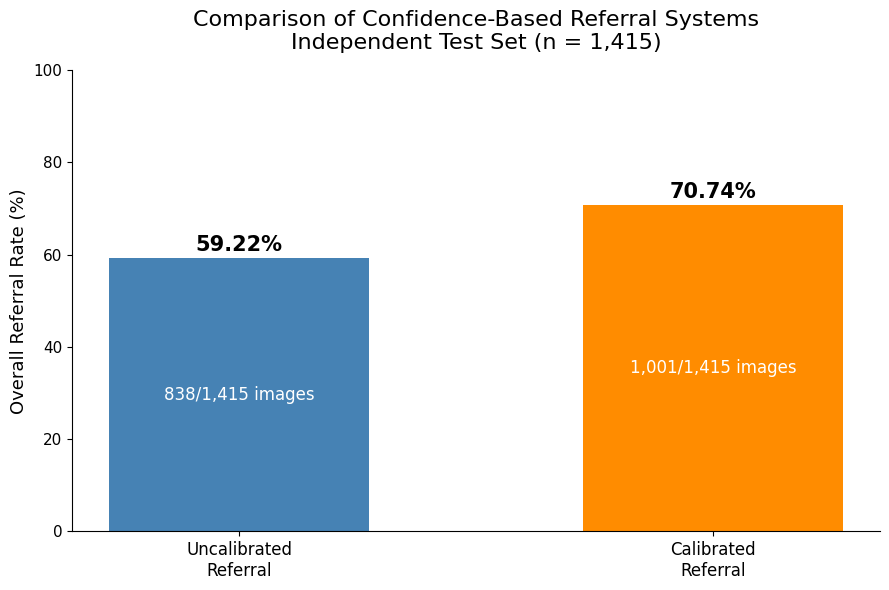

In [ ]:
# Calculates the bars directly from the test probabilities
import os
import numpy as np
import matplotlib.pyplot as plt

# Calculate referral rates directly from test predictions
system_names = ["Uncalibrated", "Calibrated"]
referral_counts = []
referral_rates = []

for name in system_names:
    probs = probabilities[name]

    predicted = np.argmax(probs, axis=1)
    confidence = np.max(probs, axis=1)

    accepted = (predicted == 0) & (confidence >= 0.80)
    referred = ~accepted

    referral_counts.append(int(referred.sum()))
    referral_rates.append(100 * referred.mean())

# Create figure
fig, ax = plt.subplots(figsize=(9, 6))

bars = ax.bar(
    ["Uncalibrated\nReferral", "Calibrated\nReferral"],
    referral_rates,
    color=["steelblue", "darkorange"],
    width=0.55
)

for bar, rate, count in zip(
    bars, referral_rates, referral_counts
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        rate + 1.5,
        f"{rate:.2f}%",
        ha="center",
        fontsize=15,
        fontweight="bold"
    )

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        rate / 2,
        f"{count:,}/{len(labels):,} images",
        ha="center",
        va="center",
        fontsize=12,
        color="white"
    )

ax.set_ylim(0, 100)
ax.set_ylabel("Overall Referral Rate (%)", fontsize=13)
ax.set_title(
    "Comparison of Confidence-Based Referral Systems\n"
    f"Independent Test Set (n = {len(labels):,})",
    fontsize=16,
    pad=15
)

ax.tick_params(axis="x", labelsize=12)
ax.tick_params(axis="y", labelsize=11)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

# Save updated figure
figures_folder = (
    "/content/drive/MyDrive/ENGG680/Final_Report_Figures"
)
os.makedirs(figures_folder, exist_ok=True)

for extension in ["png", "pdf"]:
    save_path = os.path.join(
        figures_folder,
        f"Figure_4_Referral_Comparison_Corrected.{extension}"
    )
    fig.savefig(save_path, dpi=300, bbox_inches="tight")
    print("Saved:", save_path)

plt.show()

In [ ]:
# Step 16.44: Evaluate calibration on the untouched test dataset

import numpy as np
import torch
from sklearn.metrics import brier_score_loss, log_loss

# Use the temperature previously fitted on validation data
optimal_temperature = 1.6472741540516778

# Probabilities BEFORE temperature scaling
test_uncalibrated_probs = torch.softmax(
    test_logits,
    dim=1
).numpy()

# Probabilities AFTER temperature scaling
test_calibrated_probs = torch.softmax(
    test_logits / optimal_temperature,
    dim=1
).numpy()

# Calculate calibration metrics
def test_calibration_metrics(probabilities, labels):

    brier = brier_score_loss(
        labels,
        probabilities[:, 1]
    )

    nll = log_loss(
        labels,
        probabilities,
        labels=[0, 1]
    )

    ece = calculate_ece(
        probabilities,
        labels,
        n_bins=10
    )

    return brier, ece, nll

# Calculate metrics before calibration
test_before_brier, test_before_ece, test_before_nll = (
    test_calibration_metrics(
        test_uncalibrated_probs,
        test_true_labels
    )
)

# Calculate metrics after calibration
test_after_brier, test_after_ece, test_after_nll = (
    test_calibration_metrics(
        test_calibrated_probs,
        test_true_labels
    )
)

print("--- FINAL TEST CALIBRATION RESULTS ---")

print("Test images:", len(test_true_labels))

print("\nMetric                 Before       After")
print("---------------------------------------------")

print(
    f"Brier Score            "
    f"{test_before_brier:.4f}       {test_after_brier:.4f}"
)

print(
    f"ECE                    "
    f"{test_before_ece:.4f}       {test_after_ece:.4f}"
)

print(
    f"NLL                    "
    f"{test_before_nll:.4f}       {test_after_nll:.4f}"
)

print("\nChanges (positive = improvement):")
print(f"Brier: {test_before_brier - test_after_brier:+.4f}")
print(f"ECE:   {test_before_ece - test_after_ece:+.4f}")
print(f"NLL:   {test_before_nll - test_after_nll:+.4f}")

print("\nFinal test calibration evaluation complete!")

In [14]:
# Step 16.45: Evaluate the fixed referral threshold on test data

import numpy as np

# Our previously selected referral threshold
referral_threshold = 0.80

# Predicted classes using calibrated probabilities
test_predicted_labels = np.argmax(
    test_calibrated_probs,
    axis=1
)

# Confidence in the predicted class
test_prediction_confidence = np.max(
    test_calibrated_probs,
    axis=1
)

# Automatically accept only confident benign predictions
test_accepted = (
    (test_predicted_labels == 0) &
    (test_prediction_confidence >= referral_threshold)
)

# Refer all other images
test_referred = ~test_accepted

# Count referral outcomes
total_accepted = int(np.sum(test_accepted))
total_referred = int(np.sum(test_referred))

malignant_referred = int(np.sum(
    test_referred & (test_true_labels == 1)
))

malignant_missed = int(np.sum(
    test_accepted & (test_true_labels == 1)
))

benign_referred = int(np.sum(
    test_referred & (test_true_labels == 0)
))

benign_accepted = int(np.sum(
    test_accepted & (test_true_labels == 0)
))

# Calculate rates
referral_rate = (
    total_referred / len(test_true_labels)
)

malignant_referral_sensitivity = (
    malignant_referred /
    np.sum(test_true_labels == 1)
)

print("--- FINAL TEST REFERRAL RESULTS ---")

print("Test images:", len(test_true_labels))
print("Referral threshold:", referral_threshold)

print("\nOverall referral outcomes:")
print("Automatically accepted:", total_accepted)
print("Referred for expert review:", total_referred)
print(f"Referral rate: {referral_rate * 100:.2f}%")

print("\nMalignant image outcomes:")
print("Malignant images referred:", malignant_referred)
print("Malignant images missed:", malignant_missed)
print(
    f"Malignant referral sensitivity: "
    f"{malignant_referral_sensitivity * 100:.2f}%"
)

print("\nBenign image outcomes:")
print("Benign images referred:", benign_referred)
print("Benign images accepted:", benign_accepted)

# Check consistency
assert total_accepted + total_referred == 1415
assert malignant_referred + malignant_missed == 236
assert benign_referred + benign_accepted == 1179

print("\nFinal test referral analysis complete!")

--- FINAL TEST REFERRAL RESULTS ---
Test images: 1415
Referral threshold: 0.8

Overall referral outcomes:
Automatically accepted: 414
Referred for expert review: 1001
Referral rate: 70.74%

Malignant image outcomes:
Malignant images referred: 236
Malignant images missed: 0
Malignant referral sensitivity: 100.00%

Benign image outcomes:
Benign images referred: 765
Benign images accepted: 414

Final test referral analysis complete!


**Independent test summary:** malignant classification recall = **91.10%** (215/236); ROC-AUC = **0.8981**; calibrated ECE = **0.0281**. At the validation-selected 80% referral threshold, **all 236 malignant images were referred**, including 21 that the classifier mislabeled benign; **70.74%** of all test images were referred. These are distinct classification and referral metrics.


## 10. Statistical uncertainty

Use 2,000 lesion-cluster bootstrap replicates for image-level classification metrics and referral rate. For the zero-miss referral result, also report a Wilson interval at the level of unique malignant lesions; it assumes independent lesions and is not a guarantee of future clinical sensitivity.


In [15]:
# Step 16.46: Prepare data for lesion-level bootstrap

import numpy as np
import pandas as pd

# Create a dataframe containing final test predictions
bootstrap_df = pd.DataFrame({
    "lesion_id": test_df["lesion_id"].to_numpy(),
    "true_label": test_true_labels,
    "predicted_label": test_predictions,
    "malignant_probability": test_malignant_probs,
    "referred": test_referred
})

# Check that all columns have the correct number of rows
assert len(bootstrap_df) == 1415

# Confirm labels match the original test dataset
expected_labels = test_df["classification"].map({
    "Benign": 0,
    "Malignant": 1
}).to_numpy()

assert np.array_equal(
    bootstrap_df["true_label"].to_numpy(),
    expected_labels
)

# Confirm referral outcomes match previous results
assert bootstrap_df["referred"].sum() == 1001

# Count unique lesions
n_lesions = bootstrap_df["lesion_id"].nunique()

print("--- Bootstrap Data Verification ---")

print("Total test images:", len(bootstrap_df))
print("Unique lesion IDs:", n_lesions)

print("\nClass distribution:")
print(bootstrap_df["true_label"].value_counts().sort_index())

print("\nReferral outcomes:")
print(bootstrap_df["referred"].value_counts())

print("\nBootstrap dataset successfully prepared!")

--- Bootstrap Data Verification ---
Total test images: 1415
Unique lesion IDs: 1087

Class distribution:
true_label
0    1179
1     236
Name: count, dtype: int64

Referral outcomes:
referred
True     1001
False     414
Name: count, dtype: int64

Bootstrap dataset successfully prepared!


In [16]:
# Step 16.47: Lesion-level bootstrap 95% confidence intervals

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    roc_auc_score
)

# Number of bootstrap repetitions
n_bootstrap = 2000

# Set random seed for reproducibility
rng = np.random.default_rng(42)

# Group image row positions by lesion ID
lesion_groups = bootstrap_df.groupby(
    "lesion_id",
    sort=False
).indices

unique_lesions = np.array(list(lesion_groups.keys()))
n_lesions = len(unique_lesions)

# Store bootstrap metric results
bootstrap_results = {
    "Accuracy": [],
    "Balanced Accuracy": [],
    "Malignant Recall": [],
    "Malignant Precision": [],
    "F1 Score": [],
    "ROC-AUC": [],
    "Referral Rate": []
}

# Extract arrays once for efficiency
y_true = bootstrap_df["true_label"].to_numpy()
y_pred = bootstrap_df["predicted_label"].to_numpy()
y_prob = bootstrap_df["malignant_probability"].to_numpy()
referred = bootstrap_df["referred"].to_numpy()

print("Starting lesion-level bootstrap...")
print("Bootstrap repetitions:", n_bootstrap)
print("Unique lesions:", n_lesions)

for i in range(n_bootstrap):

    # Sample lesion IDs with replacement
    sampled_lesions = rng.choice(
        unique_lesions,
        size=n_lesions,
        replace=True
    )

    # Include every image associated with each sampled lesion
    sampled_indices = np.concatenate([
        lesion_groups[lesion_id]
        for lesion_id in sampled_lesions
    ])

    # Extract bootstrap sample
    yt = y_true[sampled_indices]
    yp = y_pred[sampled_indices]
    prob = y_prob[sampled_indices]
    ref = referred[sampled_indices]

    # Skip samples missing either class
    if len(np.unique(yt)) < 2:
        continue

    # Calculate performance metrics
    bootstrap_results["Accuracy"].append(
        accuracy_score(yt, yp)
    )

    bootstrap_results["Balanced Accuracy"].append(
        balanced_accuracy_score(yt, yp)
    )

    bootstrap_results["Malignant Recall"].append(
        recall_score(yt, yp, pos_label=1)
    )

    bootstrap_results["Malignant Precision"].append(
        precision_score(
            yt, yp, pos_label=1, zero_division=0
        )
    )

    bootstrap_results["F1 Score"].append(
        f1_score(yt, yp, pos_label=1)
    )

    bootstrap_results["ROC-AUC"].append(
        roc_auc_score(yt, prob)
    )

    bootstrap_results["Referral Rate"].append(
        np.mean(ref)
    )

# Calculate percentile confidence intervals
ci_rows = []

for metric, values in bootstrap_results.items():

    lower, upper = np.percentile(
        values,
        [2.5, 97.5]
    )

    ci_rows.append({
        "Metric": metric,
        "95% CI Lower": round(float(lower), 4),
        "95% CI Upper": round(float(upper), 4)
    })

bootstrap_ci_df = pd.DataFrame(ci_rows)

print("\n--- FINAL 95% BOOTSTRAP CONFIDENCE INTERVALS ---")
print(bootstrap_ci_df.to_string(index=False))

print("\nValid bootstrap samples:",
      len(bootstrap_results["Accuracy"]))

print("\nLesion-level bootstrap complete!")

Starting lesion-level bootstrap...
Bootstrap repetitions: 2000
Unique lesions: 1087

--- FINAL 95% BOOTSTRAP CONFIDENCE INTERVALS ---
             Metric  95% CI Lower  95% CI Upper
           Accuracy        0.7123        0.7677
  Balanced Accuracy        0.7817        0.8337
   Malignant Recall        0.8667        0.9504
Malignant Precision        0.3280        0.4372
           F1 Score        0.4816        0.5924
            ROC-AUC        0.8762        0.9188
      Referral Rate        0.6803        0.7325

Valid bootstrap samples: 2000

Lesion-level bootstrap complete!


In [17]:
# Step 16.48: Confidence interval for malignant referral sensitivity

import numpy as np
from statsmodels.stats.proportion import proportion_confint

# Number of malignant images referred
n_malignant_referred = int(
    np.sum(
        (test_true_labels == 1) &
        test_referred
    )
)

# Total malignant images
n_malignant = int(
    np.sum(test_true_labels == 1)
)

# Wilson 95% confidence interval
ci_lower, ci_upper = proportion_confint(
    count=n_malignant_referred,
    nobs=n_malignant,
    alpha=0.05,
    method="wilson"
)

# Count unique malignant lesions
malignant_test_df = bootstrap_df[
    bootstrap_df["true_label"] == 1
]

unique_malignant_lesions = (
    malignant_test_df["lesion_id"].nunique()
)

print("--- MALIGNANT REFERRAL SENSITIVITY ---")

print("Malignant images:", n_malignant)
print("Malignant images referred:", n_malignant_referred)
print("Malignant images missed:",
      n_malignant - n_malignant_referred)

print(
    f"\nObserved referral sensitivity: "
    f"{n_malignant_referred / n_malignant * 100:.2f}%"
)

print(
    f"Wilson 95% CI (image-level): "
    f"{ci_lower * 100:.2f}% – {ci_upper * 100:.2f}%"
)

print(
    "\nUnique malignant lesions:",
    unique_malignant_lesions
)

print("\nReferral sensitivity interval calculated!")

--- MALIGNANT REFERRAL SENSITIVITY ---
Malignant images: 236
Malignant images referred: 236
Malignant images missed: 0

Observed referral sensitivity: 100.00%
Wilson 95% CI (image-level): 98.40% – 100.00%

Unique malignant lesions: 141

Referral sensitivity interval calculated!


In [18]:
# Step 16.49: Lesion-level confidence interval
# for malignant referral sensitivity

from statsmodels.stats.proportion import proportion_confint

# Select malignant images
malignant_lesion_data = bootstrap_df[
    bootstrap_df["true_label"] == 1
].copy()

# A lesion is counted as successfully referred only if
# ALL its malignant images were referred
lesion_referral_results = (
    malignant_lesion_data
    .groupby("lesion_id")["referred"]
    .all()
)

# Count successful referrals at the lesion level
n_malignant_lesions = len(lesion_referral_results)

n_lesions_fully_referred = int(
    lesion_referral_results.sum()
)

n_lesions_with_missed_images = (
    n_malignant_lesions - n_lesions_fully_referred
)

# Wilson 95% confidence interval
lesion_ci_lower, lesion_ci_upper = proportion_confint(
    count=n_lesions_fully_referred,
    nobs=n_malignant_lesions,
    alpha=0.05,
    method="wilson"
)

print("--- LESION-LEVEL REFERRAL RESULTS ---")

print("Unique malignant lesions:", n_malignant_lesions)

print(
    "Malignant lesions with all images referred:",
    n_lesions_fully_referred
)

print(
    "Malignant lesions with at least one missed image:",
    n_lesions_with_missed_images
)

print(
    f"\nObserved lesion-level referral sensitivity: "
    f"{n_lesions_fully_referred / n_malignant_lesions * 100:.2f}%"
)

print(
    f"Lesion-level Wilson 95% CI: "
    f"{lesion_ci_lower * 100:.2f}% – "
    f"{lesion_ci_upper * 100:.2f}%"
)

print("\nLesion-level confidence interval complete!")

--- LESION-LEVEL REFERRAL RESULTS ---
Unique malignant lesions: 141
Malignant lesions with all images referred: 141
Malignant lesions with at least one missed image: 0

Observed lesion-level referral sensitivity: 100.00%
Lesion-level Wilson 95% CI: 97.35% – 100.00%

Lesion-level confidence interval complete!


## 11. Export results and create report figures

Saved files include individual predictions, confidence intervals, the final summary, a confusion matrix, ROC curve, reliability plot, referral chart, and performance table.


In [ ]:
# Step 16.50: Save final test results to Google Drive

import os
import json
import numpy as np
import pandas as pd

# Create results folder
results_folder = "/content/drive/MyDrive/ENGG680/Final_Test_Results"

os.makedirs(results_folder, exist_ok=True)

# Save individual test predictions and referral decisions
final_predictions_df = bootstrap_df.copy()

final_predictions_df["image_id"] = (
    test_df["image_id"].to_numpy()
)

final_predictions_df["prediction_confidence"] = (
    test_prediction_confidence
)

final_predictions_df.to_csv(
    os.path.join(
        results_folder,
        "augmented_resnet18_test_predictions.csv"
    ),
    index=False
)

# Save bootstrap confidence intervals
bootstrap_ci_df.to_csv(
    os.path.join(
        results_folder,
        "augmented_resnet18_bootstrap_95CI.csv"
    ),
    index=False
)

# Save summary metrics
final_summary = {
    "model": "Augmented ResNet-18",
    "test_images": 1415,
    "test_unique_lesions": 1087,
    "temperature": float(optimal_temperature),
    "referral_threshold": 0.80,

    "classification": {
        "accuracy": 0.7399,
        "balanced_accuracy": 0.8083,
        "malignant_recall": 0.9110,
        "malignant_precision": 0.3826,
        "f1_score": 0.5388,
        "roc_auc": 0.8981
    },

    "calibration": {
        "brier_score": float(test_after_brier),
        "ece": float(test_after_ece),
        "nll": float(test_after_nll)
    },

    "referral": {
        "images_accepted": int(total_accepted),
        "images_referred": int(total_referred),
        "referral_rate": float(referral_rate),
        "malignant_images_referred": int(malignant_referred),
        "malignant_images_missed": int(malignant_missed),
        "malignant_referral_sensitivity": float(
            malignant_referral_sensitivity
        ),
        "unique_malignant_lesions": int(
            n_malignant_lesions
        ),
        "lesion_level_wilson_95ci": [
            float(lesion_ci_lower),
            float(lesion_ci_upper)
        ]
    }
}

summary_path = os.path.join(
    results_folder,
    "augmented_resnet18_final_summary.json"
)

with open(summary_path, "w") as f:
    json.dump(final_summary, f, indent=4)

print("--- FINAL RESULTS SAVED ---")

print("\nFolder:", results_folder)

print("\nSaved files:")
for filename in sorted(os.listdir(results_folder)):
    print("-", filename)

print("\nFinal results successfully saved!")

In [ ]:
# Step 16.51: Create and save final test confusion matrix

import os
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculate confusion matrix from test predictions
cm = confusion_matrix(
    test_true_labels,
    test_predictions,
    labels=[0, 1]
)

# Create figure
fig, ax = plt.subplots(figsize=(7, 6))

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
)

cm_display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title(
    "Augmented ResNet-18: Test Confusion Matrix",
    fontsize=14,
    pad=15
)

ax.set_xlabel("Predicted Classification", fontsize=12)
ax.set_ylabel("True Classification", fontsize=12)

plt.tight_layout()

# Save high-resolution image
figure_path = os.path.join(
    results_folder,
    "augmented_resnet18_confusion_matrix.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nConfusion matrix:")
print(cm)

print("\nFigure saved to:")
print(figure_path)

In [ ]:
# Step 16.52: Create and save final test ROC curve

import os
import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve, roc_auc_score

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(
    test_true_labels,
    test_malignant_probs
)

# Calculate ROC-AUC
roc_auc = roc_auc_score(
    test_true_labels,
    test_malignant_probs
)

# Create figure
fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    fpr,
    tpr,
    linewidth=2.5,
    label=f"Augmented ResNet-18 (AUC = {roc_auc:.4f})"
)

# Random classification reference line
ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random classifier (AUC = 0.50)"
)

ax.set_xlabel("False Positive Rate", fontsize=12)
ax.set_ylabel("True Positive Rate (Malignant Recall)", fontsize=12)

ax.set_title(
    "Augmented ResNet-18: Test ROC Curve",
    fontsize=14,
    pad=15
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.legend(loc="lower right")
ax.grid(alpha=0.3)

plt.tight_layout()

# Save high-resolution figure
figure_path = os.path.join(
    results_folder,
    "augmented_resnet18_roc_curve.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"\nFinal test ROC-AUC: {roc_auc:.4f}")
print("\nFigure saved to:")
print(figure_path)

In [ ]:
# Step 16.53: Create and save test calibration plot

import os
import numpy as np
import matplotlib.pyplot as plt

# Calculate confidence and correctness for each prediction
def get_reliability_data(probabilities, true_labels, n_bins=10):

    confidence = np.max(probabilities, axis=1)
    predictions = np.argmax(probabilities, axis=1)
    correct = (predictions == true_labels).astype(float)

    bin_edges = np.linspace(0, 1, n_bins + 1)

    mean_confidence = []
    observed_accuracy = []
    bin_counts = []

    for i in range(n_bins):

        if i == n_bins - 1:
            mask = (
                (confidence >= bin_edges[i]) &
                (confidence <= bin_edges[i + 1])
            )
        else:
            mask = (
                (confidence >= bin_edges[i]) &
                (confidence < bin_edges[i + 1])
            )

        if np.sum(mask) > 0:
            mean_confidence.append(np.mean(confidence[mask]))
            observed_accuracy.append(np.mean(correct[mask]))
            bin_counts.append(np.sum(mask))

    return (
        np.array(mean_confidence),
        np.array(observed_accuracy),
        np.array(bin_counts)
    )


# Before temperature scaling
before_conf, before_acc, before_counts = get_reliability_data(
    test_uncalibrated_probs,
    test_true_labels
)

# After temperature scaling
after_conf, after_acc, after_counts = get_reliability_data(
    test_calibrated_probs,
    test_true_labels
)

# Create calibration figure
fig, ax = plt.subplots(figsize=(7, 6))

# Perfect calibration reference
ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect calibration"
)

# Uncalibrated reliability
ax.plot(
    before_conf,
    before_acc,
    marker="o",
    linewidth=2,
    label=f"Before calibration (ECE = {test_before_ece:.4f})"
)

# Calibrated reliability
ax.plot(
    after_conf,
    after_acc,
    marker="s",
    linewidth=2,
    label=f"After calibration (ECE = {test_after_ece:.4f})"
)

ax.set_title(
    "Augmented ResNet-18: Test Calibration",
    fontsize=14,
    pad=15
)

ax.set_xlabel("Mean Predicted Confidence", fontsize=12)
ax.set_ylabel("Observed Classification Accuracy", fontsize=12)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

ax.grid(alpha=0.3)
ax.legend(loc="upper left")

plt.tight_layout()

# Save figure
calibration_figure_path = os.path.join(
    results_folder,
    "augmented_resnet18_calibration_plot.png"
)

plt.savefig(
    calibration_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("--- FINAL TEST CALIBRATION ---")
print(f"ECE before: {test_before_ece:.4f}")
print(f"ECE after:  {test_after_ece:.4f}")

print("\nFigure saved to:")
print(calibration_figure_path)

In [ ]:
# Step 16.54: Create final referral strategy visualization

import os
import numpy as np
import matplotlib.pyplot as plt

# Outcomes from independent test evaluation
categories = ["Benign", "Malignant"]

accepted_counts = [414, 0]
referred_counts = [765, 236]

x = np.arange(len(categories))

fig, ax = plt.subplots(figsize=(8, 6))

# Automatically accepted images
ax.bar(
    x,
    accepted_counts,
    label="Automatically Accepted as Benign",
    color="#4C9F70"
)

# Images referred for expert review
ax.bar(
    x,
    referred_counts,
    bottom=accepted_counts,
    label="Referred for Expert Review",
    color="#E69F00"
)

# Label each bar segment
for i in range(len(categories)):

    if accepted_counts[i] > 0:
        ax.text(
            x[i],
            accepted_counts[i] / 2,
            str(accepted_counts[i]),
            ha="center",
            va="center",
            fontsize=13
        )

    if referred_counts[i] > 0:
        ax.text(
            x[i],
            accepted_counts[i] + referred_counts[i] / 2,
            str(referred_counts[i]),
            ha="center",
            va="center",
            fontsize=13
        )

ax.set_xticks(x)
ax.set_xticklabels(categories)

ax.set_ylabel("Number of Test Images", fontsize=12)

ax.set_title(
    "Augmented ResNet-18: Confidence-Based Referral Outcomes",
    fontsize=13,
    pad=15
)

ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

# Save figure
referral_figure_path = os.path.join(
    results_folder,
    "augmented_resnet18_referral_outcomes.png"
)

plt.savefig(
    referral_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("--- FINAL REFERRAL RESULTS ---")
print("Malignant images referred:", 236)
print("Malignant images automatically accepted:", 0)
print("Overall referral rate: 70.74%")

print("\nFigure saved to:")
print(referral_figure_path)

In [ ]:
# Step 16.55: Create final performance summary table

import os
import pandas as pd

# Load our saved bootstrap confidence intervals
ci_path = os.path.join(
    results_folder,
    "augmented_resnet18_bootstrap_95CI.csv"
)

ci_df = pd.read_csv(ci_path)

# Helper function to retrieve bootstrap confidence intervals
def get_ci(metric, percentage=False):
    row = ci_df.loc[ci_df["Metric"] == metric].iloc[0]

    lower = row["95% CI Lower"]
    upper = row["95% CI Upper"]

    if percentage:
        return f"{lower*100:.2f}%–{upper*100:.2f}%"

    return f"{lower:.4f}–{upper:.4f}"


# Create the final table
final_table = pd.DataFrame([
    ["Classification", "Accuracy",
     "73.99%", get_ci("Accuracy", True)],

    ["Classification", "Balanced Accuracy",
     "80.83%", get_ci("Balanced Accuracy", True)],

    ["Classification", "Malignant Recall",
     "91.10%", get_ci("Malignant Recall", True)],

    ["Classification", "Malignant Precision",
     "38.26%", get_ci("Malignant Precision", True)],

    ["Classification", "F1 Score",
     "0.5388", get_ci("F1 Score")],

    ["Classification", "ROC-AUC",
     "0.8981", get_ci("ROC-AUC")],

    ["Calibration", "ECE (After Calibration)",
     f"{test_after_ece:.4f}", "Not calculated"],

    ["Calibration", "Brier Score (After Calibration)",
     f"{test_after_brier:.4f}", "Not calculated"],

    ["Calibration", "NLL (After Calibration)",
     f"{test_after_nll:.4f}", "Not calculated"],

    ["Referral", "Referral Rate",
     f"{referral_rate*100:.2f}%",
     get_ci("Referral Rate", True)],

    ["Referral", "Malignant Referral Sensitivity",
     f"{malignant_referral_sensitivity*100:.2f}%",
     f"{lesion_ci_lower*100:.2f}%–{lesion_ci_upper*100:.2f}%"]
], columns=[
    "Category",
    "Metric",
    "Final Test Result",
    "95% Confidence Interval"
])

# Display table
print("--- FINAL ENGG 680 PERFORMANCE SUMMARY ---")
from IPython.display import display as notebook_display
notebook_display(final_table)

# Save as CSV
table_path = os.path.join(
    results_folder,
    "augmented_resnet18_final_performance_table.csv"
)

final_table.to_csv(table_path, index=False)

print("\nTable saved to:")
print(table_path)

print("\nFinal performance table complete!")

## Classification threshold experiments


# Threshold Optimization

In [ ]:

import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")


PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
# Step 1 - Get our validation predictions ready
  # Re-Run:
    # 16.33 D: Restore validation DataLoader
    # 16.33 E: Restore best augmented ResNet-18 on GPU
    # 16.33F: Collect validation logits using GPU

In [ ]:
# Step 2: Check that everything is ready

import torch
import numpy as np

print("GPU available:", torch.cuda.is_available())

print("\nValidation dataset:")
print("Number of images:", len(val_df))

print("\nValidation class distribution:")
print(val_df["classification"].value_counts())

print("\nModel:")
print("Model loaded:", "model" in globals())

print("\nValidation DataLoader:")
print("DataLoader loaded:", "val_loader" in globals())

GPU available: True

Validation dataset:
Number of images: 1460

Validation class distribution:
classification
Benign       1209
Malignant     251
Name: count, dtype: int64

Model:
Model loaded: True

Validation DataLoader:
DataLoader loaded: True


In [ ]:
# Step 3A: Check our loaded model

import torch

print("Model architecture:")
print(type(model).__name__)

print("\nFinal classification layer:")
print(model.fc)

print("\nModel device:")
print(next(model.parameters()).device)

print("\nCheckpoint files:")
import glob
for path in glob.glob(
    "/content/drive/MyDrive/ENGG680/*augmented*.pt"
):
    print(path)

Model architecture:
ResNet

Final classification layer:
Linear(in_features=512, out_features=2, bias=True)

Model device:
cuda:0

Checkpoint files:
/content/drive/MyDrive/ENGG680/resnet18_best_augmented.pt
/content/drive/MyDrive/ENGG680/resnet18_augmented_recovery.pt


In [ ]:
# Step 3B: Verify the best augmented model checkpoint

import torch

checkpoint_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_best_augmented.pt"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

print("Checkpoint type:", type(checkpoint).__name__)

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", list(checkpoint.keys())[:15])

Checkpoint type: OrderedDict
Checkpoint keys: ['conv1.weight', 'bn1.weight', 'bn1.bias', 'bn1.running_mean', 'bn1.running_var', 'bn1.num_batches_tracked', 'layer1.0.conv1.weight', 'layer1.0.bn1.weight', 'layer1.0.bn1.bias', 'layer1.0.bn1.running_mean', 'layer1.0.bn1.running_var', 'layer1.0.bn1.num_batches_tracked', 'layer1.0.conv2.weight', 'layer1.0.bn2.weight', 'layer1.0.bn2.bias']


In [ ]:
# Step 3C: Load our best augmented ResNet-18 weights

# Load the saved weights into our existing model
model.load_state_dict(checkpoint, strict=True)

# Move the model to the GPU
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
model = model.to(device)

# Set the model to evaluation mode
model.eval()

print("Best augmented ResNet-18 loaded successfully!")
print("Device:", next(model.parameters()).device)
print("Final layer:", model.fc)
print("Evaluation mode:", not model.training)

Best augmented ResNet-18 loaded successfully!
Device: cuda:0
Final layer: Linear(in_features=512, out_features=2, bias=True)
Evaluation mode: True


In [ ]:
# Step 4: Generate validation probabilities

import numpy as np
import torch
from tqdm.auto import tqdm

model.eval()

all_probabilities = []
all_labels = []

with torch.no_grad():
    for images, labels in tqdm(
        val_loader,
        desc="Generating validation predictions"
    ):
        # Move images to the GPU
        images = images.to(device)

        # Get model predictions
        outputs = model(images)

        # Convert logits into probabilities
        probabilities = torch.softmax(outputs, dim=1)

        # Extract malignant probabilities (class 1)
        malignant_probabilities = probabilities[:, 1]

        all_probabilities.extend(
            malignant_probabilities.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
            if torch.is_tensor(labels)
            else np.asarray(labels)
        )

# Convert to NumPy arrays
y_prob = np.asarray(all_probabilities)
y_true = np.asarray(all_labels)

# Verify the results
assert len(y_prob) == len(y_true)
assert len(y_prob) == 1460
assert set(np.unique(y_true)).issubset({0, 1})

print("\nValidation predictions generated!")
print("Total images:", len(y_prob))
print("Benign images:", np.sum(y_true == 0))
print("Malignant images:", np.sum(y_true == 1))

print("\nMalignant probability range:")
print("Minimum:", round(y_prob.min(), 4))
print("Maximum:", round(y_prob.max(), 4))

Generating validation predictions:   0%|          | 0/46 [00:00<?, ?it/s]


Validation predictions generated!
Total images: 1460
Benign images: 1209
Malignant images: 251

Malignant probability range:
Minimum: 0.0003
Maximum: 0.9984


In [ ]:
# Step 5: Compare classification thresholds

import pandas as pd
import numpy as np

from sklearn.metrics import (
    confusion_matrix,
    balanced_accuracy_score,
    recall_score,
    precision_score,
    accuracy_score
)

thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]

results = []

for threshold in thresholds:

    # Predict malignant (1) if probability >= threshold
    y_pred = (y_prob >= threshold).astype(int)

    # Confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    # Calculate evaluation metrics
    sensitivity = recall_score(
        y_true, y_pred, pos_label=1
    )

    specificity = tn / (tn + fp)

    balanced_accuracy = balanced_accuracy_score(
        y_true, y_pred
    )

    precision = precision_score(
        y_true, y_pred, pos_label=1,
        zero_division=0
    )

    accuracy = accuracy_score(y_true, y_pred)

    results.append({
        "Threshold": threshold,
        "Accuracy (%)": round(accuracy * 100, 2),
        "Balanced Accuracy (%)": round(
            balanced_accuracy * 100, 2
        ),
        "Sensitivity (%)": round(sensitivity * 100, 2),
        "Specificity (%)": round(specificity * 100, 2),
        "Precision (%)": round(precision * 100, 2),
        "False Positives": int(fp),
        "False Negatives": int(fn)
    })

threshold_results = pd.DataFrame(results)

display(threshold_results)

,Threshold,Accuracy (%),Balanced Accuracy (%),Sensitivity (%),Specificity (%),Precision (%),False Positives,False Negatives
0,0.3,60.68,74.05,94.42,53.68,29.74,560,14
1,0.4,67.05,77.27,92.83,61.70,33.48,463,18
2,0.5,72.47,77.85,86.06,69.64,37.05,367,35
3,0.6,76.44,76.78,77.29,76.26,40.33,287,57
4,0.7,80.27,76.25,70.12,82.38,45.24,213,75


This has discovered that - increasing the threshold improves overall accuracy and specificity, but decreases our ability to detect malignant lesions.

In [ ]:
# Investigat smaller threshold increments

# Step 6: Fine-tune classification threshold comparison

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

thresholds_fine = np.round(
    np.arange(0.40, 0.501, 0.01), 2
)

fine_results = []

for threshold in thresholds_fine:

    y_pred = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)
    balanced_accuracy = (sensitivity + specificity) / 2

    fine_results.append({
        "Threshold": threshold,
        "Balanced Accuracy (%)": round(
            balanced_accuracy * 100, 2
        ),
        "Sensitivity (%)": round(sensitivity * 100, 2),
        "Specificity (%)": round(specificity * 100, 2),
        "False Positives": int(fp),
        "False Negatives": int(fn)
    })

fine_threshold_results = pd.DataFrame(fine_results)

display(fine_threshold_results)

,Threshold,Balanced Accuracy (%),Sensitivity (%),Specificity (%),False Positives,False Negatives
0,0.40,77.27,92.83,61.70,463,18
1,0.41,77.49,92.03,62.94,448,20
2,0.42,77.70,91.63,63.77,438,21
3,0.43,77.71,91.24,64.19,433,22
4,0.44,77.24,89.64,64.85,425,26
5,0.45,77.30,88.84,65.76,414,28
6,0.46,77.52,88.45,66.58,404,29
7,0.47,78.01,88.45,67.58,392,29
8,0.48,78.31,88.05,68.57,380,30
9,0.49,78.28,87.25,69.31,371,32


In [ ]:
# Step 7: Bootstrap comparison of classification thresholds

import numpy as np
from sklearn.metrics import balanced_accuracy_score

rng = np.random.default_rng(42)
n_bootstrap = 2000

benign_idx = np.where(y_true == 0)[0]
malignant_idx = np.where(y_true == 1)[0]

differences = []

for _ in range(n_bootstrap):

    # Resample each class separately
    sample_idx = np.concatenate([
        rng.choice(benign_idx, size=len(benign_idx), replace=True),
        rng.choice(malignant_idx, size=len(malignant_idx), replace=True)
    ])

    labels = y_true[sample_idx]
    probabilities = y_prob[sample_idx]

    predictions_048 = (probabilities >= 0.48).astype(int)
    predictions_050 = (probabilities >= 0.50).astype(int)

    score_048 = balanced_accuracy_score(
        labels, predictions_048
    )

    score_050 = balanced_accuracy_score(
        labels, predictions_050
    )

    differences.append(score_048 - score_050)

differences = np.array(differences)

ci_lower, ci_upper = np.percentile(
    differences, [2.5, 97.5]
)

print("Comparison: threshold 0.48 vs 0.50")
print(
    "Mean balanced accuracy difference:",
    round(differences.mean() * 100, 3),
    "percentage points"
)
print(
    "95% bootstrap CI:",
    f"[{ci_lower * 100:.3f}, {ci_upper * 100:.3f}]",
    "percentage points")

Comparison: threshold 0.48 vs 0.50
Mean balanced accuracy difference: 0.482 percentage points
95% bootstrap CI: [-0.338, 1.454] percentage points


In [ ]:
# Step 8: Save threshold optimization results

import os
import pandas as pd

output_folder = "/content/drive/MyDrive/ENGG680/Threshold_Optimization"
os.makedirs(output_folder, exist_ok=True)

# Save the broad and fine threshold comparisons
threshold_results.to_csv(
    os.path.join(output_folder, "threshold_comparison.csv"),
    index=False
)

fine_threshold_results.to_csv(
    os.path.join(output_folder, "fine_threshold_comparison.csv"),
    index=False
)

# Save the bootstrap comparison
bootstrap_summary = pd.DataFrame([{
    "Baseline Threshold": 0.50,
    "Candidate Threshold": 0.48,
    "Mean Difference (pp)": differences.mean() * 100,
    "95% CI Lower (pp)": ci_lower * 100,
    "95% CI Upper (pp)": ci_upper * 100
}])

bootstrap_summary.to_csv(
    os.path.join(output_folder, "bootstrap_comparison.csv"),
    index=False
)

print("Threshold optimization results saved successfully!")

Threshold optimization results saved successfully!


# What we have accomplished:
- Tested classification thresholds from 0.30 to 0.70.
- Investigated smaller increments between 0.40 and 0.50.
- Identified 0.48 as the threshold with the highest balanced accuracy among those tested (78.31%).
- Calculated a 95% bootstrap confidence interval, which showed that the improvement over 0.50 was uncertain.
- Preserved 0.50 as our baseline threshold.

## Additional fine-tuning experiment


# Experiment: Additional Fine-Tuning with Early Stopping

In [ ]:
# Step 9: Review original augmented training history

import os
import torch
import pandas as pd

recovery_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_augmented_recovery.pt"
)

assert os.path.isfile(recovery_path), (
    "Original recovery checkpoint not found!"
)

# Read the checkpoint without modifying it
recovery = torch.load(
    recovery_path,
    map_location="cpu",
    weights_only=True
)

print("Recovery checkpoint loaded successfully!")

print("\nLast completed epoch:")
print(recovery.get("epoch", "Not recorded"))

print("\nBest validation balanced accuracy:")
print(recovery.get("best_val_score", "Not recorded"))

print("\nTraining history:")

history = recovery.get("history", [])

if len(history) > 0:
    history_df = pd.DataFrame(history)
    display(history_df)
else:
    print("No training history found.")

Recovery checkpoint loaded successfully!

Last completed epoch:
3

Best validation balanced accuracy:
0.7785005552644674

Training history:


,epoch,train_loss,val_loss,val_balanced_accuracy,val_malignant_recall,val_roc_auc
0,1,0.414597,0.417807,0.773068,0.733068,NaN
1,2,0.385011,0.433304,0.774192,0.760956,NaN
2,3,0.377171,0.549109,0.778501,0.860558,0.863435


# What does this mean?
1. The model continued learning the training data. Training loss decreased from 0.4146 to 0.3772.

2. Validation loss was getting worse. It increased from 0.4178 to 0.5491. This is a warning sign of possible overfitting or increasingly overconfident incorrect predictions.

3. Malignant sensitivity improved substantially. It increased from 73.31% to 86.06%, which is particularly relevant to our project's goal of identifying malignant lesions.

4. Epoch 3 achieved the highest recorded balanced accuracy. This explains why our original training procedure selected it, even though its validation loss was higher.

In [ ]:
# Step 10: Check training recovery information

import torch

print("Last completed epoch:", recovery["epoch"])

print("\nRecovery checkpoint contents:")
for key in recovery.keys():
    print("-", key)

print("\nOptimizer state available:",
      "optimizer_state_dict" in recovery)

print("\nTraining DataLoaders:")
print("Augmented training loader available:",
      "train_loader_augmented" in globals())

print("Validation loader available:",
      "val_loader" in globals())

print("\nGPU available:", torch.cuda.is_available())

Last completed epoch: 3

Recovery checkpoint contents:
- epoch
- model_state_dict
- optimizer_state_dict
- best_val_score
- history

Optimizer state available: True

Training DataLoaders:
Augmented training loader available: False
Validation loader available: True

GPU available: True


In [ ]:
# Step 11: Restore augmented training DataLoader

import os
import torch
from torchvision import transforms
from torch.utils.data import DataLoader

# Recreate the original augmentation pipeline
train_transform_augmented = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=20),
    transforms.ColorJitter(
        brightness=0.10,
        contrast=0.10,
        saturation=0.05,
        hue=0.02
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Check original training images are accessible
missing_images = [
    path for path in train_df["image_path"]
    if not os.path.isfile(path)
]

assert len(missing_images) == 0, (
    f"{len(missing_images)} training images are missing!"
)

# Restore training dataset
train_dataset_augmented = HAM10000Dataset(
    train_df,
    transform=train_transform_augmented
)

# Restore training DataLoader
train_loader_augmented = DataLoader(
    train_dataset_augmented,
    batch_size=32,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

print("Augmented training DataLoader restored!")
print("Training images:", len(train_dataset_augmented))
print("Training batches:", len(train_loader_augmented))
print("Validation images:", len(val_df))

# Confirm a batch loads correctly
images, labels = next(iter(train_loader_augmented))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

Augmented training DataLoader restored!
Training images: 6813
Training batches: 213
Validation images: 1460
Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])


In [ ]:
# Step 12: Restore model and optimizer for Experiment 2

import os
import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Recreate the ResNet-18 architecture
experiment2_model = models.resnet18(weights=None)
experiment2_model.fc = nn.Linear(
    experiment2_model.fc.in_features, 2
)

# Freeze all layers
for parameter in experiment2_model.parameters():
    parameter.requires_grad = False

# Unfreeze layer4 and the classification layer
for parameter in experiment2_model.layer4.parameters():
    parameter.requires_grad = True

for parameter in experiment2_model.fc.parameters():
    parameter.requires_grad = True

# Restore the model from the epoch-3 recovery checkpoint
experiment2_model.load_state_dict(
    recovery["model_state_dict"],
    strict=True
)

experiment2_model = experiment2_model.to(device)

# Recreate Adam with the original parameter groups
experiment2_optimizer = torch.optim.Adam([
    {
        "params": experiment2_model.layer4.parameters(),
        "lr": 1e-5
    },
    {
        "params": experiment2_model.fc.parameters(),
        "lr": 1e-4
    }
])

# Restore Adam's previous training state
experiment2_optimizer.load_state_dict(
    recovery["optimizer_state_dict"]
)

# Confirm optimizer tensors are on the correct device
for state in experiment2_optimizer.state.values():
    for key, value in state.items():
        if torch.is_tensor(value):
            state[key] = value.to(device)

# Prepare a separate folder for the new experiment
experiment2_folder = (
    "/content/drive/MyDrive/ENGG680/"
    "Additional_Finetuning"
)

os.makedirs(experiment2_folder, exist_ok=True)

# Do not begin training yet
experiment2_model.eval()

print("Experiment 2 model restored successfully!")
print("Starting from completed epoch:", recovery["epoch"])
print("Device:", next(experiment2_model.parameters()).device)

print("\nOptimizer learning rates:")
print("Layer4:", experiment2_optimizer.param_groups[0]["lr"])
print("FC:", experiment2_optimizer.param_groups[1]["lr"])

print("\nOptimizer state entries:",
      len(experiment2_optimizer.state))

print("\nNew experiment folder:")
print(experiment2_folder)

Experiment 2 model restored successfully!
Starting from completed epoch: 3
Device: cuda:0

Optimizer learning rates:
Layer4: 1e-05
FC: 0.0001

Optimizer state entries: 17

New experiment folder:
/content/drive/MyDrive/ENGG680/Additional_Finetuning


In [ ]:
# Step 13A: Inspect training DataFrame columns

print("Training DataFrame columns:")
print(train_df.columns.tolist())

print("\nFirst five rows:")
display(train_df.head())

Training DataFrame columns:
['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization', 'dataset', 'classification', 'image_path']

First five rows:


,lesion_id,image_id,dx,dx_type,age,sex,localization,dataset,classification,image_path
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,vidir_modern,Benign,/content/drive/MyDrive/ENGG680/HAM10000_images...
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,vidir_modern,Benign,/content/drive/MyDrive/ENGG680/HAM10000_images...
11,HAM_0004234,ISIC_0029396,bkl,histo,85.0,female,chest,vidir_modern,Benign,/content/drive/MyDrive/ENGG680/HAM10000_images...
12,HAM_0004234,ISIC_0025984,bkl,histo,85.0,female,chest,vidir_modern,Benign,/content/drive/MyDrive/ENGG680/HAM10000_images...
13,HAM_0001949,ISIC_0025767,bkl,histo,70.0,male,trunk,vidir_modern,Benign,/content/drive/MyDrive/ENGG680/HAM10000_images...


In [ ]:
# Step 13: Check original class-weighted loss function

import numpy as np
import torch
import torch.nn as nn
from sklearn.utils.class_weight import compute_class_weight

# Convert classification labels to numerical values
# Benign = 0, Malignant = 1
label_mapping = {
    "Benign": 0,
    "Malignant": 1
}

training_labels = train_df["classification"].map(
    label_mapping
)

# Verify that all labels were converted successfully
assert training_labels.notna().all(), (
    "Some training labels could not be converted!"
)

training_labels = training_labels.to_numpy(dtype=int)

# Count training samples in each class
unique_classes, class_counts = np.unique(
    training_labels,
    return_counts=True
)

print("Training class distribution:")
for class_label, count in zip(unique_classes, class_counts):
    class_name = "Benign" if class_label == 0 else "Malignant"
    print(f"{class_name}: {count}")

# Calculate balanced class weights
calculated_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=training_labels
)

print("\nCalculated class weights:")
print("Benign:", calculated_weights[0])
print("Malignant:", calculated_weights[1])

# Inspect existing loss function
print("\nExisting loss function:")

if "criterion" in globals():
    print(criterion)

    if isinstance(criterion, nn.CrossEntropyLoss):
        print("Existing class weights:", criterion.weight)
else:
    print("No existing criterion variable found.")

Training class distribution:
Benign: 5673
Malignant: 1140

Calculated class weights:
Benign: 0.6004759386567954
Malignant: 2.988157894736842

Existing loss function:
CrossEntropyLoss()
Existing class weights: tensor([0.6005, 2.9882], device='cuda:0')


In [ ]:
# Step 14: Verify training labels and loss function

import torch
import torch.nn as nn

# Check the dataset's numerical labels against the DataFrame
sample_indices = [0, 1, 100, 500, 1000, 3000, 6000]

print("Checking dataset label encoding:\n")

for index in sample_indices:
    image, numerical_label = train_dataset_augmented[index]

    classification = train_df.iloc[index]["classification"]

    expected_label = (
        0 if classification == "Benign" else 1
    )

    print(
        f"Index {index}: "
        f"{classification} → "
        f"Dataset label {numerical_label}"
    )

    assert int(numerical_label) == expected_label, (
        f"Label mismatch at index {index}!"
    )

# Check class weights match the calculated values
assert isinstance(criterion, nn.CrossEntropyLoss)

assert criterion.weight is not None

expected_weights = torch.tensor(
    calculated_weights,
    dtype=criterion.weight.dtype,
    device=criterion.weight.device
)

assert torch.allclose(
    criterion.weight,
    expected_weights,
    atol=1e-4
), "Class weights do not match!"

print("\nAll checked labels match!")
print("Class weights verified!")
print("Ready to configure additional fine-tuning.")

Checking dataset label encoding:

Index 0: Benign → Dataset label 0
Index 1: Benign → Dataset label 0
Index 100: Benign → Dataset label 0
Index 500: Benign → Dataset label 0
Index 1000: Malignant → Dataset label 1
Index 3000: Benign → Dataset label 0
Index 6000: Benign → Dataset label 0

All checked labels match!
Class weights verified!
Ready to configure additional fine-tuning.


In [ ]:
# Step 15: Additional fine-tuning with early stopping

import os
import copy
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    balanced_accuracy_score,
    recall_score,
    roc_auc_score
)
from tqdm.auto import tqdm

# Training configuration
additional_epochs = 5
patience = 2

starting_epoch = int(recovery["epoch"])
best_val_score = float(recovery["best_val_score"])
epochs_without_improvement = 0

# Separate checkpoint paths
best_checkpoint_path = os.path.join(
    experiment2_folder,
    "resnet18_best_additional_finetuning.pt"
)

recovery_checkpoint_path = os.path.join(
    experiment2_folder,
    "resnet18_additional_finetuning_recovery.pt"
)

# Preserve the original training history
experiment2_history = copy.deepcopy(recovery["history"])

# Preserve the original best weights as the baseline
best_model_weights = copy.deepcopy(
    recovery["model_state_dict"]
)

# Save the baseline in the new experiment folder
# Never overwrite the original augmented checkpoint
torch.save(best_model_weights, best_checkpoint_path)

print("Starting additional fine-tuning")
print("Previous completed epoch:", starting_epoch)
print("Baseline balanced accuracy:", round(best_val_score, 4))
print("Maximum additional epochs:", additional_epochs)
print("Early stopping patience:", patience)

for epoch in range(
    starting_epoch,
    starting_epoch + additional_epochs
):

    # Step 15A: Train layer4 and fc
    experiment2_model.eval()
    experiment2_model.layer4.train()
    experiment2_model.fc.train()

    training_loss_sum = 0.0
    training_weight_sum = 0.0

    for images, labels in tqdm(
        train_loader_augmented,
        desc=f"Epoch {epoch + 1} - Training"
    ):
        images = images.to(device)
        labels = labels.to(device)

        experiment2_optimizer.zero_grad()

        outputs = experiment2_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        experiment2_optimizer.step()

        # Weighted mean loss for class-weighted CE
        batch_weight_sum = (
            criterion.weight[labels].sum().item()
        )

        training_loss_sum += loss.item() * batch_weight_sum
        training_weight_sum += batch_weight_sum

    train_loss = training_loss_sum / training_weight_sum

    # Step 15B: Validate the model
    experiment2_model.eval()

    validation_loss_sum = 0.0
    validation_weight_sum = 0.0

    all_labels = []
    all_predictions = []
    all_probabilities = []

    with torch.no_grad():
        for images, labels in tqdm(
            val_loader,
            desc=f"Epoch {epoch + 1} - Validation"
        ):
            images = images.to(device)
            labels = labels.to(device)

            outputs = experiment2_model(images)
            loss = criterion(outputs, labels)

            probabilities = torch.softmax(
                outputs, dim=1
            )[:, 1]

            predictions = outputs.argmax(dim=1)

            batch_weight_sum = (
                criterion.weight[labels].sum().item()
            )

            validation_loss_sum += (
                loss.item() * batch_weight_sum
            )
            validation_weight_sum += batch_weight_sum

            all_labels.extend(
                labels.cpu().numpy()
            )
            all_predictions.extend(
                predictions.cpu().numpy()
            )
            all_probabilities.extend(
                probabilities.cpu().numpy()
            )

    val_loss = validation_loss_sum / validation_weight_sum

    y_val = np.asarray(all_labels)
    y_pred = np.asarray(all_predictions)
    y_prob = np.asarray(all_probabilities)

    val_balanced_accuracy = balanced_accuracy_score(
        y_val, y_pred
    )

    val_malignant_recall = recall_score(
        y_val, y_pred, pos_label=1
    )

    val_roc_auc = roc_auc_score(
        y_val, y_prob
    )

    # Step 15C: Record epoch results
    epoch_results = {
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_balanced_accuracy": val_balanced_accuracy,
        "val_malignant_recall": val_malignant_recall,
        "val_roc_auc": val_roc_auc
    }

    experiment2_history.append(epoch_results)

    print(f"\nEpoch {epoch + 1} results:")
    print(f"Training loss: {train_loss:.4f}")
    print(f"Validation loss: {val_loss:.4f}")
    print(
        f"Balanced accuracy: "
        f"{val_balanced_accuracy * 100:.2f}%"
    )
    print(
        f"Malignant sensitivity: "
        f"{val_malignant_recall * 100:.2f}%"
    )
    print(f"ROC-AUC: {val_roc_auc:.4f}")

    # Step 15D: Save the best model
    if val_balanced_accuracy > best_val_score:

        best_val_score = val_balanced_accuracy
        epochs_without_improvement = 0

        best_model_weights = copy.deepcopy(
            experiment2_model.state_dict()
        )

        torch.save(
            best_model_weights,
            best_checkpoint_path
        )

        print("New best model saved!")

    else:
        epochs_without_improvement += 1

        print(
            "Epochs without improvement:",
            epochs_without_improvement
        )

    # Step 15E: Save recovery checkpoint
    torch.save(
        {
            "epoch": epoch + 1,
            "model_state_dict":
                experiment2_model.state_dict(),
            "optimizer_state_dict":
                experiment2_optimizer.state_dict(),
            "best_val_score": best_val_score,
            "history": experiment2_history,
            "epochs_without_improvement":
                epochs_without_improvement
        },
        recovery_checkpoint_path
    )

    print("Recovery checkpoint saved.")

    # Step 15F: Early stopping
    if epochs_without_improvement >= patience:
        print("\nEarly stopping triggered!")
        break

# Step 15G: Save training history
history_df = pd.DataFrame(experiment2_history)

history_df.to_csv(
    os.path.join(
        experiment2_folder,
        "additional_finetuning_history.csv"
    ),
    index=False
)

print("\nAdditional fine-tuning completed!")
print(
    "Best validation balanced accuracy:",
    f"{best_val_score * 100:.2f}%"
)
print("\nTraining history:")
display(history_df)

Starting additional fine-tuning
Previous completed epoch: 3
Baseline balanced accuracy: 0.7785
Maximum additional epochs: 5
Early stopping patience: 2


Epoch 4 - Training:   0%|          | 0/213 [00:00<?, ?it/s]

Epoch 4 - Validation:   0%|          | 0/46 [00:00<?, ?it/s]


Epoch 4 results:
Training loss: 0.3513
Validation loss: 0.4605
Balanced accuracy: 76.59%
Malignant sensitivity: 82.47%
ROC-AUC: 0.8686
Epochs without improvement: 1
Recovery checkpoint saved.


Epoch 5 - Training:   0%|          | 0/213 [00:00<?, ?it/s]

Epoch 5 - Validation:   0%|          | 0/46 [00:00<?, ?it/s]

... (4 outputs left out)

Epoch 7 - Training:   0%|          | 0/213 [00:00<?, ?it/s]

Epoch 7 - Validation:   0%|          | 0/46 [00:00<?, ?it/s]


Epoch 7 results:
Training loss: 0.3205
Validation loss: 0.4853
Balanced accuracy: 77.66%
Malignant sensitivity: 72.11%
ROC-AUC: 0.8674
Epochs without improvement: 2
Recovery checkpoint saved.

Early stopping triggered!

Additional fine-tuning completed!
Best validation balanced accuracy: 78.11%

Training history:


,epoch,train_loss,val_loss,val_balanced_accuracy,val_malignant_recall,val_roc_auc
0,1,0.414597,0.417807,0.773068,0.733068,NaN
1,2,0.385011,0.433304,0.774192,0.760956,NaN
2,3,0.377171,0.549109,0.778501,0.860558,0.863435
3,4,0.351322,0.460465,0.765949,0.824701,0.868595
4,5,0.346794,0.462138,0.781106,0.788845,0.867115
5,6,0.320916,0.457875,0.777266,0.816733,0.871149
6,7,0.320510,0.485286,0.776604,0.721116,0.867425


# What does this tell me?
1. Balanced accuracy improved slightly. The increase was just 0.26 percentage points, so we shouldn't assume the new model is meaningfully better.

2. Malignant sensitivity decreased. This is the biggest concern. The original model correctly identified approximately 86% of malignant lesions, while the new model identified approximately 79%.

On our validation set of 251 malignant images, that corresponds to approximately 18 additional malignant lesions missed.

3. ROC-AUC improved slightly. This suggests the new model may be marginally better at ranking malignant images above benign images, even though its sensitivity at the default 0.50 threshold decreased.

4. Early stopping behaved correctly. Epoch 5 was the best epoch. Epochs 6 and 7 failed to improve balanced accuracy, so training stopped after two consecutive non-improving epochs.


We are going to keep the original augmented ResNet-18 as the preferred model at this point.

In [ ]:
# Step 16: Verify the best Experiment 2 checkpoint

import os
import torch

best_checkpoint_path = os.path.join(
    experiment2_folder,
    "resnet18_best_additional_finetuning.pt"
)

assert os.path.isfile(best_checkpoint_path), (
    "Best Experiment 2 checkpoint was not found!"
)

# Load the saved weights without modifying the original model
saved_weights = torch.load(
    best_checkpoint_path,
    map_location="cpu",
    weights_only=True
)

# Compare the saved weights with the original epoch-3 weights
original_weights = recovery["model_state_dict"]

different_parameters = sum(
    not torch.equal(
        saved_weights[key].cpu(),
        original_weights[key].cpu()
    )
    for key in original_weights
)

print("Best Experiment 2 checkpoint found!")
print("Checkpoint:", best_checkpoint_path)
print("Parameter tensors changed:", different_parameters)

# Identify the best epoch from the training history
best_row = history_df.loc[
    history_df["val_balanced_accuracy"].idxmax()
]

print("\nBest recorded epoch:", int(best_row["epoch"]))
print(
    "Best validation balanced accuracy:",
    f"{best_row['val_balanced_accuracy'] * 100:.2f}%"
)
print(
    "Malignant sensitivity:",
    f"{best_row['val_malignant_recall'] * 100:.2f}%"
)

Best Experiment 2 checkpoint found!
Checkpoint: /content/drive/MyDrive/ENGG680/Additional_Finetuning/resnet18_best_additional_finetuning.pt
Parameter tensors changed: 32

Best recorded epoch: 5
Best validation balanced accuracy: 78.11%
Malignant sensitivity: 78.88%


In [ ]:
# Step 17: Evaluate the saved Experiment 2 model

import copy
import numpy as np
import torch

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    roc_auc_score,
    confusion_matrix
)
from tqdm.auto import tqdm

# Create a separate model for evaluation
experiment2_eval_model = copy.deepcopy(experiment2_model)

# Load the best saved epoch-5 weights
experiment2_eval_model.load_state_dict(
    saved_weights,
    strict=True
)

experiment2_eval_model = experiment2_eval_model.to(device)
experiment2_eval_model.eval()

# Store validation predictions
experiment2_labels = []
experiment2_probabilities = []

with torch.no_grad():

    for images, labels in tqdm(
        val_loader,
        desc="Evaluating Experiment 2"
    ):

        images = images.to(device)

        outputs = experiment2_eval_model(images)

        probabilities = torch.softmax(
            outputs, dim=1
        )[:, 1]

        experiment2_labels.extend(
            labels.cpu().numpy()
        )

        experiment2_probabilities.extend(
            probabilities.cpu().numpy()
        )

# Convert to NumPy arrays
experiment2_y_true = np.asarray(experiment2_labels)
experiment2_y_prob = np.asarray(experiment2_probabilities)

# Apply the original 0.50 classification threshold
experiment2_y_pred = (
    experiment2_y_prob >= 0.50
).astype(int)

# Calculate validation metrics
experiment2_accuracy = accuracy_score(
    experiment2_y_true,
    experiment2_y_pred
)

experiment2_balanced_accuracy = balanced_accuracy_score(
    experiment2_y_true,
    experiment2_y_pred
)

experiment2_sensitivity = recall_score(
    experiment2_y_true,
    experiment2_y_pred,
    pos_label=1
)

experiment2_roc_auc = roc_auc_score(
    experiment2_y_true,
    experiment2_y_prob
)

tn, fp, fn, tp = confusion_matrix(
    experiment2_y_true,
    experiment2_y_pred,
    labels=[0, 1]
).ravel()

print("\nExperiment 2 validation results")
print("Threshold: 0.50")
print(f"Accuracy: {experiment2_accuracy * 100:.2f}%")
print(
    f"Balanced accuracy: "
    f"{experiment2_balanced_accuracy * 100:.2f}%"
)
print(
    f"Malignant sensitivity: "
    f"{experiment2_sensitivity * 100:.2f}%"
)
print(f"ROC-AUC: {experiment2_roc_auc:.4f}")

print("\nConfusion matrix:")
print("True negatives:", tn)
print("False positives:", fp)
print("False negatives:", fn)
print("True positives:", tp)

# Confirm validation set matches our previous experiment
assert len(experiment2_y_true) == len(y_true), (
    "Validation set sizes do not match!"
)

assert np.array_equal(experiment2_y_true, y_true), (
    "Validation labels or their ordering do not match!"
)

print("\nValidation labels match the original experiment!")

Evaluating Experiment 2:   0%|          | 0/46 [00:00<?, ?it/s]


Experiment 2 validation results
Threshold: 0.50
Accuracy: 77.60%
Balanced accuracy: 78.11%
Malignant sensitivity: 78.88%
ROC-AUC: 0.8671

Confusion matrix:
True negatives: 935
False positives: 274
False negatives: 53
True positives: 198

Validation labels match the original experiment!


This new model correctly rejects 93 additional benign images, but also misses 18 additional malignant images -> which is not good.

In [ ]:
# Step 18: Compare thresholds for Experiment 2

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    recall_score,
    precision_score,
    confusion_matrix
)

# Define thresholds to investigate
experiment2_thresholds = np.arange(
    0.30, 0.601, 0.02
)

experiment2_threshold_results = []

for threshold in experiment2_thresholds:

    # Classify images using the current threshold
    predictions = (
        experiment2_y_prob >= threshold
    ).astype(int)

    # Calculate confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        experiment2_y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    # Calculate evaluation metrics
    experiment2_threshold_results.append({
        "Threshold": round(float(threshold), 2),
        "Accuracy (%)": accuracy_score(
            experiment2_y_true, predictions
        ) * 100,
        "Balanced Accuracy (%)": balanced_accuracy_score(
            experiment2_y_true, predictions
        ) * 100,
        "Sensitivity (%)": recall_score(
            experiment2_y_true, predictions,
            pos_label=1
        ) * 100,
        "Specificity (%)": tn / (tn + fp) * 100,
        "Precision (%)": precision_score(
            experiment2_y_true, predictions,
            zero_division=0
        ) * 100,
        "False Positives": fp,
        "False Negatives": fn
    })

# Create results table
experiment2_threshold_df = pd.DataFrame(
    experiment2_threshold_results
)

print("Experiment 2 threshold comparison:")
display(experiment2_threshold_df.round(2))

# Find thresholds with sensitivity at least as high
# as the original model at threshold 0.50
sensitivity_target = 86.0558

eligible_thresholds = experiment2_threshold_df[
    experiment2_threshold_df["Sensitivity (%)"]
    >= sensitivity_target
]

print("\nThresholds meeting original sensitivity target:")

if not eligible_thresholds.empty:
    display(
        eligible_thresholds.sort_values(
            "Balanced Accuracy (%)",
            ascending=False
        ).round(2)
    )
else:
    print(
        "No tested threshold met the original "
        "malignant sensitivity target."
    )

Experiment 2 threshold comparison:


,Threshold,Accuracy (%),Balanced Accuracy (%),Sensitivity (%),Specificity (%),Precision (%),False Positives,False Negatives
0,0.30,68.49,76.87,89.64,64.10,34.14,434,26
1,0.32,69.73,77.46,89.24,65.67,35.05,415,27
2,0.34,70.75,77.76,88.45,67.08,35.81,398,29
3,0.36,71.58,77.79,87.25,68.32,36.38,383,32
4,0.38,72.40,77.97,86.45,69.48,37.03,369,34
5,0.40,72.95,77.51,84.46,70.55,37.32,356,39
6,0.42,73.36,77.12,82.87,71.38,37.55,346,43
7,0.44,74.18,76.99,81.27,72.70,38.20,330,47
8,0.46,74.93,77.13,80.48,73.78,38.92,317,49
9,0.48,75.96,77.28,79.28,75.27,39.96,299,52



Thresholds meeting original sensitivity target:


,Threshold,Accuracy (%),Balanced Accuracy (%),Sensitivity (%),Specificity (%),Precision (%),False Positives,False Negatives
4,0.38,72.40,77.97,86.45,69.48,37.03,369,34
3,0.36,71.58,77.79,87.25,68.32,36.38,383,32
2,0.34,70.75,77.76,88.45,67.08,35.81,398,29
1,0.32,69.73,77.46,89.24,65.67,35.05,415,27
0,0.30,68.49,76.87,89.64,64.10,34.14,434,26


# What does this mean?
Threshold 0.38 is particularly promising.

Compared with the original model at 0.50, the fine-tuned model at 0.38:
- Detects one additional malignant image.
- Incorrectly flags two additional benign images.
- Improves balanced accuracy by 0.12 percentage points.
That's a very small difference, so we cannot yet conclude that fine-tuning genuinely improved the model.

Meanwhile, threshold 0.54 gives us the highest balanced accuracy among the tested thresholds, but misses 23 more malignant images than the original model.


We are going to again, keep the original model as the baseline, but investigate the fine-tuned model at threshold 0.38 as exploratory.

In [ ]:
# Step 19: Paired lesion-level bootstrap comparison

import numpy as np
import pandas as pd
from sklearn.metrics import balanced_accuracy_score

# Confirm validation labels and ordering match
assert np.array_equal(y_true, experiment2_y_true)

assert len(val_df) == len(y_true)

# Verify that validation rows align with DataLoader labels
expected_labels = (
    val_df["classification"]
    .map({"Benign": 0, "Malignant": 1})
    .to_numpy()
)

assert np.array_equal(expected_labels, y_true), (
    "Validation DataFrame order does not match predictions!"
)

# Predictions from each model
original_predictions = (y_prob >= 0.50).astype(int)

finetuned_predictions = (
    experiment2_y_prob >= 0.38
).astype(int)

# Group image indices by lesion ID
lesion_groups = val_df.groupby(
    "lesion_id", sort=False
).indices

lesion_ids = np.array(list(lesion_groups.keys()))

# Store image indices for each lesion
lesion_indices = [
    np.asarray(lesion_groups[lesion_id])
    for lesion_id in lesion_ids
]

# Perform paired lesion-level bootstrap
rng = np.random.default_rng(42)

n_bootstrap = 2000
bootstrap_differences = []

for _ in range(n_bootstrap):

    sampled_lesions = rng.integers(
        0,
        len(lesion_indices),
        size=len(lesion_indices)
    )

    sampled_indices = np.concatenate([
        lesion_indices[index]
        for index in sampled_lesions
    ])

    sampled_labels = y_true[sampled_indices]

    # Skip resamples missing a class
    if len(np.unique(sampled_labels)) < 2:
        continue

    original_score = balanced_accuracy_score(
        sampled_labels,
        original_predictions[sampled_indices]
    )

    finetuned_score = balanced_accuracy_score(
        sampled_labels,
        finetuned_predictions[sampled_indices]
    )

    bootstrap_differences.append(
        (finetuned_score - original_score) * 100
    )

bootstrap_differences = np.asarray(
    bootstrap_differences
)

ci_lower, ci_upper = np.percentile(
    bootstrap_differences,
    [2.5, 97.5]
)

observed_difference = (
    balanced_accuracy_score(
        y_true, finetuned_predictions
    )
    -
    balanced_accuracy_score(
        y_true, original_predictions
    )
) * 100

print("Paired lesion-level bootstrap comparison")
print("Original model threshold: 0.50")
print("Fine-tuned model threshold: 0.38")

print(
    f"\nObserved balanced accuracy difference: "
    f"{observed_difference:.3f} percentage points"
)

print(
    f"Mean bootstrap difference: "
    f"{bootstrap_differences.mean():.3f} percentage points"
)

print(
    f"95% bootstrap CI: "
    f"[{ci_lower:.3f}, {ci_upper:.3f}] "
    "percentage points"
)

print(
    "Successful bootstrap resamples:",
    len(bootstrap_differences)
)

Paired lesion-level bootstrap comparison
Original model threshold: 0.50
Fine-tuned model threshold: 0.38

Observed balanced accuracy difference: 0.306 percentage points
Mean bootstrap difference: 0.329 percentage points
95% bootstrap CI: [-2.083, 2.967] percentage points
Successful bootstrap resamples: 2000


Observed difference in balanced accuracy +0.306 percentage points.


What does this mean?
- the fine-tuned model achieved a slightly higher balanced accuracy, but the 95% confidence interval includes zero.

In [ ]:
# Step 20: Save Experiment 2 comparison results

import os
import pandas as pd
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, recall_score

comparison_rows = []

for name, labels, probabilities, threshold in [
    ("Original augmented", y_true, y_prob, 0.50),
    ("Additional fine-tuning", experiment2_y_true, experiment2_y_prob, 0.38)
]:
    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        labels, predictions, labels=[0, 1]
    ).ravel()

    comparison_rows.append({
        "Model": name,
        "Threshold": threshold,
        "Balanced Accuracy (%)": balanced_accuracy_score(
            labels, predictions
        ) * 100,
        "Malignant Sensitivity (%)": recall_score(
            labels, predictions, pos_label=1
        ) * 100,
        "False Positives": fp,
        "False Negatives": fn
    })

final_comparison_df = pd.DataFrame(comparison_rows)

print("Final model comparison:")
display(final_comparison_df.round(3))

# Save the model comparison
final_comparison_df.to_csv(
    os.path.join(
        experiment2_folder,
        "final_model_comparison.csv"
    ),
    index=False
)

# Save bootstrap results
bootstrap_summary_df = pd.DataFrame([{
    "Comparison": "Fine-tuned 0.38 minus original 0.50",
    "Observed Difference (pp)": observed_difference,
    "Mean Bootstrap Difference (pp)": bootstrap_differences.mean(),
    "95% CI Lower (pp)": ci_lower,
    "95% CI Upper (pp)": ci_upper,
    "Bootstrap Resamples": len(bootstrap_differences)
}])

bootstrap_summary_df.to_csv(
    os.path.join(
        experiment2_folder,
        "lesion_bootstrap_summary.csv"
    ),
    index=False
)

print("\nExperiment 2 results saved successfully!")

Final model comparison:


,Model,Threshold,Balanced Accuracy (%),Malignant Sensitivity (%),False Positives,False Negatives
0,Original augmented,0.50,77.660,72.112,203,70
1,Additional fine-tuning,0.38,77.967,86.454,369,34



Experiment 2 results saved successfully!


In [ ]:
# Step 21: Restore original model validation predictions

import copy
import numpy as np
import torch

from sklearn.metrics import (
    balanced_accuracy_score,
    recall_score,
    confusion_matrix
)
from tqdm.auto import tqdm

# Load original augmented checkpoint
original_checkpoint_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_best_augmented.pt"
)

original_weights = torch.load(
    original_checkpoint_path,
    map_location="cpu",
    weights_only=True
)

# Create a separate evaluation model
original_eval_model = copy.deepcopy(experiment2_eval_model)

original_eval_model.load_state_dict(
    original_weights,
    strict=True
)

original_eval_model = original_eval_model.to(device)
original_eval_model.eval()

# Generate original validation predictions
original_y_true = []
original_y_prob = []

with torch.no_grad():

    for images, labels in tqdm(
        val_loader,
        desc="Evaluating original augmented model"
    ):

        images = images.to(device)

        outputs = original_eval_model(images)

        probabilities = torch.softmax(
            outputs, dim=1
        )[:, 1]

        original_y_true.extend(
            labels.cpu().numpy()
        )

        original_y_prob.extend(
            probabilities.cpu().numpy()
        )

original_y_true = np.asarray(original_y_true)
original_y_prob = np.asarray(original_y_prob)

# Apply original threshold
original_y_pred = (
    original_y_prob >= 0.50
).astype(int)

# Calculate original validation metrics
original_balanced_accuracy = balanced_accuracy_score(
    original_y_true,
    original_y_pred
)

original_sensitivity = recall_score(
    original_y_true,
    original_y_pred,
    pos_label=1
)

tn, fp, fn, tp = confusion_matrix(
    original_y_true,
    original_y_pred,
    labels=[0, 1]
).ravel()

print("\nRestored original model results:")
print(
    f"Balanced accuracy: "
    f"{original_balanced_accuracy * 100:.2f}%"
)
print(
    f"Malignant sensitivity: "
    f"{original_sensitivity * 100:.2f}%"
)

print("\nConfusion matrix:")
print("True negatives:", tn)
print("False positives:", fp)
print("False negatives:", fn)
print("True positives:", tp)

# Verify original and fine-tuned validation labels align
assert np.array_equal(
    original_y_true,
    experiment2_y_true
), "Validation labels do not match!"

print("\nValidation labels verified!")

Evaluating original augmented model:   0%|          | 0/46 [00:00<?, ?it/s]


Restored original model results:
Balanced accuracy: 77.85%
Malignant sensitivity: 86.06%

Confusion matrix:
True negatives: 842
False positives: 367
False negatives: 35
True positives: 216

Validation labels verified!


In [ ]:
# Step 22: Corrected paired lesion-level bootstrap

import numpy as np
from sklearn.metrics import balanced_accuracy_score

# Confirm both models use the same validation images
assert np.array_equal(
    original_y_true,
    experiment2_y_true
)

# Verify DataFrame order matches validation predictions
expected_labels = (
    val_df["classification"]
    .map({"Benign": 0, "Malignant": 1})
    .to_numpy()
)

assert np.array_equal(
    expected_labels,
    original_y_true
), "Validation DataFrame ordering does not match!"

# Generate predictions from the correct probability arrays
original_predictions = (
    original_y_prob >= 0.50
).astype(int)

finetuned_predictions = (
    experiment2_y_prob >= 0.38
).astype(int)

# Group image indices by lesion
lesion_groups = val_df.groupby(
    "lesion_id", sort=False
).indices

lesion_indices = [
    np.asarray(indices)
    for indices in lesion_groups.values()
]

# Paired lesion-level bootstrap
rng = np.random.default_rng(42)

n_bootstrap = 2000
corrected_differences = []

for _ in range(n_bootstrap):

    sampled_lesions = rng.integers(
        0,
        len(lesion_indices),
        size=len(lesion_indices)
    )

    sampled_indices = np.concatenate([
        lesion_indices[index]
        for index in sampled_lesions
    ])

    sampled_labels = original_y_true[
        sampled_indices
    ]

    if len(np.unique(sampled_labels)) < 2:
        continue

    original_score = balanced_accuracy_score(
        sampled_labels,
        original_predictions[sampled_indices]
    )

    finetuned_score = balanced_accuracy_score(
        sampled_labels,
        finetuned_predictions[sampled_indices]
    )

    corrected_differences.append(
        (finetuned_score - original_score) * 100
    )

corrected_differences = np.asarray(
    corrected_differences
)

# Calculate confidence interval
corrected_ci_lower, corrected_ci_upper = np.percentile(
    corrected_differences,
    [2.5, 97.5]
)

corrected_observed_difference = (
    balanced_accuracy_score(
        original_y_true,
        finetuned_predictions
    )
    -
    balanced_accuracy_score(
        original_y_true,
        original_predictions
    )
) * 100

print("Corrected paired lesion-level bootstrap")
print("Original threshold: 0.50")
print("Fine-tuned threshold: 0.38")

print(
    f"\nObserved balanced accuracy difference: "
    f"{corrected_observed_difference:.3f} "
    "percentage points"
)

print(
    f"Mean bootstrap difference: "
    f"{corrected_differences.mean():.3f} "
    "percentage points"
)

print(
    f"95% bootstrap CI: "
    f"[{corrected_ci_lower:.3f}, "
    f"{corrected_ci_upper:.3f}] "
    "percentage points"
)

print(
    "Successful bootstrap resamples:",
    len(corrected_differences)
)

Corrected paired lesion-level bootstrap
Original threshold: 0.50
Fine-tuned threshold: 0.38

Observed balanced accuracy difference: 0.116 percentage points
Mean bootstrap difference: 0.136 percentage points
95% bootstrap CI: [-1.255, 1.504] percentage points
Successful bootstrap resamples: 2000


# Final corrected results
+0.116 percentage points improvedment in balanced accuracy

# What does this mean?
- the additional fine-tuning produced a very small improvement in balanced accuracy. however, the 95% confidence interval includes zero, which means we do not have convincing evidence that the fine-tuned model performs better

In [ ]:
# Step 23: Save corrected Experiment 2 results

import os
import pandas as pd
from sklearn.metrics import (
    balanced_accuracy_score,
    recall_score,
    confusion_matrix
)

# Recalculate the comparison using verified predictions
comparison_rows = []

for name, labels, probabilities, threshold in [
    ("Original augmented", original_y_true, original_y_prob, 0.50),
    ("Additional fine-tuning", experiment2_y_true, experiment2_y_prob, 0.38)
]:

    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        labels, predictions, labels=[0, 1]
    ).ravel()

    comparison_rows.append({
        "Model": name,
        "Threshold": threshold,
        "Balanced Accuracy (%)": balanced_accuracy_score(
            labels, predictions
        ) * 100,
        "Malignant Sensitivity (%)": recall_score(
            labels, predictions,
            pos_label=1
        ) * 100,
        "True Positives": tp,
        "False Positives": fp,
        "True Negatives": tn,
        "False Negatives": fn
    })

corrected_comparison_df = pd.DataFrame(comparison_rows)

print("Corrected final model comparison:")
display(corrected_comparison_df.round(3))

# Save corrected comparison
corrected_comparison_df.to_csv(
    os.path.join(
        experiment2_folder,
        "final_model_comparison.csv"
    ),
    index=False
)

# Save corrected bootstrap summary
corrected_bootstrap_df = pd.DataFrame([{
    "Comparison": "Fine-tuned 0.38 minus original 0.50",
    "Observed Difference (pp)": corrected_observed_difference,
    "Mean Bootstrap Difference (pp)": corrected_differences.mean(),
    "95% CI Lower (pp)": corrected_ci_lower,
    "95% CI Upper (pp)": corrected_ci_upper,
    "Bootstrap Resamples": len(corrected_differences)
}])

corrected_bootstrap_df.to_csv(
    os.path.join(
        experiment2_folder,
        "lesion_bootstrap_summary.csv"
    ),
    index=False
)

print("\nCorrected Experiment 2 results saved successfully!")

Corrected final model comparison:


,Model,Threshold,Balanced Accuracy (%),Malignant Sensitivity (%),True Positives,False Positives,True Negatives,False Negatives
0,Original augmented,0.50,77.850,86.056,216,367,842,35
1,Additional fine-tuning,0.38,77.967,86.454,217,369,840,34



Corrected Experiment 2 results saved successfully!


# Decision:
- keep the original augmented ResNet-18 as our primary model and retrain the last experiment as an optimization experiment demostrating that additional training did not produce a clear improvment

# Next thing to try!

## Diagnosis-specific error analysis


# -> Error analysis
-> Identify why malignant lesions are being missed.

If this concludes a clear, testable improvement we will try to fix it, if it does not, we will end here with the final model for the project.

In [ ]:
# Step 24: Identify malignant lesions incorrectly classified

import numpy as np
import pandas as pd

# Confirm validation data matches the original predictions
assert len(val_df) == len(original_y_prob)

expected_labels = (
    val_df["classification"]
    .map({"Benign": 0, "Malignant": 1})
    .to_numpy()
)

assert np.array_equal(
    expected_labels,
    original_y_true
), "Validation labels do not match!"

# Use the original model at threshold 0.50
original_predictions = (
    original_y_prob >= 0.50
).astype(int)

# Create a DataFrame containing predictions
error_analysis_df = val_df.copy()

error_analysis_df["true_label"] = original_y_true
error_analysis_df["predicted_label"] = original_predictions
error_analysis_df["malignant_probability"] = original_y_prob

# Identify each classification outcome
conditions = [
    (error_analysis_df["true_label"] == 1) &
    (error_analysis_df["predicted_label"] == 1),

    (error_analysis_df["true_label"] == 1) &
    (error_analysis_df["predicted_label"] == 0),

    (error_analysis_df["true_label"] == 0) &
    (error_analysis_df["predicted_label"] == 1),

    (error_analysis_df["true_label"] == 0) &
    (error_analysis_df["predicted_label"] == 0)
]

error_analysis_df["outcome"] = np.select(
    conditions,
    ["TP", "FN", "FP", "TN"],
    default="Unknown"
)

# Isolate missed malignant images
false_negatives_df = error_analysis_df[
    error_analysis_df["outcome"] == "FN"
].copy()

print("Classification outcome counts:")
print(error_analysis_df["outcome"].value_counts())

print("\nTotal missed malignant images:")
print(len(false_negatives_df))

print("\nDiagnostic categories among missed malignant images:")
display(
    false_negatives_df["dx"]
    .value_counts()
    .rename_axis("Diagnosis")
    .reset_index(name="Missed Images")
)

print("\nFirst 10 missed malignant images:")
display(
    false_negatives_df[
        [
            "image_id",
            "lesion_id",
            "dx",
            "malignant_probability"
        ]
    ].head(10)
)

Classification outcome counts:
outcome
TN    842
FP    367
TP    216
FN     35
Name: count, dtype: int64

Total missed malignant images:
35

Diagnostic categories among missed malignant images:


,Diagnosis,Missed Images
0,mel,32
1,bcc,3



First 10 missed malignant images:


,image_id,lesion_id,dx,malignant_probability
1229,ISIC_0028445,HAM_0000492,mel,0.281761
1231,ISIC_0029512,HAM_0004784,mel,0.400886
1269,ISIC_0025955,HAM_0005481,mel,0.482226
1369,ISIC_0024675,HAM_0001600,mel,0.282046
1385,ISIC_0028219,HAM_0000233,mel,0.444139
1386,ISIC_0026314,HAM_0000233,mel,0.489094
1419,ISIC_0028696,HAM_0003330,mel,0.430245
1420,ISIC_0029343,HAM_0003330,mel,0.413250
1456,ISIC_0026996,HAM_0004121,mel,0.470166
1474,ISIC_0033268,HAM_0007163,mel,0.297730


# What we're investigating
The dx column contains the original HAM10000 diagnostic categories, such as mel (melanoma) and bcc (basal cell carcinoma).

This analysis will tell us whether our missed malignant images are concentrated in a particular diagnosis or distributed across multiple categories.

We also record the predicted malignant probability. For example, an image with a probability of 0.49 is just below our classification threshold, whereas an image with a probability of 0.05 represents a much more confident incorrect prediction.

-> Of the 35 malignant images the model incorrectly classified as benign, 32 were melanomas (91.4%) and 3 were basal cell carcinomas (8.6%)

In [ ]:
# Step 25: Calculate sensitivity by malignant diagnosis

import pandas as pd

# Select all malignant validation images
malignant_df = error_analysis_df[
    error_analysis_df["true_label"] == 1
].copy()

# Summarize performance for each diagnosis
diagnosis_performance = (
    malignant_df.groupby("dx")
    .agg(
        Total_Images=("image_id", "count"),
        Correctly_Detected=(
            "predicted_label", "sum"
        ),
        Missed_Images=(
            "outcome",
            lambda x: (x == "FN").sum()
        ),
        Unique_Lesions=("lesion_id", "nunique")
    )
    .reset_index()
)

# Calculate diagnosis-specific sensitivity
diagnosis_performance["Sensitivity (%)"] = (
    diagnosis_performance["Correctly_Detected"]
    / diagnosis_performance["Total_Images"]
    * 100
)

# Calculate false-negative rate
diagnosis_performance["False Negative Rate (%)"] = (
    diagnosis_performance["Missed_Images"]
    / diagnosis_performance["Total_Images"]
    * 100
)

print("Performance by malignant diagnosis:")
display(diagnosis_performance.round(2))

# Count unique lesions among missed images
missed_lesions = (
    false_negatives_df.groupby("dx")["lesion_id"]
    .nunique()
    .reset_index(name="Unique Missed Lesions")
)

print("\nUnique lesions with at least one missed image:")
display(missed_lesions)

Performance by malignant diagnosis:


,dx,Total_Images,Correctly_Detected,Missed_Images,Unique_Lesions,Sensitivity (%),False Negative Rate (%)
0,bcc,77,74,3,44,96.10,3.90
1,mel,174,142,32,97,81.61,18.39



Unique lesions with at least one missed image:


,dx,Unique Missed Lesions
0,bcc,3
1,mel,23


# What this has discovered
-> Basal cell carcinoma -> 96.10% correctly detected (74/77)

-> Melanoma -> 81.61% correctly detected (142/174)

-> Overall malignant sensitivity 86.06% but this number masks the substantial difference between the two malignant diagnostic classes

Missed melanoma images by predicted probability:


,Probability Range,Number of Images
0,0.00–0.20,8
1,0.20–0.30,5
2,0.30–0.40,4
3,0.40–0.50,15



Summary statistics:
count    32.000
mean      0.331
std       0.141
min       0.059
25%       0.210
50%       0.396
75%       0.437
max       0.500
Name: malignant_probability, dtype: float64


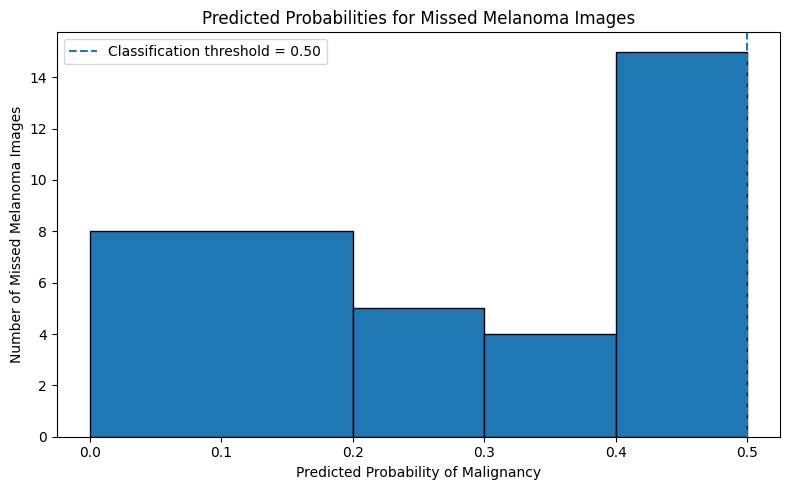

In [ ]:
# Step 26: Analyze confidence of missed melanoma predictions

import pandas as pd
import matplotlib.pyplot as plt

# Select missed melanoma images
missed_melanoma_df = false_negatives_df[
    false_negatives_df["dx"] == "mel"
].copy()

# Categorize predicted malignant probabilities
missed_melanoma_df["Probability Range"] = pd.cut(
    missed_melanoma_df["malignant_probability"],
    bins=[0.0, 0.2, 0.3, 0.4, 0.5],
    labels=[
        "0.00–0.20",
        "0.20–0.30",
        "0.30–0.40",
        "0.40–0.50"
    ],
    include_lowest=True
)

probability_summary = (
    missed_melanoma_df["Probability Range"]
    .value_counts()
    .sort_index()
)

print("Missed melanoma images by predicted probability:")
display(
    probability_summary
    .rename_axis("Probability Range")
    .reset_index(name="Number of Images")
)

print("\nSummary statistics:")
print(
    missed_melanoma_df["malignant_probability"]
    .describe()
    .round(3)
)

# Visualize the probability distribution
plt.figure(figsize=(8, 5))

plt.hist(
    missed_melanoma_df["malignant_probability"],
    bins=[0.0, 0.2, 0.3, 0.4, 0.5],
    edgecolor="black"
)

plt.axvline(
    x=0.5,
    linestyle="--",
    label="Classification threshold = 0.50"
)

plt.xlabel("Predicted Probability of Malignancy")
plt.ylabel("Number of Missed Melanoma Images")
plt.title("Predicted Probabilities for Missed Melanoma Images")
plt.legend()
plt.tight_layout()
plt.show()

# Interpreting the above results
-> 15/32 -> near the threshold (0.40-0.50)
    -> 46.9% of missed melanomas

-> 8/32 -> very low scores (below 0.20)
    -> 25% of missed melanomas

# Through this, we can identify two patterns:
1. Nearly half of the missed melanomas have predicted probabilities between 0.40 and 0.50. These are relatively close to our classification threshold. Lowering the threshold could recover some of them, although it would also introduce additional false positives.

2. Eight missed melanomas received probabilities below 0.20. These are particularly interesting because the model assigned them very low malignant scores. Lowering the threshold slightly would not recover these cases.

The average predicted probability among missed melanoma images was 0.331.

This suggests that threshold optimization alone may not address all the model's errors.

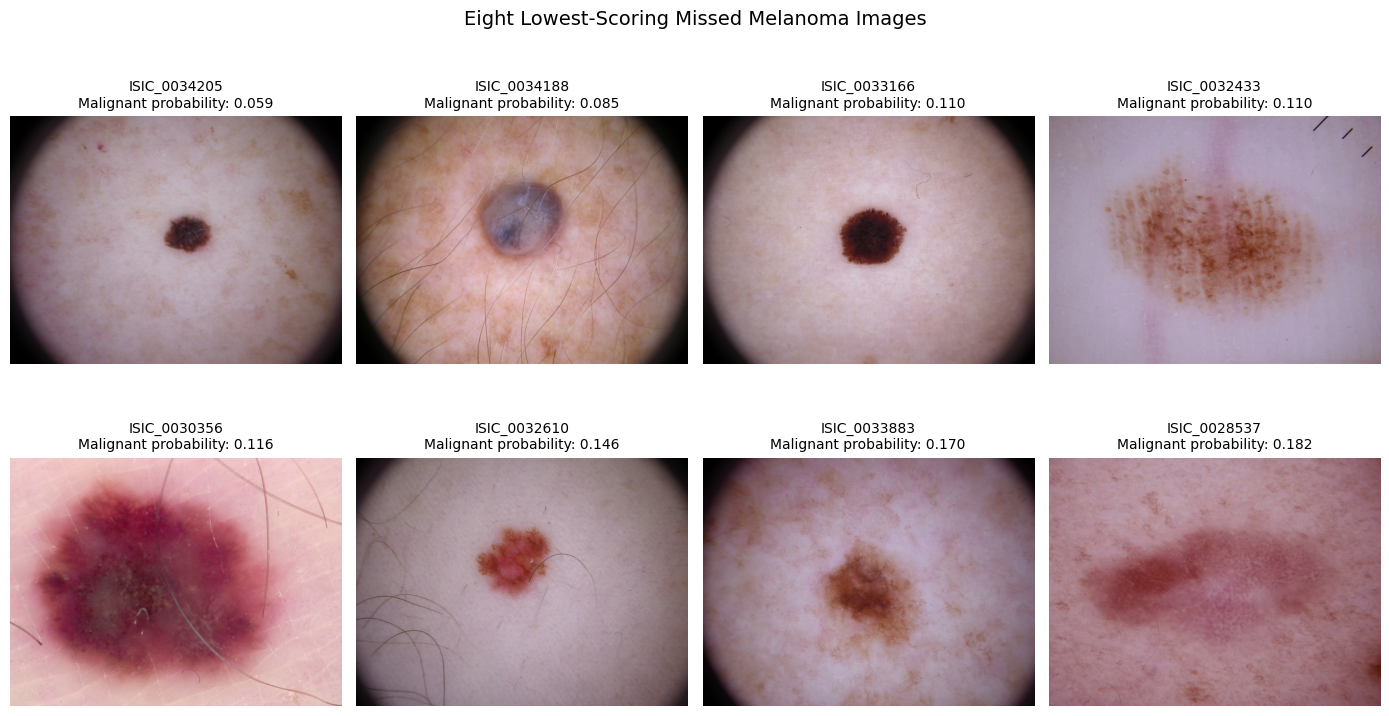

In [ ]:
# Step 27: Visualize missed melanoma images
# with the lowest predicted malignant probabilities

import matplotlib.pyplot as plt
from PIL import Image

# Select 8 missed melanoma images with the lowest scores
lowest_confidence_melanomas = (
    missed_melanoma_df
    .sort_values("malignant_probability")
    .head(8)
)

fig, axes = plt.subplots(2, 4, figsize=(14, 8))

for ax, (_, row) in zip(
    axes.flat,
    lowest_confidence_melanomas.iterrows()
):
    image = Image.open(row["image_path"]).convert("RGB")

    ax.imshow(image)
    ax.set_title(
        f"{row['image_id']}\n"
        f"Malignant probability: "
        f"{row['malignant_probability']:.3f}",
        fontsize=10
    )
    ax.axis("off")

plt.suptitle(
    "Eight Lowest-Scoring Missed Melanoma Images",
    fontsize=14
)

plt.tight_layout()
plt.show()

# Noticable things about the missed images:
1. Some lesions are relatively small and well-defined

ISIC_0034205 (0.059) and ISIC_0033166 (0.110) have fairly compact, dark appearances. Their low predicted malignant scores suggest that the model may not be recognizing some relevant features.



2. There are differences in pigmentation and appearance

ISIC_0034188 (0.085) has blue-gray pigmentation, whereas ISIC_0032433 (0.110) has a lighter brown, more diffuse pattern. The model is making errors across visibly different appearances.

3. Some images contain hairs or other visual distractions

ISIC_0030356 (0.116) and ISIC_0032610 (0.146) contain visible hairs. These could potentially interfere with classification, although we cannot establish that they caused the errors.

4. The model is also missing lesions with irregular appearances

ISIC_0033883 (0.170) and ISIC_0028537 (0.182) have less sharply defined pigmentation patterns. This suggests the errors are not restricted to one obvious visual appearance.

An important limitation: these eight images were deliberately selected because they received the lowest malignant probabilities. They aren't a random sample, so we shouldn't generalize their characteristics to all melanoma errors.

# What does this mean in regards to improving the model?
- There isn't really a single characteristic that explains all eight errors.

- Instead, the most useful next experiment is to investigate whether melanoma is underrepresented in our training data relative to benign lesions and whether our current weighting strategy adequately addresses that imbalance.


The current binary classifier uses class weights of approximately:
- Benign: 0.6005
- Malignant: 2.9882

In [ ]:
# Step 28: Examine training dataset distribution by diagnosis

import pandas as pd

training_distribution = (
    train_df.groupby(["classification", "dx"])
    .agg(
        Number_of_Images=("image_id", "count"),
        Unique_Lesions=("lesion_id", "nunique")
    )
    .reset_index()
)

# Calculate percentage of the full training dataset
training_distribution["Percentage_of_Training_Data"] = (
    training_distribution["Number_of_Images"]
    / len(train_df)
    * 100
)

print("Training dataset distribution by diagnosis:")
display(
    training_distribution
    .sort_values(
        "Number_of_Images",
        ascending=False
    )
    .round(2)
)

print("\nTotal training images:", len(train_df))

print("\nBinary classification distribution:")
display(
    train_df["classification"]
    .value_counts()
    .rename_axis("Classification")
    .reset_index(name="Number of Images")
)

Training dataset distribution by diagnosis:


,classification,dx,Number_of_Images,Unique_Lesions,Percentage_of_Training_Data
2,Benign,nv,4719,3776,69.26
0,Benign,bkl,778,516,11.42
5,Malignant,mel,773,423,11.35
4,Malignant,bcc,367,236,5.39
3,Benign,vasc,98,68,1.44
1,Benign,df,78,50,1.14



Total training images: 6813

Binary classification distribution:


,Classification,Number of Images
0,Benign,5673
1,Malignant,1140


# Important findings
1. Benign images dominate the dataset. We have 5,673 benign images compared with 1,140 malignant images, a ratio of approximately 5:1. Our existing class-weighted loss already attempts to compensate for this imbalance.

2. Melanoma is not underrepresented relative to BCC. We actually have more melanoma images (773) than BCC images (367). Yet our validation sensitivity is substantially lower for melanoma.

3. Melanoma may be more difficult for our model to distinguish from benign lesions. This is a plausible explanation, not something we've proven. Differences in visual characteristics, diagnostic diversity, and image quality could all contribute.

# Next steps
-> I will run one carefully controlled experiment with diagnosis-aware sampling

-> I will investigate whether giving melanoma examples more emphasis during training improves melanoma sensitivity

In [ ]:
# Step 29: Examine malignant training composition

import pandas as pd

malignant_training_df = train_df[
    train_df["classification"] == "Malignant"
].copy()

malignant_composition = (
    malignant_training_df["dx"]
    .value_counts()
    .rename_axis("Diagnosis")
    .reset_index(name="Training Images")
)

malignant_composition["Percentage of Malignant Images"] = (
    malignant_composition["Training Images"]
    / len(malignant_training_df)
    * 100
)

print("Composition of malignant training images:")
display(malignant_composition.round(2))

print("\nUnique lesions by malignant diagnosis:")
display(
    malignant_training_df.groupby("dx")["lesion_id"]
    .nunique()
    .rename("Unique Lesions")
    .reset_index()
)

print("\nCurrent binary class weights:")
print("Benign: 0.6005")
print("Malignant: 2.9882")

Composition of malignant training images:


,Diagnosis,Training Images,Percentage of Malignant Images
0,mel,773,67.81
1,bcc,367,32.19



Unique lesions by malignant diagnosis:


,dx,Unique Lesions
0,bcc,236
1,mel,423



Current binary class weights:
Benign: 0.6005
Malignant: 2.9882


# This means...
The model sees more melanoma examples than BCC examples, yet performs worse on melanoma.

We have already investigated:
- 1. additional fine-tuning
- 2. threshold optimization
- 3. diagnosis specific errors
- 4. prediction confidence
- 5. training class imbalance

In [ ]:
# Step 30: Evaluate malignant detection at lesion level

import pandas as pd
from sklearn.metrics import recall_score

# Use original model predictions from Step 24
malignant_lesion_df = (
    error_analysis_df[
        error_analysis_df["true_label"] == 1
    ]
    .groupby(["lesion_id", "dx"])
    .agg(
        Mean_Malignant_Probability=(
            "malignant_probability", "mean"
        ),
        Number_of_Images=("image_id", "count")
    )
    .reset_index()
)

# Classify each lesion using mean probability
malignant_lesion_df["Predicted_Malignant"] = (
    malignant_lesion_df["Mean_Malignant_Probability"] >= 0.50
).astype(int)

# Calculate lesion-level sensitivity by diagnosis
lesion_performance = (
    malignant_lesion_df.groupby("dx")
    .agg(
        Total_Lesions=("lesion_id", "count"),
        Correctly_Detected=(
            "Predicted_Malignant", "sum"
        )
    )
    .reset_index()
)

lesion_performance["Missed_Lesions"] = (
    lesion_performance["Total_Lesions"]
    - lesion_performance["Correctly_Detected"]
)

lesion_performance["Sensitivity (%)"] = (
    lesion_performance["Correctly_Detected"]
    / lesion_performance["Total_Lesions"]
    * 100
)

print("Lesion-level malignant sensitivity:")
display(lesion_performance.round(2))

print("\nOverall lesion-level malignant sensitivity:")
print(
    f"{malignant_lesion_df['Predicted_Malignant'].mean() * 100:.2f}%"
)

Lesion-level malignant sensitivity:


,dx,Total_Lesions,Correctly_Detected,Missed_Lesions,Sensitivity (%)
0,bcc,44,42,2,95.45
1,mel,97,78,19,80.41



Overall lesion-level malignant sensitivity:
85.11%


## Selected model and referral strategy


# FINAL MODEL.

We've completed three meaningful stages of model development and evaluation:
1. Original augmented ResNet-18: Our strongest established baseline, with 77.85% validation balanced accuracy and 86.06% malignant sensitivity.


2. Additional fine-tuning and threshold optimization: Produced only a 0.116-percentage-point improvement in balanced accuracy, without convincing statistical evidence of improvement.


3. Error analysis: Identified substantially lower melanoma sensitivity, examined misclassified images, investigated training imbalance, and confirmed the pattern at lesion level.






We have enough evidence to discuss both the strengths and limitations of our approach. More training could be investigated in future work, particularly using diagnosis-aware objectives or additional melanoma data, but we don't have a sufficiently strong reason to launch another experiment now.

We'll save five files:
1. validation_error_analysis.csv — Predictions, probabilities, and classification outcomes for all 1,460 validation images.

2. missed_melanoma_images.csv — The 32 incorrectly classified melanoma images.

3. diagnosis_performance.csv — Image-level sensitivity for melanoma and BCC.

4. lesion_level_performance.csv — Lesion-level sensitivity for both diagnoses.

5. training_diagnosis_distribution.csv — Training image counts and unique lesions by diagnosis.

In [ ]:
# Step 31: Save Experiment 3 error-analysis results

import os
import pandas as pd

# Create a separate folder for Experiment 3
experiment3_folder = (
    "/content/drive/MyDrive/ENGG680/"
    "Experiment3_Error_Analysis"
)

os.makedirs(experiment3_folder, exist_ok=True)

# Organize all results into separate CSV files
experiment3_results = {
    "validation_error_analysis.csv": error_analysis_df,
    "missed_melanoma_images.csv": missed_melanoma_df,
    "diagnosis_performance.csv": diagnosis_performance,
    "lesion_level_performance.csv": lesion_performance,
    "lesion_level_predictions.csv": malignant_lesion_df,
    "training_diagnosis_distribution.csv": training_distribution
}

# Save each DataFrame
for filename, dataframe in experiment3_results.items():

    filepath = os.path.join(
        experiment3_folder,
        filename
    )

    dataframe.to_csv(filepath, index=False)

    print(
        f"Saved: {filename} "
        f"({len(dataframe)} rows)"
    )

print("\nExperiment 3 results saved successfully!")
print("Folder:", experiment3_folder)

Saved: validation_error_analysis.csv (1460 rows)
Saved: missed_melanoma_images.csv (32 rows)
Saved: diagnosis_performance.csv (2 rows)
Saved: lesion_level_performance.csv (2 rows)
Saved: lesion_level_predictions.csv (141 rows)
Saved: training_diagnosis_distribution.csv (6 rows)

Experiment 3 results saved successfully!
Folder: /content/drive/MyDrive/ENGG680/Experiment3_Error_Analysis


## Report figures and final outputs


# Figures that need to be generated
MODEL TRAINING AND PERFORMANCE:
1. Training and validation loss (main report)
  - shows how our ResNet-18 learned over the training epochs, helping us discuss covergence and posible overfitting

2. Final classification confusion matrix (main report)
  - shows our original augmented model's true positives, false positives, true negatives, and false negatives using the 0,50 classification threshold

3. ROC curve (main report)
  - illustrates sensitivity versus false-positive rate across classification thresholds. the original model's validation ROC-AUC was approximately 0.863

REFERRAL SYSTEM EVALUATION

4. Referral threshold comparison (main report)
  - compares the referral strategies we evaluated, including 0.80 and 0.95, using their verified results. we will show how the referral rate and malignant case converage change

5. Final classification and referral workflow (main report)
  - a flowchart showing how the 0.50 classification threshold and 0.80 referral confidence threshold work together

MODEL OPTIMIZATION AND ERROR ANALYSIS

6. Original versus fine-tuned ResNet-18 (appendix/discussion)
  - compares balanced accuracy and malignant sensitivity, demonstrating that additional fine-tuning did not produce a convincing improvement

7. Melanoma versus BCC sensitivity (appendix/ discussion)
  - compares image-level and lesion-level sensitivity, highlighting the model's lower sensitivity for melanoma



Will also make:
- final model performance table
  - including:
      - accuracy
      - balanced accuracy
      - malignant sensitivity
      - specificity
      - ROC-AUC
      - with independent test results clearly distinguished from validation results

In [ ]:
# Reconnect Google Drive and verify our saved files
# Step 32: Restore access to saved ENGG 680 results

from google.colab import drive
import os

# Mount Google Drive
drive.mount("/content/drive")

# Define our project folder
project_folder = "/content/drive/MyDrive/ENGG680"

# Check that our original model checkpoint exists
original_checkpoint = os.path.join(
    project_folder,
    "resnet18_best_augmented.pt"
)

# Check that Experiment 3 results exist
experiment3_folder = os.path.join(
    project_folder,
    "Experiment3_Error_Analysis"
)

print("\nOriginal model checkpoint found:",
      os.path.exists(original_checkpoint))

print("Experiment 3 folder found:",
      os.path.exists(experiment3_folder))

print("\nSaved Experiment 3 files:")

if os.path.exists(experiment3_folder):
    for filename in sorted(os.listdir(experiment3_folder)):
        print("-", filename)
else:
    print("Folder not found!")

Mounted at /content/drive

Original model checkpoint found: True
Experiment 3 folder found: True

Saved Experiment 3 files:
- diagnosis_performance.csv
- lesion_level_performance.csv
- lesion_level_predictions.csv
- missed_melanoma_images.csv
- training_diagnosis_distribution.csv
- validation_error_analysis.csv


In [ ]:
# Step 33: Restore original ResNet-18 validation predictions

import os
import numpy as np
import pandas as pd

# Load saved validation error analysis
validation_results_path = os.path.join(
    experiment3_folder,
    "validation_error_analysis.csv"
)

validation_results = pd.read_csv(validation_results_path)

# Restore true labels and predicted probabilities
original_y_true = validation_results[
    "true_label"
].to_numpy(dtype=int)

original_y_prob = validation_results[
    "malignant_probability"
].to_numpy(dtype=float)

# Apply our original classification threshold
original_y_pred = (
    original_y_prob >= 0.50
).astype(int)

# Verify our original results
from sklearn.metrics import (
    confusion_matrix,
    balanced_accuracy_score,
    recall_score,
    roc_auc_score
)

tn, fp, fn, tp = confusion_matrix(
    original_y_true,
    original_y_pred,
    labels=[0, 1]
).ravel()

assert (tn, fp, fn, tp) == (
    842, 367, 35, 216
), "Saved predictions do not match original results!"

print("Original ResNet-18 validation predictions restored!")
print("Validation images:", len(original_y_true))

print("\nConfusion matrix:")
print("True negatives:", tn)
print("False positives:", fp)
print("False negatives:", fn)
print("True positives:", tp)

print(
    "\nBalanced accuracy:",
    f"{balanced_accuracy_score(original_y_true, original_y_pred) * 100:.2f}%"
)

print(
    "Malignant sensitivity:",
    f"{recall_score(original_y_true, original_y_pred) * 100:.2f}%"
)

print(
    "ROC-AUC:",
    f"{roc_auc_score(original_y_true, original_y_prob):.4f}"
)

Original ResNet-18 validation predictions restored!
Validation images: 1460

Confusion matrix:
True negatives: 842
False positives: 367
False negatives: 35
True positives: 216

Balanced accuracy: 77.85%
Malignant sensitivity: 86.06%
ROC-AUC: 0.8634


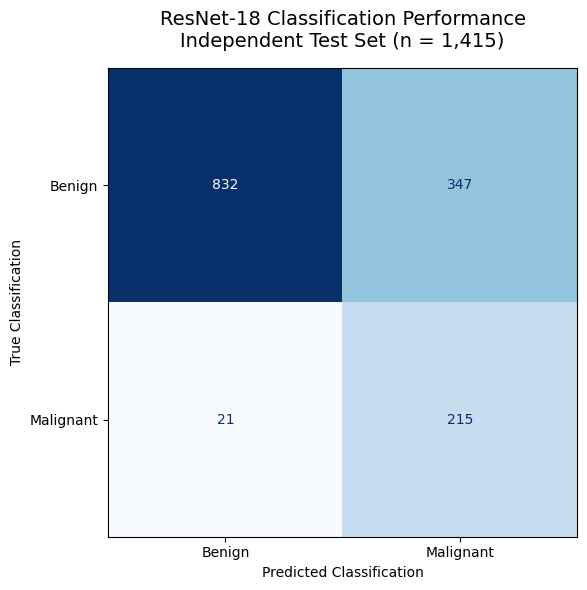

Figure 1 saved successfully!
Folder: /content/drive/MyDrive/ENGG680/Final_Report_Figures


In [ ]:
# Step 34: Save final independent test confusion matrix

import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Folder for final report figures
figures_folder = (
    "/content/drive/MyDrive/ENGG680/"
    "Final_Report_Figures"
)

os.makedirs(figures_folder, exist_ok=True)

# Previously verified independent test results
# Original augmented ResNet-18, threshold = 0.50
test_cm = np.array([
    [832, 347],
    [21, 215]
])

assert test_cm.sum() == 1415

fig, ax = plt.subplots(figsize=(7, 6))

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=test_cm,
    display_labels=["Benign", "Malignant"]
)

display_cm.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title(
    "ResNet-18 Classification Performance\n"
    "Independent Test Set (n = 1,415)",
    fontsize=14,
    pad=15
)

ax.set_xlabel("Predicted Classification")
ax.set_ylabel("True Classification")

plt.tight_layout()

# Save figure
for extension in ["png", "pdf"]:
    plt.savefig(
        os.path.join(
            figures_folder,
            f"Figure_1_Test_Confusion_Matrix.{extension}"
        ),
        dpi=300,
        bbox_inches="tight"
    )

plt.show()

print("Figure 1 saved successfully!")
print("Folder:", figures_folder)

*Figure 1. Confusion matrix for the original augmented ResNet-18 model evaluated on the independent test dataset (n = 1,415) using a classsification threshold of 0.50. The model correctly classified 215 malignant and 832 benign images, achieving a malignant sensitivity of 91.10% and balanced accuracy of 80.83%.*


** This figure represents classification performance, not the separate 0.80 referral strategy.

In [ ]:
# Step 35: Locate saved test predictions and evaluation results

import os

project_folder = "/content/drive/MyDrive/ENGG680"

search_terms = [
    "test",
    "prediction",
    "probability",
    "roc",
    "evaluation",
    "history",
    "referral"
]

print("Relevant saved project files:\n")

for root, dirs, files in os.walk(project_folder):
    for filename in sorted(files):
        if any(term in filename.lower() for term in search_terms):
            print(os.path.join(root, filename))

Relevant saved project files:

/content/drive/MyDrive/ENGG680/ENGG 680 Original Data Processing.ipynb
/content/drive/MyDrive/ENGG680/resnet18_augmented_referral_analysis.csv
/content/drive/MyDrive/ENGG680/HAM10000_Splits/test.csv
/content/drive/MyDrive/ENGG680/Final_Test_Results/augmented_resnet18_referral_outcomes.png
/content/drive/MyDrive/ENGG680/Final_Test_Results/augmented_resnet18_roc_curve.png
/content/drive/MyDrive/ENGG680/Final_Test_Results/augmented_resnet18_test_predictions.csv
/content/drive/MyDrive/ENGG680/Final_Test_Results/calibrated_referral_confusion_matrix.png
/content/drive/MyDrive/ENGG680/Final_Test_Results/final_test_confidence_intervals.csv
/content/drive/MyDrive/ENGG680/Final_Test_Results/final_test_summary.csv
/content/drive/MyDrive/ENGG680/Final_Test_Results/resnet18_test_confusion_matrix.png
/content/drive/MyDrive/ENGG680/Final_Test_Results/resnet18_test_roc_curve.png
/content/drive/MyDrive/ENGG680/Final_Test_Results/validation_calibrated_vs_uncalibrated_refer

ROC curve found: True
Image dimensions: (2064, 1760)


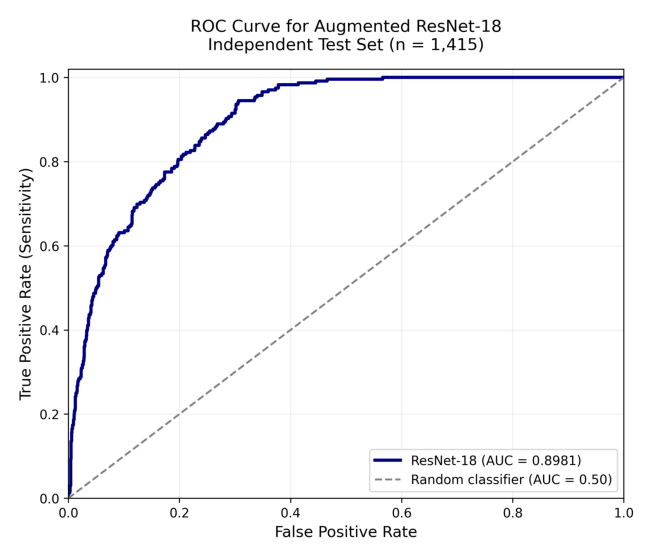

In [ ]:
# Step 36: Display previously saved test ROC curve

from PIL import Image
import matplotlib.pyplot as plt
import os

roc_path = (
    "/content/drive/MyDrive/ENGG680/"
    "Final_Test_Results/resnet18_test_roc_curve.png"
)

print("ROC curve found:", os.path.exists(roc_path))

if os.path.exists(roc_path):
    img = Image.open(roc_path)

    print("Image dimensions:", img.size)

    plt.figure(figsize=(9, 7))
    plt.imshow(img)
    plt.axis("off")
    plt.show()

 *Figure 2. Reciever operating characteristic (ROC) curve for the augmented ResNet-18 model evaluated on the independent test dataset (n = 1,415). The model achieved an area under the ROC curve (AUC) of 0.8981, demonstrating its ability to distinguish between benign an dmalignant skin lesions across classification thresholds. The dashed diagonal line represents random classification (AUC = 0.50).*

Referral figure found: True


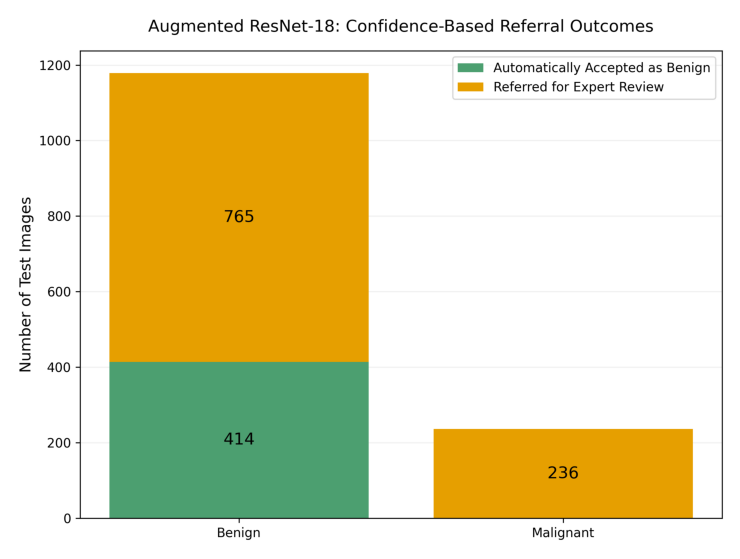

In [ ]:
# Step 37: Display existing referral outcomes figure

from PIL import Image
import matplotlib.pyplot as plt
import os

referral_path = (
    "/content/drive/MyDrive/ENGG680/"
    "Final_Test_Results/augmented_resnet18_referral_outcomes.png"
)

print("Referral figure found:", os.path.exists(referral_path))

if os.path.exists(referral_path):
    img = Image.open(referral_path)

    plt.figure(figsize=(10, 7))
    plt.imshow(img)
    plt.axis("off")
    plt.show()

*Figure 3. Confidence-based referral outcomes for the augmented ResNet-18 model evaluated on the independent test dataset (n = 1,415). Using a referral confidence threshold of 0.80, the system referred 1,001 images (70.74%) for expert review, including all 236 malignant images. The remaining 414 benign images were automatically accepted, illustrating the trade-off between reducig expert review workload and prioritizing potentially malignant lesions.*

In [ ]:
# Step 38: Inspect saved final test and referral results

import os
import pandas as pd

folder = "/content/drive/MyDrive/ENGG680/Final_Test_Results"

files_to_review = [
    "final_test_summary.csv",
    "validation_calibrated_vs_uncalibrated_referral.csv"
]

for filename in files_to_review:
    path = os.path.join(folder, filename)

    print(f"\n{'=' * 60}")
    print(filename)
    print(f"{'=' * 60}")

    if os.path.exists(path):
        df = pd.read_csv(path)
        print(df.to_string(index=False))
    else:
        print("File not found")


final_test_summary.csv
                           System     Evaluation  Malignant Sensitivity (%)  Malignant Missed  Overall Referral Rate (%)  ROC-AUC
         ResNet-18 Classification Classification                       91.1                21                        NaN   0.8981
ResNet-18 + Uncalibrated Referral       Referral                      100.0                 0                      70.74      NaN
  ResNet-18 + Calibrated Referral       Referral                      100.0                 0                      87.92      NaN

validation_calibrated_vs_uncalibrated_referral.csv
                   Model  Malignant Referred  Malignant Missed  Benign Referred  Referral Rate (%)  Malignant Referral Sensitivity (%)
Version 1 - Uncalibrated                 242                 9              660              61.78                               96.41
  Version 2 - Calibrated                 249                 2              831              73.97                               99.20

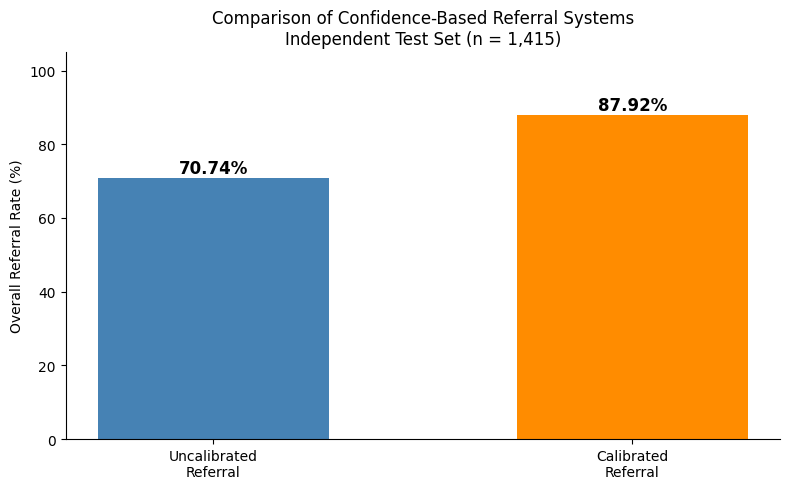

Figure 4 saved successfully!


In [ ]:
# Step 39: Compare final test referral systems

import os
import pandas as pd
import matplotlib.pyplot as plt

results_folder = (
    "/content/drive/MyDrive/ENGG680/Final_Test_Results"
)

figures_folder = (
    "/content/drive/MyDrive/ENGG680/Final_Report_Figures"
)

os.makedirs(figures_folder, exist_ok=True)

# Load saved test results
df = pd.read_csv(
    os.path.join(results_folder, "final_test_summary.csv")
)

# Include referral systems only
referral_df = df[df["Evaluation"] == "Referral"].copy()

labels = [
    "Uncalibrated\nReferral",
    "Calibrated\nReferral"
]

rates = referral_df["Overall Referral Rate (%)"].to_numpy()

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    labels,
    rates,
    color=["steelblue", "darkorange"],
    width=0.55
)

for bar, rate in zip(bars, rates):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        rate + 1.5,
        f"{rate:.2f}%",
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

ax.set_ylim(0, 105)
ax.set_ylabel("Overall Referral Rate (%)")
ax.set_title(
    "Comparison of Confidence-Based Referral Systems\n"
    "Independent Test Set (n = 1,415)"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

for extension in ["png", "pdf"]:
    plt.savefig(
        os.path.join(
            figures_folder,
            f"Figure_4_Referral_Comparison.{extension}"
        ),
        dpi=300,
        bbox_inches="tight"
    )

plt.show()

print("Figure 4 saved successfully!")

*Figure 4. Comparison of overall referral rates for the uncalibrated and calibrated confidence-based referral systems evaluated on the independent test dataset (n = 1,415). The uncalibrated system referred 70.74% of images for expert review, compared with 87.92% for the calibrated system. Both systems referred all malignant images in the test dataset, demonstrating a difference in referral workload without an observed difference in malignant referral sensitivity.*


*** Important note: calibration performaed better on validation malignant referral sensitivity (99.20% versus 96.41%), so we should acknowledge that trade-off rather than conclude the uncalibrated system is always superior.

In [ ]:
# Step 40: Locate original augmented ResNet-18 training history

import os

project_folder = "/content/drive/MyDrive/ENGG680"

print("Potential training history files:\n")

for root, dirs, files in os.walk(project_folder):
    for filename in sorted(files):
        name = filename.lower()

        if any(term in name for term in [
            "history",
            "training",
            "loss",
            "augmented"
        ]):
            print(os.path.join(root, filename))

Potential training history files:

/content/drive/MyDrive/ENGG680/resnet18_augmented_calibration_settings.json
/content/drive/MyDrive/ENGG680/resnet18_augmented_recovery.pt
/content/drive/MyDrive/ENGG680/resnet18_augmented_referral_analysis.csv
/content/drive/MyDrive/ENGG680/resnet18_best_augmented.pt
/content/drive/MyDrive/ENGG680/Final_Test_Results/augmented_resnet18_bootstrap_95CI.csv
/content/drive/MyDrive/ENGG680/Final_Test_Results/augmented_resnet18_calibration_plot.png
/content/drive/MyDrive/ENGG680/Final_Test_Results/augmented_resnet18_confusion_matrix.png
/content/drive/MyDrive/ENGG680/Final_Test_Results/augmented_resnet18_final_performance_table.csv
/content/drive/MyDrive/ENGG680/Final_Test_Results/augmented_resnet18_final_summary.json
/content/drive/MyDrive/ENGG680/Final_Test_Results/augmented_resnet18_referral_outcomes.png
/content/drive/MyDrive/ENGG680/Final_Test_Results/augmented_resnet18_roc_curve.png
/content/drive/MyDrive/ENGG680/Final_Test_Results/augmented_resnet18_t

In [ ]:
# Step 41: Inspect original augmented ResNet-18 recovery checkpoint

import os
import torch

checkpoint_path = (
    "/content/drive/MyDrive/ENGG680/"
    "resnet18_augmented_recovery.pt"
)

print("Checkpoint found:", os.path.exists(checkpoint_path))

if os.path.exists(checkpoint_path):

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    print("\nCheckpoint contents:")

    if isinstance(checkpoint, dict):
        for key, value in checkpoint.items():
            print(f"{key}: {type(value).__name__}")

    else:
        print("Checkpoint type:", type(checkpoint).__name__)

    if isinstance(checkpoint, dict) and "history" in checkpoint:
        print("\nTraining history:")
        print(checkpoint["history"])

Checkpoint found: True

Checkpoint contents:
epoch: int
model_state_dict: OrderedDict
optimizer_state_dict: dict
best_val_score: float
history: list

Training history:
[{'epoch': 1, 'train_loss': 0.4145972876187972, 'val_loss': 0.4178072598699021, 'val_balanced_accuracy': 0.7730681904309973, 'val_malignant_recall': 0.7330677290836654}, {'epoch': 2, 'train_loss': 0.3850113322700538, 'val_loss': 0.43330431229447663, 'val_balanced_accuracy': 0.7741919007180542, 'val_malignant_recall': 0.7609561752988048}, {'epoch': 3, 'train_loss': 0.3771711606934227, 'val_loss': 0.5491087320732744, 'val_balanced_accuracy': 0.7785005552644674, 'val_malignant_recall': 0.8605577689243028, 'val_roc_auc': 0.8634345990726917}]


Original training history:
 epoch  train_loss  val_loss  val_balanced_accuracy  val_malignant_recall  val_roc_auc
     1    0.414597  0.417807               0.773068              0.733068          NaN
     2    0.385011  0.433304               0.774192              0.760956          NaN
     3    0.377171  0.549109               0.778501              0.860558     0.863435


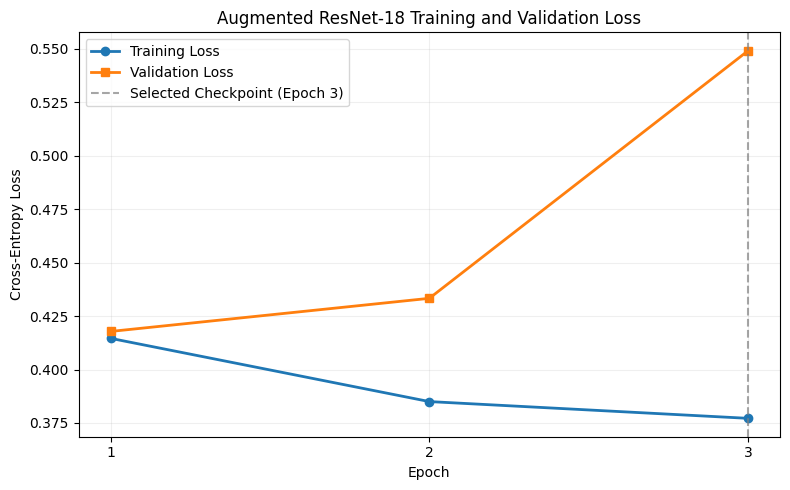


Figure 5 saved successfully!


In [ ]:
# Step 42: Original ResNet-18 training and validation loss

import os
import pandas as pd
import matplotlib.pyplot as plt

# Use history recovered in Step 41
history_df = pd.DataFrame(checkpoint["history"])

print("Original training history:")
print(history_df.to_string(index=False))

epochs = history_df["epoch"]

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    epochs,
    history_df["train_loss"],
    marker="o",
    linewidth=2,
    label="Training Loss"
)

ax.plot(
    epochs,
    history_df["val_loss"],
    marker="s",
    linewidth=2,
    label="Validation Loss"
)

ax.axvline(
    x=3,
    color="gray",
    linestyle="--",
    alpha=0.7,
    label="Selected Checkpoint (Epoch 3)"
)

ax.set_title(
    "Augmented ResNet-18 Training and Validation Loss"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Cross-Entropy Loss")
ax.set_xticks(epochs)
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()

# Save for final report
figures_folder = (
    "/content/drive/MyDrive/ENGG680/"
    "Final_Report_Figures"
)

os.makedirs(figures_folder, exist_ok=True)

for extension in ["png", "pdf"]:
    plt.savefig(
        os.path.join(
            figures_folder,
            f"Figure_5_Training_Validation_Loss.{extension}"
        ),
        dpi=300,
        bbox_inches="tight"
    )

plt.show()

print("\nFigure 5 saved successfully!")

Figure 5. Training and Validation Loss of the Augmeneted ResNet-18 Model.

*Training and validation cross-entropy loss across three training epochs. Training loss progressively decreased from 0.4146 to 0.3772, while validaiton loss increased from 0.4178 to 0.5491, sugeesting ptential overfitting. Despite the increase in validation loss, epoch 3 achieved the highest validation balanced accuracy (77.85%) and was selected as the final model checkpoint.*

In [ ]:
# Step 43: Inspect saved diagnosis-specific performance

import os
import pandas as pd

file_path = (
    "/content/drive/MyDrive/ENGG680/"
    "Experiment3_Error_Analysis/"
    "diagnosis_performance.csv"
)

print("File found:", os.path.exists(file_path))

if os.path.exists(file_path):
    diagnosis_df = pd.read_csv(file_path)

    print("\nDiagnosis-specific validation performance:")
    print(diagnosis_df.to_string(index=False))

    print("\nColumn names:")
    print(diagnosis_df.columns.tolist())

File found: True

Diagnosis-specific validation performance:
 dx  Total_Images  Correctly_Detected  Missed_Images  Unique_Lesions  Sensitivity (%)  False Negative Rate (%)
bcc            77                  74              3              44        96.103896                 3.896104
mel           174                 142             32              97        81.609195                18.390805

Column names:
['dx', 'Total_Images', 'Correctly_Detected', 'Missed_Images', 'Unique_Lesions', 'Sensitivity (%)', 'False Negative Rate (%)']


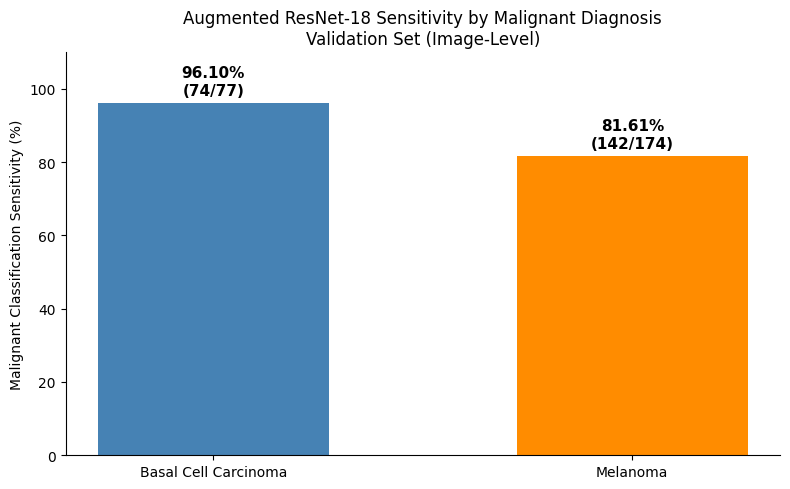

Figure 6 saved successfully!


In [ ]:
# Step 44: Diagnosis-specific malignant sensitivity

import os
import pandas as pd
import matplotlib.pyplot as plt

# Load saved validation results
file_path = (
    "/content/drive/MyDrive/ENGG680/"
    "Experiment3_Error_Analysis/"
    "diagnosis_performance.csv"
)

df = pd.read_csv(file_path)

# Arrange diagnoses for plotting
df["Diagnosis"] = df["dx"].map({
    "bcc": "Basal Cell Carcinoma",
    "mel": "Melanoma"
})

df = df.set_index("dx").loc[["bcc", "mel"]].reset_index()

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    df["Diagnosis"],
    df["Sensitivity (%)"],
    color=["steelblue", "darkorange"],
    width=0.55
)

# Add sensitivity and detection counts
for bar, (_, row) in zip(bars, df.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1.5,
        (
            f'{row["Sensitivity (%)"]:.2f}%\n'
            f'({int(row["Correctly_Detected"])}/'
            f'{int(row["Total_Images"])})'
        ),
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

ax.set_ylim(0, 110)
ax.set_ylabel("Malignant Classification Sensitivity (%)")
ax.set_title(
    "Augmented ResNet-18 Sensitivity by Malignant Diagnosis\n"
    "Validation Set (Image-Level)"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# Save figure
figures_folder = (
    "/content/drive/MyDrive/ENGG680/"
    "Final_Report_Figures"
)

os.makedirs(figures_folder, exist_ok=True)

for extension in ["png", "pdf"]:
    plt.savefig(
        os.path.join(
            figures_folder,
            f"Figure_6_Diagnosis_Sensitivity.{extension}"
        ),
        dpi=300,
        bbox_inches="tight"
    )

plt.show()

print("Figure 6 saved successfully!")

Figure 6. Diagnosis-Specific Malignant Classification Sensitivity of the Augmented ResNet-18 Model.

*Comparion of image-level classification sensitivity of basal cell carcinoma (BCC) and melanoma (MEL) in the validation dataset. The model correctly identified 74 of 77 BCC images (96.10%) and 142 of 174 melanoma images (81.61%). Melanoma accounted for 32 of the 35 malignant false-negative classifications, highlighting lower sensitivity for melanoma detection.*




*** Note: acknowledge that these results are image-level, meaning multiple images can originate from the same lesion

In [ ]:
# Step 45: Inspect lesion-level malignant classification results

import os
import pandas as pd

file_path = (
    "/content/drive/MyDrive/ENGG680/"
    "Experiment3_Error_Analysis/"
    "lesion_level_performance.csv"
)

print("File found:", os.path.exists(file_path))

if os.path.exists(file_path):
    lesion_df = pd.read_csv(file_path)

    print("\nLesion-level validation performance:")
    print(lesion_df.to_string(index=False))

    print("\nColumn names:")
    print(lesion_df.columns.tolist())

File found: True

Lesion-level validation performance:
 dx  Total_Lesions  Correctly_Detected  Missed_Lesions  Sensitivity (%)
bcc             44                  42               2        95.454545
mel             97                  78              19        80.412371

Column names:
['dx', 'Total_Lesions', 'Correctly_Detected', 'Missed_Lesions', 'Sensitivity (%)']


To further evaluate diagnosis-specific classification performance, sensitivity was calculated at the lesion level to account for multiple images originating from the same lesion. The augemented ResNet-18 model correctly identified 42 of 44 basal cell carcinoma lesions (95.45%) and 78 of 97 melanoma lesions (80.41%). These findings were consistent with the image-level analysis, indicating lower classification sensitivity of melanoma compared with basal cell carcinoma in the validation dataset.

In [ ]:
# Step 46: Review original vs additional fine-tuned model

import os
import pandas as pd

folder = (
    "/content/drive/MyDrive/ENGG680/"
    "Additional_Finetuning"
)

files = [
    "final_model_comparison.csv",
    "lesion_bootstrap_summary.csv"
]

for filename in files:
    path = os.path.join(folder, filename)

    print(f"\n{'=' * 60}")
    print(filename)
    print(f"{'=' * 60}")

    if os.path.exists(path):
        df = pd.read_csv(path)
        print(df.to_string(index=False))
    else:
        print("File not found")


final_model_comparison.csv
                 Model  Threshold  Balanced Accuracy (%)  Malignant Sensitivity (%)  True Positives  False Positives  True Negatives  False Negatives
    Original augmented       0.50              77.850056                  86.055777             216              367             842               35
Additional fine-tuning       0.38              77.966546                  86.454183             217              369             840               34

lesion_bootstrap_summary.csv
                         Comparison  Observed Difference (pp)  Mean Bootstrap Difference (pp)  95% CI Lower (pp)  95% CI Upper (pp)  Bootstrap Resamples
Fine-tuned 0.38 minus original 0.50                   0.11649                        0.135918          -1.254883           1.503766                 2000


Additional fine-tuning was evaluated to determine whether further optimization improved the augmented ResNet-18 model. On the validation dataset, the fine-tuned model achieved a balanced accuracy of 77.97% and malignant sensitivity of 86.45%, comapred with 77.85% and 80.06%, respectively, for the original model. Although additional fine-tuning resulted in a slight improvement in performance, lesion-level bootstrap analysis using 2,000 resamples produced a 95% confidence interval of -1.225 to +1.504 percentage points for the difference in balanced accuracy. As this interval included zero, the improvement was not considered sufficiently supported to justify replacing the original model. Therefore, the original augmented ResNet-18 was retrained for final evaluation.

In [ ]:
# Step 47: Inspect referral threshold and calibration settings

import os
import json
import pandas as pd

project_folder = "/content/drive/MyDrive/ENGG680"

settings_path = os.path.join(
    project_folder,
    "resnet18_augmented_calibration_settings.json"
)

referral_path = os.path.join(
    project_folder,
    "resnet18_augmented_referral_analysis.csv"
)

print("=" * 60)
print("CALIBRATION SETTINGS")
print("=" * 60)

if os.path.exists(settings_path):
    with open(settings_path, "r") as f:
        settings = json.load(f)

    print(json.dumps(settings, indent=2))
else:
    print("Calibration settings file not found.")

print("\n" + "=" * 60)
print("REFERRAL ANALYSIS")
print("=" * 60)

if os.path.exists(referral_path):
    referral_df = pd.read_csv(referral_path)

    print("Columns:")
    print(referral_df.columns.tolist())

    print("\nFirst 10 rows:")
    print(referral_df.head(10).to_string(index=False))

    print("\nTotal rows:", len(referral_df))
else:
    print("Referral analysis file not found.")

CALIBRATION SETTINGS
{
  "model": "ResNet18_augmented_epoch3",
  "checkpoint": "resnet18_best_augmented.pt",
  "temperature": 1.6472741540516778,
  "calibration_images": 729,
  "evaluation_images": 731,
  "uncalibrated_brier": 0.18779783794714544,
  "calibrated_brier": 0.17969222954635286,
  "uncalibrated_ece": 0.07744846135255577,
  "calibrated_ece": 0.02206257951895614,
  "uncalibrated_nll": 0.5709568988377653,
  "calibrated_nll": 0.5322601576691566,
  "candidate_referral_threshold": 0.8,
  "threshold_status": "Preliminary; selected using validation data",
  "calibration_method": "Temperature scaling"
}

REFERRAL ANALYSIS
Columns:
['Threshold', 'Accepted', 'Referred', 'Referral Rate (%)', 'Malignant Referred', 'Malignant Missed']

First 10 rows:
 Threshold  Accepted  Referred  Referral Rate (%)  Malignant Referred  Malignant Missed
      0.70       271       460              62.93                 120                 1
      0.75       233       498              68.13                 

# What has been confirmed:
1. Referral threshold: 0.80
2. Calibration method: Temperature scaling
3. Separate calibration evaluation

# Why we selected 0.80
- At 0.80, the system referred every malignant image in this 731-image evaluation subset while requiring fewer referrals than the higher thresholds.

# Did calibration improve the probability estimates?
- Brier score, expected calibration error (ECE), and negative log-likelihood (NLL) all three metrics improved after temperature scaling. (Lower valyes indicate better perfromance for the three measures) ***however, improved probability calibration does not automatically mean improved classification sensitivity or referral efficiency. The separate referral comparisons illustrate that distinction.

# Methodology:
**Confidence-Based Referral**

A confidence-based referral system was developed to identify skin lesion images requiring expert review. Images were automatically accepted only when the model predicted a benign lesion with a confidence score greater than or equal to a specific referral threshold. All images classified as malignant, as well as benign predicitions with insufficient confidence, were referred for expert review. Candidate referral confidence thresholds ranging from 0.70 to 0.95 were evaluated using validation data. A preliminary threshold of 0.80 was selected because it referred all 121 malignant images while maintaining a lower overall referral rate than higher thresholds. The selected threshold was subsequently evaluated on the independent test dataset.

**Confidence-Based Referral and Probability Calibration**

A confidence-based referral system was developed to identify skin lesion images requiring expert review. Candidate referral confidence thresholds ranging from 0.70 to 0.95 were evaluated using validation data. A threshold of 0.80 was selected as a preliminary operating point because it referred all 121 malignant images in the 731-image evaluation subset while requiring fewer referrals than higher thresholds. Probability calibration was also investigated using temperature scaling, with a fitted temperature of 1.6473. Calibration was assessed using the Brier score, expected calibration error (ECE), and negative log-likelihood (NLL). All three metrics improved following calibration, indicating improved probability calibration on the evaluation subset. The uncalibrated and calibrated referral systems were subsequently compared using the independent test dataset.

**Probability Calibration**

Probability calibration was investigated using temperature scaling to adjust the confidence of the augmented ResNet-18 model without retraining its parameters or changing its predicted class labels. The validation dataset (n = 1,460) was divided into a calibration subset (n = 729) and an evaluation subset (n = 731), using a lesion-level grouping procedure designed to prevent images originating from the same lesion from appearing in both subsets. The temperature parameter (T = 1.6473) was fitted using the calibration subset, and calibration performance was assessed using the evaluation subset. Model confidence was evaluated using the Brier score, expected calibration error (ECE), and negative log-likelihood (NLL). The calibrated probabilities were subsequently used to investigate confidence-based referral thresholds ranging from 0.70 to 0.95, with 0.80 selected as the preliminary operating threshold.